# Operação XPTO: da base bruta à verdade analítica (Vendas, E-commerce)

**Objetivo deste notebook:** transformar a base bruta de vendas da XPTO em uma base analítica confiável, documentando cada problema encontrado, cada decisão tomada e o impacto dessas decisões nos indicadores de negócio.

**Sumário**

1. Extração da base
2. Inspeção inicial
3. *Data profiling*
4. Diagnóstico da qualidade
5. Decisões sobre os problemas
6. Limpeza e transformação
7. Criação de atributos
8. Comparação RAW × CLEAN
9. Perguntas de negócio
10. Geração da base final
11. Pergunta final sobre produção

Checklist final do trabalho

## 0.1 Ambiente: bibliotecas e configurações

O notebook usa apenas bibliotecas já disponíveis no Google Colab — `pandas`, `numpy`, `matplotlib` e `seaborn` — além de módulos da biblioteca padrão do Python (`urllib`, `io`, `re`, `collections`). Nenhuma instalação adicional é necessária.

As versões são impressas para fins de **reprodutibilidade**: alguns detalhes de exibição (por exemplo, o nome do tipo textual, `object` ou `str`, e o consumo de memória de colunas de texto) variam entre versões do `pandas`, sem alterar o conteúdo dos dados.

In [1]:
import io
import re
import sys
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Exibição mais legível das tabelas
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print(f"Python : {sys.version.split()[0]}")
print(f"pandas : {pd.__version__}")
print(f"numpy  : {np.__version__}")

Python : 3.14.7
pandas : 3.0.5
numpy  : 2.5.2


# 1. Extração da base

## 1.1 Contexto: por que ler direto da fonte

A base é lida **diretamente da URL pública** do repositório, sem downloads manuais nem arquivos intermediários. Isso garante que qualquer pessoa, em um ambiente limpo, obtenha exatamente a mesma entrada e, portanto, a mesma base final.

Antes de chamar `pd.read_csv`, porém, é preciso **descobrir** os parâmetros de leitura — separador de campos, separador decimal, *encoding* e cabeçalho. Assumir os padrões do `pandas` (vírgula como separador, ponto como decimal) é uma fonte clássica de erros silenciosos: a leitura "funciona", mas produz colunas coladas ou números lidos como texto.

In [2]:
URL_BASE = "https://raw.githubusercontent.com/alvaroriz/datascience_datasets/refs/heads/main/BaseVendasXPTO.csv"

## 1.2 Inspeção dos bytes brutos: *encoding* e quebra de linha

O primeiro passo é olhar o arquivo **como bytes**, antes de qualquer interpretação. Os três primeiros bytes revelam se há um BOM — *Byte Order Mark*, marcador invisível que alguns programas (como o Excel) gravam no início de arquivos UTF-8. Se ele não for tratado, o nome da primeira coluna é lido com um caractere oculto (`\ufeffDataVenda` em vez de `DataVenda`).

In [3]:
# Leitura dos bytes apenas para inspeção (o DataFrame será criado com pd.read_csv na etapa 1.4)
with urllib.request.urlopen(URL_BASE) as resposta:
    bytes_brutos = resposta.read()

BOM_UTF8 = b"\xef\xbb\xbf"
n_crlf = bytes_brutos.count(b"\r\n")

print(f"Tamanho do arquivo : {len(bytes_brutos):,} bytes")
print(f"Primeiros 3 bytes  : {bytes_brutos[:3]!r}")
print(f"Possui BOM UTF-8   : {bytes_brutos.startswith(BOM_UTF8)}")
print(f"Quebras de linha CRLF (Windows): {n_crlf:,}")

Tamanho do arquivo : 2,514,725 bytes
Primeiros 3 bytes  : b'\xef\xbb\xbf'
Possui BOM UTF-8   : True
Quebras de linha CRLF (Windows): 28,506


In [4]:
# Teste de decodificação: UTF-8 falha se o arquivo estiver em Latin-1/CP1252 com acentos
try:
    texto_bruto = bytes_brutos.decode("utf-8-sig")
    print("Decodificação UTF-8 bem-sucedida (BOM removido pelo codec 'utf-8-sig').")
except UnicodeDecodeError as erro:
    print(f"Falha em UTF-8: {erro}")

# Os acentos só aparecem corretamente se o encoding estiver certo
acentuadas = sorted(set(re.findall(r"\w*[áéíóúâêôãõçÁÉÍÓÚÂÊÔÃÕÇ]\w*", texto_bruto)))
print(f"Palavras acentuadas encontradas no arquivo: {acentuadas}")

Decodificação UTF-8 bem-sucedida (BOM removido pelo codec 'utf-8-sig').


Palavras acentuadas encontradas no arquivo: ['Bancário', 'Cartão', 'Crédito', 'xptoourfemcalçaecintockjutm_medium']


## 1.3 Descoberta do separador e do formato decimal

Com o texto decodificado, inspecionamos as primeiras linhas e contamos, em **todas** as linhas, quantas vezes cada separador candidato aparece. Um separador correto aparece o mesmo número de vezes em todas as linhas (número de colunas − 1).

In [5]:
linhas = texto_bruto.splitlines()
print(f"Total de linhas no arquivo (incluindo cabeçalho): {len(linhas):,}\n")
for linha in linhas[:6]:
    print(linha)

Total de linhas no arquivo (incluindo cabeçalho): 28,506

DataVenda;ValorVenda;IdFormaDePagamento;FormaPagamento;TipoFormaPagamento;NumeroParcelas;Cliente_Codigo;Cliente_Data_Nascimento;UF_Cliente;CanalVenda
2011-05-05 12:14:00;69,00;1;Boleto Bancário;Boleto Bancário;1;1;2008-01-01;RJ;UOLBOTAOMAR
2011-05-10 16:20:00;442,80;1;Boleto Bancário;Boleto Bancário;1;1;2008-01-01;RJ;Opote
2011-05-15 22:42:00;269,00;1;Boleto Bancário;Boleto Bancário;1;1;2008-01-01;RJ;
2011-07-08 18:52:00;199,00;2;Visa;Cartão de Crédito;1;1;2008-01-01;RJ;
2011-02-11 12:54:00;522,50;3;MasterCard;Cartão de Crédito;10;43;1960-06-23;MA;xptoourNcl1


In [6]:
# Quantas ocorrências de cada separador candidato existem por linha?
candidatos = [";", ",", "\t", "|"]
resumo_sep = pd.DataFrame({
    "separador": [repr(c) for c in candidatos],
    "ocorrencias_por_linha (distribuição)": [dict(Counter(l.count(c) for l in linhas)) for c in candidatos],
})
resumo_sep

,separador,ocorrencias_por_linha (distribuição)
0,';',{9: 28506}
1,"','","{0: 1, 1: 28374, 2: 131}"
2,'\t',{0: 28506}
3,'|',{0: 28506}


A tabela acima deixa claro o papel de cada caractere:

- **`;` é o separador de campos:** aparece exatamente 9 vezes em todas as linhas, o que corresponde a 10 colunas, sem nenhuma linha "quebrada".
- **`,` não é separador de campos:** sua contagem varia entre as linhas (1 na maioria, 2 em algumas); se fosse usada como separador, parte das linhas teria uma coluna a mais.

A variação da vírgula merece ser explicada, e não apenas ignorada. A célula abaixo verifica **em quais campos** ela aparece.

In [7]:
# Em quais colunas a vírgula aparece? (divisão pelo separador já confirmado)
cabecalho = linhas[0].lstrip("\ufeff").split(";")
registros_brutos = [l.split(";") for l in linhas[1:]]

virgula_por_coluna = Counter(
    col for reg in registros_brutos for col, valor in zip(cabecalho, reg) if "," in valor
)
print(f"Linhas com vírgula, por coluna: {dict(virgula_por_coluna)}\n")

pos_canal = cabecalho.index("CanalVenda")
exemplos = [reg[pos_canal] for reg in registros_brutos if "," in reg[pos_canal]][:5]
print("Exemplos de CanalVenda com vírgula:", exemplos)

Linhas com vírgula, por coluna: {'ValorVenda': 28505, 'CanalVenda': 131}

Exemplos de CanalVenda com vírgula: ['xptopolosliH, xptopolosliH', 'xptolnM, xptolnM', 'xptoLS, xptoLS', 'xptockjncl, xptockjncl', 'xptockjncl, xptockjncl']


**Diagnóstico:** a vírgula aparece em **todas** as linhas dentro de `ValorVenda` — é o **separador decimal** — e, adicionalmente, em algumas linhas dentro de `CanalVenda`, onde o valor aparece **repetido e separado por vírgula** (ex.: `xptoLS, xptoLS`). Isso **não é um problema de leitura**: como o separador de campos é `;`, essas vírgulas ficam contidas no próprio campo. Trata-se de um problema de **conteúdo** do canal, registrado para a seção 7.5.

Para confirmar o formato numérico, vale olhar o **padrão** dos valores de `ValorVenda` (cada dígito vira `9`). Assim fica visível se há separador de milhar (ex.: `1.234,56`), que exigiria o parâmetro `thousands`.

In [8]:
# Padrão textual dos valores monetários: cada dígito é substituído por '9'
pos_valor = cabecalho.index("ValorVenda")
valores_texto = [reg[pos_valor] for reg in registros_brutos]

padroes_valor = Counter(re.sub(r"\d", "9", v) for v in valores_texto)
pd.DataFrame(padroes_valor.most_common(), columns=["padrao_ValorVenda", "quantidade"])

,padrao_ValorVenda,quantidade
0,"999,99",22753
1,"99,99",4695
2,"9999,99",961
3,"999,999",46
4,"9,99",16
5,"99,999",12
6,"99,9999",8
7,"999,9999",7
8,"9999,999",3
9,"99999,99",3


Os padrões mostram que **não existe separador de milhar** (nenhum ponto aparece, nem em valores com cinco dígitos inteiros) e que a vírgula é sempre o decimal. Chama a atenção que alguns valores têm **três ou quatro casas decimais** (ex.: padrão `999,999`) — algo incomum para preços em reais. Isso não impede a leitura, mas fica registrado como ponto a investigar no *profiling* (seção 3).

O mesmo raciocínio aplicado às colunas de data mostra o formato usado:

In [9]:
# Padrão textual das colunas de data (dígitos -> '9'; campo vazio -> '<vazio>')
for coluna in ["DataVenda", "Cliente_Data_Nascimento"]:
    pos = cabecalho.index(coluna)
    padroes = Counter(re.sub(r"\d", "9", reg[pos]) or "<vazio>" for reg in registros_brutos)
    print(f"{coluna}: {dict(padroes)}")

DataVenda: {'9999-99-99 99:99:99': 28505}
Cliente_Data_Nascimento: {'9999-99-99': 25872, 'NULL': 2633}


O formato de `DataVenda` é uniforme (`AAAA-MM-DD hh:mm:ss`) em todas as linhas. Já `Cliente_Data_Nascimento` revela algo importante: os nascimentos ausentes **não estão vazios** — estão preenchidos com o **texto literal `NULL`**.

## 1.4 Representação de ausentes: o que conta como "vazio"

Por padrão, o `pandas` converte silenciosamente para `NaN` uma lista de marcadores (`""`, `"NULL"`, `"NA"`, `"null"`, `"N/A"`, `"None"`, entre outros). Isso é conveniente, mas perigoso: um canal de venda legítimo chamado `"NA"` seria apagado sem aviso. Por isso, verificamos **quais marcadores de ausência existem de fato** no arquivo, coluna a coluna.

In [10]:
# Marcadores que o pandas trataria como ausentes por padrão (lista de pd.read_csv)
MARCADORES_NA_PADRAO = ["", "#N/A", "#N/A N/A", "#NA", "-1.#IND", "-1.#QNAN", "-NaN", "-nan",
                        "1.#IND", "1.#QNAN", "<NA>", "N/A", "NA", "NULL", "NaN", "None",
                        "n/a", "nan", "null"]

ocorrencias_na = Counter(
    (col, valor if valor else "<vazio>")
    for reg in registros_brutos
    for col, valor in zip(cabecalho, reg)
    if valor in MARCADORES_NA_PADRAO
)
tabela_na = pd.DataFrame(
    [(col, marcador, qtd) for (col, marcador), qtd in ocorrencias_na.items()],
    columns=["coluna", "marcador_no_arquivo", "quantidade"],
).sort_values(["coluna", "quantidade"], ascending=[True, False])
tabela_na

,coluna,marcador_no_arquivo,quantidade
0,CanalVenda,<vazio>,9444
2,CanalVenda,NULL,38
1,Cliente_Data_Nascimento,NULL,2633


**Diagnóstico:** apenas **dois marcadores** existem no arquivo — o campo vazio e o texto `NULL`. Os dois têm o mesmo significado (informação não registrada) e aparecem, inclusive, **misturados na mesma coluna** (`CanalVenda`). Nenhum outro marcador da lista padrão ocorre, portanto não há risco de apagar um valor legítimo.

**Solução adotada:** declarar explicitamente, na leitura, que somente `""` e `"NULL"` representam ausência (`keep_default_na=False` + `na_values=["", "NULL"]`). O resultado é idêntico ao padrão nesta base, mas a regra passa a ser **documentada e controlada**: se uma carga futura trouxer um canal chamado `"NA"`, ele será preservado como texto.

## 1.5 Leitura com parâmetros explícitos e criação do `df_raw`

Com base nas evidências acima, a leitura usa os seguintes parâmetros, todos declarados explicitamente:

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `sep` | `";"` | 9 ocorrências em todas as linhas → 10 colunas consistentes |
| `decimal` | `","` | `ValorVenda` usa vírgula decimal, sem separador de milhar |
| `encoding` | `"utf-8-sig"` | Arquivo em UTF-8 com BOM; o sufixo `-sig` remove o BOM do nome da primeira coluna |
| `header` | `0` | A primeira linha contém os nomes das variáveis |
| `keep_default_na` / `na_values` | `False` / `["", "NULL"]` | Apenas esses dois marcadores de ausência existem no arquivo (1.4) |

**Deliberadamente, nenhuma conversão de tipo é feita na leitura** (por exemplo, `parse_dates`). A leitura deve refletir o arquivo tal como ele é; as conversões são decisões de preparação e serão feitas — e justificadas — sobre a cópia de trabalho.

**O conceito de camada RAW:** o `df_raw` é a "fotografia fiel" da fonte. Ele **nunca é alterado** ao longo do notebook; toda limpeza acontece em uma cópia (`df_clean`, criada na seção 6). Isso permite: (i) auditar qualquer transformação comparando antes e depois; (ii) refazer decisões sem reler a fonte; e (iii) calcular os indicadores da seção 8 sobre os dados originais. Para garantir que o RAW permanece intocado, guardamos uma **impressão digital** (*hash*) do conteúdo, que será conferida ao final.

In [11]:
PARAMETROS_LEITURA = {
    "sep": ";",
    "decimal": ",",
    "encoding": "utf-8-sig",
    "header": 0,
    "keep_default_na": False,
    "na_values": ["", "NULL"],
}

df_raw = pd.read_csv(URL_BASE, **PARAMETROS_LEITURA)

# Impressão digital do RAW para verificar, ao final, que ele não foi modificado
HASH_RAW = pd.util.hash_pandas_object(df_raw, index=True).sum()

print(f"df_raw criado: {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")
print(f"Hash do conteúdo RAW: {HASH_RAW}")

df_raw criado: 28,505 linhas x 10 colunas
Hash do conteúdo RAW: 14142524782292839979


Uma verificação de sanidade confirma que: (i) todas as linhas do arquivo foram carregadas; (ii) o nome da primeira coluna não carrega o BOM; e (iii) a quantidade de ausentes por coluna é exatamente a contagem de marcadores encontrada em 1.4.

In [12]:
assert len(df_raw) == len(linhas) - 1, "Número de linhas lidas difere do arquivo"
assert df_raw.columns[0] == "DataVenda", "Primeira coluna com caractere oculto (BOM)"
assert list(df_raw.columns) == cabecalho, "Colunas divergentes do cabeçalho bruto"
ausentes_esperados = tabela_na.groupby("coluna")["quantidade"].sum()
assert df_raw.isna().sum()[ausentes_esperados.index].equals(ausentes_esperados), "Ausentes divergentes"
print("Leitura consistente com o arquivo bruto: todas as linhas e colunas foram carregadas.")
df_raw.head()

Leitura consistente com o arquivo bruto: todas as linhas e colunas foram carregadas.


,DataVenda,ValorVenda,IdFormaDePagamento,FormaPagamento,TipoFormaPagamento,NumeroParcelas,Cliente_Codigo,Cliente_Data_Nascimento,UF_Cliente,CanalVenda
0,2011-05-05 12:14:00,69.00,1,Boleto Bancário,Boleto Bancário,1,1,2008-01-01,RJ,UOLBOTAOMAR
1,2011-05-10 16:20:00,442.80,1,Boleto Bancário,Boleto Bancário,1,1,2008-01-01,RJ,Opote
2,2011-05-15 22:42:00,269.00,1,Boleto Bancário,Boleto Bancário,1,1,2008-01-01,RJ,NaN
3,2011-07-08 18:52:00,199.00,2,Visa,Cartão de Crédito,1,1,2008-01-01,RJ,NaN
4,2011-02-11 12:54:00,522.50,3,MasterCard,Cartão de Crédito,10,43,1960-06-23,MA,xptoourNcl1


# 2. Inspeção inicial

## 2.1 Dimensões: registros e atributos

A primeira pergunta é o tamanho da base: quantas vendas (linhas) e quantas características de cada venda (colunas) estão disponíveis.

In [13]:
n_registros, n_atributos = df_raw.shape
print(f"Número de registros : {n_registros:,}")
print(f"Número de atributos : {n_atributos}")

Número de registros : 28,505
Número de atributos : 10


## 2.2 Variáveis e tipos inferidos

A tabela abaixo reúne, para cada coluna, o tipo que o `pandas` inferiu automaticamente, a quantidade de valores preenchidos e um exemplo real. Ela é o ponto de partida para avaliar se a inferência automática foi adequada (subseção 2.5).

In [14]:
visao_tipos = pd.DataFrame({
    "tipo_inferido": df_raw.dtypes.astype(str),
    "preenchidos": df_raw.notna().sum(),
    "ausentes": df_raw.isna().sum(),
    "distintos": df_raw.nunique(dropna=True),
    "exemplo": df_raw.iloc[0],
})
visao_tipos.index.name = "variavel"
visao_tipos

,tipo_inferido,preenchidos,ausentes,distintos,exemplo
variavel,,,,,
DataVenda,str,28505,0,26523,2011-05-05 12:14:00
ValorVenda,float64,28505,0,4078,69.00
IdFormaDePagamento,int64,28505,0,6,1
FormaPagamento,str,28505,0,6,Boleto Bancário
TipoFormaPagamento,str,28505,0,4,Boleto Bancário
NumeroParcelas,int64,28505,0,11,1
Cliente_Codigo,int64,28505,0,13737,1
Cliente_Data_Nascimento,str,25872,2633,7777,2008-01-01
UF_Cliente,str,28505,0,27,RJ


## 2.3 Memória utilizada

O consumo de memória é medido com `deep=True`, que contabiliza o conteúdo real das strings. Em versões do `pandas` anteriores à 3.0, colunas de texto (`object`) guardam apenas ponteiros, e sem `deep=True` o consumo fica subestimado; a partir da 3.0, o texto é armazenado em formato colunar (Arrow) e as duas medidas tendem a coincidir. Por isso, o valor exato depende da versão impressa em 0.1 — o que importa aqui é a **proporção** entre colunas.

In [15]:
memoria = df_raw.memory_usage(deep=True).drop("Index")
tabela_memoria = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "memoria_KB": (memoria / 1024).round(1),
    "participacao_%": (memoria / memoria.sum() * 100).round(1),
}).sort_values("memoria_KB", ascending=False)

print(f"Memória total (deep=True) : {memoria.sum() / 1024**2:.2f} MB")
print(f"Memória total (deep=False): {df_raw.memory_usage(deep=False).drop('Index').sum() / 1024**2:.2f} MB")
tabela_memoria

Memória total (deep=True) : 3.90 MB
Memória total (deep=False): 3.90 MB


,tipo,memoria_KB,participacao_%
DataVenda,str,751.60,18.80
TipoFormaPagamento,str,722.50,18.10
Cliente_Data_Nascimento,str,478.80,12.00
FormaPagamento,str,478.60,12.00
CanalVenda,str,388.40,9.70
UF_Cliente,str,278.40,7.00
ValorVenda,float64,222.70,5.60
IdFormaDePagamento,int64,222.70,5.60
NumeroParcelas,int64,222.70,5.60
Cliente_Codigo,int64,222.70,5.60


## 2.4 Período temporal da base

Como `DataVenda` foi lida como texto, o período é medido convertendo a coluna **em uma variável temporária**, sem alterar o `df_raw`. O parâmetro `format` é explícito (o padrão `9999-99-99 99:99:99` foi confirmado em 1.3) e `errors="coerce"` transforma qualquer valor inválido em `NaT`, permitindo contá-los em vez de interromper a execução.

In [16]:
# Conversão temporária, apenas para medir o período (df_raw permanece como texto)
data_venda_tmp = pd.to_datetime(df_raw["DataVenda"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

print(f"Datas inválidas (NaT)  : {data_venda_tmp.isna().sum()}")
print(f"Primeira venda         : {data_venda_tmp.min()}")
print(f"Última venda           : {data_venda_tmp.max()}")
print(f"Amplitude do período   : {(data_venda_tmp.max() - data_venda_tmp.min()).days} dias")

Datas inválidas (NaT)  : 0
Primeira venda         : 2011-01-10 00:17:00
Última venda           : 2011-08-28 23:15:00
Amplitude do período   : 230 dias


A contagem mensal ajuda a verificar se todos os meses estão completos — informação importante para não comparar um mês parcial com um mês cheio na análise de evolução das vendas (seção 9.1).

In [17]:
vendas_mes = pd.DataFrame({
    "vendas": data_venda_tmp.dt.to_period("M").value_counts().sort_index(),
    "primeiro_dia": data_venda_tmp.groupby(data_venda_tmp.dt.to_period("M")).min().dt.day,
    "ultimo_dia": data_venda_tmp.groupby(data_venda_tmp.dt.to_period("M")).max().dt.day,
})
vendas_mes.index.name = "mes"
vendas_mes

,vendas,primeiro_dia,ultimo_dia
mes,,,
2011-01,2426,10,31
2011-02,3395,1,28
2011-03,3142,1,31
2011-04,2984,1,30
2011-05,3801,1,31
2011-06,3977,1,30
2011-07,4983,1,31
2011-08,3797,1,28


**Leitura do resultado:** a base cobre **oito meses de 2011**, de janeiro a agosto, sem nenhuma data inválida. Porém, **dois meses são parciais**: janeiro começa no dia 10 e agosto termina no dia 28. Comparar volumes mensais brutos sem considerar isso subestimaria esses meses; a análise de evolução (9.1) deverá usar uma medida normalizada, como a média de vendas por dia.

## 2.5 Diagnóstico: a leitura automática produziu tipos adequados?

**Não.** A leitura acertou os tipos de apenas parte das colunas. O tipo inferido pelo `pandas` reflete a **aparência** dos valores (só dígitos → inteiro; qualquer letra → texto), e não o **significado** de cada variável. A célula abaixo reúne as evidências que sustentam cada correção proposta.

In [18]:
# Evidências para a revisão de tipos
print("Colunas de data lidas como texto:")
print(f"  DataVenda               -> tipo {df_raw['DataVenda'].dtype}, exemplo {df_raw['DataVenda'].iloc[0]!r}")
print(f"  Cliente_Data_Nascimento -> tipo {df_raw['Cliente_Data_Nascimento'].dtype}, exemplo {df_raw['Cliente_Data_Nascimento'].iloc[0]!r}")

print("\nCódigos lidos como números (operações aritméticas não fazem sentido):")
print(f"  Cliente_Codigo     -> tipo {df_raw['Cliente_Codigo'].dtype}, 'média' = {df_raw['Cliente_Codigo'].mean():,.1f} (sem significado)")
print(f"  IdFormaDePagamento -> tipo {df_raw['IdFormaDePagamento'].dtype}, valores {sorted(df_raw['IdFormaDePagamento'].unique().tolist())}")

print("\nTexto com poucas categorias (candidatas a 'category'):")
for c in ["FormaPagamento", "TipoFormaPagamento", "UF_Cliente"]:
    print(f"  {c:<19}-> {df_raw[c].nunique()} categorias distintas em {len(df_raw):,} linhas")

print(f"\nCanalVenda -> {df_raw['CanalVenda'].nunique()} valores distintos (texto livre, exige normalização)")

Colunas de data lidas como texto:
  DataVenda               -> tipo str, exemplo '2011-05-05 12:14:00'
  Cliente_Data_Nascimento -> tipo str, exemplo '2008-01-01'

Códigos lidos como números (operações aritméticas não fazem sentido):
  Cliente_Codigo     -> tipo int64, 'média' = 486,603.8 (sem significado)
  IdFormaDePagamento -> tipo int64, valores [1, 2, 3, 4, 6, 7]

Texto com poucas categorias (candidatas a 'category'):
  FormaPagamento     -> 6 categorias distintas em 28,505 linhas
  TipoFormaPagamento -> 4 categorias distintas em 28,505 linhas
  UF_Cliente         -> 27 categorias distintas em 28,505 linhas

CanalVenda -> 602 valores distintos (texto livre, exige normalização)


| Variável | Tipo inferido | Tipo adequado | Precisa corrigir? | Justificativa |
|---|---|---|---|---|
| `DataVenda` | texto | `datetime64` | **Sim** | Sem conversão não é possível ordenar cronologicamente, extrair mês/hora ou calcular idade na data da compra |
| `ValorVenda` | `float64` | `float64` | Não (tipo correto) | O parâmetro `decimal=","` garantiu a leitura numérica; as casas decimais excedentes são questão de **conteúdo**, tratada no *profiling* |
| `IdFormaDePagamento` | `int64` | `category` | **Sim** | É um **código**, não uma quantidade: somar ou tirar a média de IDs não tem significado |
| `FormaPagamento` | texto | `category` | **Sim** (otimização) | Domínio pequeno e fechado; `category` reduz memória e explicita o domínio |
| `TipoFormaPagamento` | texto | `category` | **Sim** (otimização) | Mesmo motivo de `FormaPagamento` |
| `NumeroParcelas` | `int64` | `int64` | Não (tipo correto) | É uma contagem; o valor `0` observado na distribuição será investigado como problema de **conteúdo** |
| `Cliente_Codigo` | `int64` | texto / `category` | **Sim** | Identificador: a "média" calculada acima não significa nada; tratá-lo como texto impede agregações indevidas |
| `Cliente_Data_Nascimento` | texto | `datetime64` | **Sim** | Necessário para calcular idade; os ausentes viram `NaT` |
| `UF_Cliente` | texto | `category` | **Sim** (otimização) | Domínio fechado (unidades federativas) |
| `CanalVenda` | texto | texto | Não (tipo correto) | O tipo é adequado, mas o **conteúdo** é texto livre com alta cardinalidade; o tratamento é de normalização (seção 7.5), não de tipo |

**Conclusão:** das 10 variáveis, **2 datas** precisam ser convertidas obrigatoriamente, **2 códigos** estão com tipo numérico enganoso e **3 colunas categóricas** se beneficiam do tipo `category`. Apenas `ValorVenda`, `NumeroParcelas` e `CanalVenda` têm tipo adequado — e mesmo nelas o **conteúdo** traz sinais que serão investigados na seção 3. As conversões serão aplicadas no `df_clean` (seções 6 e 7), nunca no `df_raw`.

# 3. *Data profiling*

## 3.1 Contexto: o que o *profiling* procura

*Data profiling* é a descrição sistemática de cada atributo: quanto está preenchido, quais valores assume, como se distribui. O objetivo não é "achar erros" de forma genérica, mas responder a perguntas concretas: há ausentes? Há valores sentinela, isto é, preenchimentos artificiais que imitam um dado real? As categorias equivalentes estão escritas do mesmo jeito? As colunas concordam entre si? A granularidade é a esperada?

A seção está dividida em duas partes:

- **Visão consolidada (3.2 e 3.3):** uma tabela com as estatísticas de todas as colunas e as frequências das principais categorias.
- **Busca ativa (3.4 a 3.13):** uma investigação dirigida para cada tipo de problema, sempre com o código que produz a evidência.

Nenhuma alteração é feita no `df_raw`. As conversões necessárias para medir datas e idades são feitas em **séries auxiliares**, descartáveis.

In [19]:
# Séries auxiliares para o profiling (df_raw permanece intocado)
FORMATOS_DATA = {"DataVenda": "%Y-%m-%d %H:%M:%S", "Cliente_Data_Nascimento": "%Y-%m-%d"}

aux_venda = pd.to_datetime(df_raw["DataVenda"], format=FORMATOS_DATA["DataVenda"], errors="coerce")
aux_nasc = pd.to_datetime(df_raw["Cliente_Data_Nascimento"],
                          format=FORMATOS_DATA["Cliente_Data_Nascimento"], errors="coerce")


def idade_na_data(nascimento, referencia):
    # Idade completa em anos na data de referência (NaN se o nascimento for ausente)
    anos = referencia.dt.year - nascimento.dt.year
    ainda_nao_fez = (referencia.dt.month * 100 + referencia.dt.day) < (nascimento.dt.month * 100 + nascimento.dt.day)
    return (anos - ainda_nao_fez.astype(int)).where(nascimento.notna()).astype("Int64")


# Idade exata na data da compra, calculada sobre o RAW (sentinelas e datas impossíveis incluídas).
# A mesma função é usada na seção 7.2, para que RAW e CLEAN sejam comparáveis pelo mesmo método.
aux_idade = idade_na_data(aux_nasc, aux_venda)

print(f"Datas de venda não convertidas     : {aux_venda.isna().sum()}")
print(f"Nascimentos não convertidos        : {aux_nasc.isna().sum()} "
      f"(ausentes na origem: {df_raw['Cliente_Data_Nascimento'].isna().sum()})")

Datas de venda não convertidas     : 0
Nascimentos não convertidos        : 2633 (ausentes na origem: 2633)


A quantidade de nascimentos não convertidos é igual à de ausentes na origem: **todas as datas preenchidas estão em formato válido**. Os problemas de data, se existirem, serão de **conteúdo**, não de formato.

## 3.2 Visão consolidada: perfil por coluna

O perfil depende do **tipo semântico** de cada coluna, definido na seção 2.5, e não do tipo que o `pandas` inferiu. Média e quartis só fazem sentido para medidas (`ValorVenda`, `NumeroParcelas`) e para datas; para códigos e categorias, o que interessa é o domínio e a frequência. A função `perfilar_coluna` aplica essa regra de forma genérica, e pode ser reutilizada em qualquer nova carga.

In [20]:
TIPO_SEMANTICO = {
    "DataVenda": "data",
    "ValorVenda": "numérico",
    "IdFormaDePagamento": "código",
    "FormaPagamento": "categórico",
    "TipoFormaPagamento": "categórico",
    "NumeroParcelas": "numérico",
    "Cliente_Codigo": "código",
    "Cliente_Data_Nascimento": "data",
    "UF_Cliente": "categórico",
    "CanalVenda": "texto livre",
}


def perfilar_coluna(serie, tipo, formato_data=None, n_top=3):
    # Perfil de uma coluna conforme o seu tipo semântico
    n = len(serie)
    ausentes = int(serie.isna().sum())
    perfil = {
        "tipo_semantico": tipo,
        "tipo_pandas": str(serie.dtype),
        "preenchidos": n - ausentes,
        "ausentes": ausentes,
        "ausentes_%": round(ausentes / n * 100, 2),
        "distintos": serie.nunique(dropna=True),
    }
    if tipo == "numérico":
        q1, mediana, q3 = serie.quantile([0.25, 0.50, 0.75])
        iqr = q3 - q1
        extremos = ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()
        perfil.update({"min": f"{serie.min():,.2f}", "q1": f"{q1:,.2f}", "mediana": f"{mediana:,.2f}",
                       "media": f"{serie.mean():,.2f}", "q3": f"{q3:,.2f}", "max": f"{serie.max():,.2f}",
                       "extremos_IQR": int(extremos)})
    elif tipo == "data":
        datas = pd.to_datetime(serie, format=formato_data, errors="coerce")
        q1, mediana, q3 = datas.quantile([0.25, 0.50, 0.75])
        fmt = lambda d: d.strftime("%Y-%m-%d")
        perfil.update({"min": fmt(datas.min()), "q1": fmt(q1), "mediana": fmt(mediana),
                       "media": fmt(datas.mean()), "q3": fmt(q3), "max": fmt(datas.max())})
    top = serie.value_counts().head(n_top)
    perfil["principais_valores (freq.)"] = "; ".join(f"{k} ({v:,})" for k, v in top.items())
    return perfil


perfil = pd.DataFrame({
    col: perfilar_coluna(df_raw[col], TIPO_SEMANTICO[col], FORMATOS_DATA.get(col))
    for col in df_raw.columns
}).T
perfil.index.name = "variavel"

with pd.option_context("display.max_colwidth", 80):
    display(perfil)

,tipo_semantico,tipo_pandas,preenchidos,ausentes,ausentes_%,distintos,min,q1,mediana,media,q3,max,principais_valores (freq.),extremos_IQR
variavel,,,,,,,,,,,,,,
DataVenda,data,str,28505,0,0.00,26523,2011-01-10,2011-03-15,2011-05-20,2011-05-13,2011-07-13,2011-08-28,2011-07-21 14:38:00 (5); 2011-06-06 17:26:00 (4); 2011-06-09 23:42:00 (4),NaN
ValorVenda,numérico,float64,28505,0,0.00,4078,0.00,129.00,217.90,314.61,361.80,"17,016.25","199.0 (1,205); 99.0 (796); 89.0 (729)",2083
IdFormaDePagamento,código,int64,28505,0,0.00,6,NaN,NaN,NaN,NaN,NaN,NaN,"2 (11,805); 3 (8,420); 1 (7,530)",NaN
FormaPagamento,categórico,str,28505,0,0.00,6,NaN,NaN,NaN,NaN,NaN,NaN,"Visa (11,805); MasterCard (8,420); Boleto Bancário (7,530)",NaN
TipoFormaPagamento,categórico,str,28505,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,"Cartão de Crédito (20,461); Boleto Bancário (7,530); Cupom (511)",NaN
NumeroParcelas,numérico,int64,28505,0,0.00,11,0.00,1.00,2.00,3.62,5.00,10.00,"1 (11,348); 10 (3,679); 2 (2,787)",0
Cliente_Codigo,código,int64,28505,0,0.00,13737,NaN,NaN,NaN,NaN,NaN,NaN,618107 (236); 597657 (109); 3850 (85),NaN
Cliente_Data_Nascimento,data,str,25872,2633,9.24,7777,1900-01-01,1973-02-13,1981-08-25,1978-03-31,1987-06-30,2011-12-16,1900-01-01 (266); 1990-02-07 (240); 1985-02-02 (114),NaN
UF_Cliente,categórico,str,28505,0,0.00,27,NaN,NaN,NaN,NaN,NaN,NaN,"SP (7,735); RJ (2,893); MG (2,627)",NaN


**Primeiras leituras da tabela consolidada:**

- **Ausentes:** apenas `Cliente_Data_Nascimento` (9,24%) e `CanalVenda` (33,26%) têm lacunas. No canal, **um terço das vendas** não tem origem registrada.
- **`ValorVenda`:** a média (314,61) fica bem acima da mediana (217,90), sinal de **assimetria à direita**, com uma cauda de vendas altas. O mínimo é **0,00** e o máximo **17.016,25**. A regra do IQR (intervalo interquartil) aponta 2.083 valores extremos.
- **`Cliente_Data_Nascimento`:** o mínimo é **1900-01-01**, data típica de preenchimento automático, e o máximo **2011-12-16**, **posterior ao fim da base** (agosto de 2011).
- **`Cliente_Codigo`:** 13.737 clientes para 28.505 vendas, e um único cliente aparece 236 vezes.
- **`CanalVenda`:** 602 valores distintos em texto livre, um volume incompatível com a quantidade real de canais de uma operação de e-commerce.

Esses sinais orientam a busca ativa das subseções seguintes.

## 3.3 Frequências: principais categorias

Para as colunas categóricas, a distribuição de frequências mostra o domínio efetivo e ajuda a identificar categorias raras, que podem ser erros ou casos especiais.

In [21]:
def frequencias(serie, n=10):
    # Frequência absoluta e relativa das n categorias mais comuns (ausentes incluídos)
    contagem = serie.value_counts(dropna=False).head(n)
    return pd.DataFrame({"quantidade": contagem,
                         "percentual": (contagem / len(serie) * 100).round(2)})


for coluna in ["FormaPagamento", "TipoFormaPagamento", "NumeroParcelas"]:
    print(f"\n=== {coluna} ===")
    display(frequencias(df_raw[coluna], n=15))


=== FormaPagamento ===


,quantidade,percentual
FormaPagamento,,
Visa,11805,41.41
MasterCard,8420,29.54
Boleto Bancário,7530,26.42
Cupom de Desconto,511,1.79
Diners,236,0.83
Glamour VIP,3,0.01



=== TipoFormaPagamento ===


,quantidade,percentual
TipoFormaPagamento,,
Cartão de Crédito,20461,71.78
Boleto Bancário,7530,26.42
Cupom,511,1.79
Pagamentos Glamour,3,0.01



=== NumeroParcelas ===


,quantidade,percentual
NumeroParcelas,,
1,11348,39.81
10,3679,12.91
2,2787,9.78
4,2586,9.07
3,2583,9.06
5,1727,6.06
6,1405,4.93
8,659,2.31
7,642,2.25


In [22]:
print("=== UF_Cliente (10 principais) ===")
display(frequencias(df_raw["UF_Cliente"]))
print("=== CanalVenda (10 principais) ===")
display(frequencias(df_raw["CanalVenda"]))

=== UF_Cliente (10 principais) ===


,quantidade,percentual
UF_Cliente,,
SP,7735,27.14
RJ,2893,10.15
MG,2627,9.22
CE,1387,4.87
BA,1355,4.75
PE,1207,4.23
MA,1095,3.84
SC,1088,3.82
RS,1062,3.73


=== CanalVenda (10 principais) ===


,quantidade,percentual
CanalVenda,,
NaN,9482,33.26
google,5593,19.62
HiMidia,1578,5.54
xptoourMasc1,626,2.20
AviseMe,444,1.56
xptoourFem1,443,1.55
visavale,246,0.86
xptoourFem2,241,0.85
xptoourNcl1,230,0.81


Três pontos merecem atenção:

- **`Glamour VIP`** (forma de pagamento) aparece em apenas 3 vendas. É uma categoria rara, mas consistente (seu tipo é `Pagamentos Glamour`). Por isso **não é um erro**: é um meio de pagamento de baixo uso.
- **`NumeroParcelas = 0`** ocorre em 585 vendas (2,05%). "Zero parcelas" não é um valor natural e será investigado em 3.8.
- **O maior "canal" de `CanalVenda` é a ausência de canal** (`NaN`, 9.482 vendas), maior até que `google` (5.593). Qualquer ranking de canais que ignore esse fato será distorcido.

## 3.4 Ausentes: onde estão e se seguem um padrão

Não basta contar ausentes. É preciso entender **em que nível** está a lacuna. No caso da data de nascimento, um atributo do **cliente**, e não da venda, vale verificar se a ausência é consistente por cliente: se um mesmo cliente tivesse a data em algumas vendas e não em outras, daria para recuperá-la a partir das outras vendas.

In [23]:
ausentes = pd.DataFrame({
    "ausentes": df_raw.isna().sum(),
    "ausentes_%": (df_raw.isna().mean() * 100).round(2),
})
display(ausentes[ausentes["ausentes"] > 0])

# O nascimento ausente é consistente por cliente? (algum cliente tem data em uma venda e não em outra?)
por_cliente = df_raw.groupby("Cliente_Codigo")["Cliente_Data_Nascimento"]
clientes_mistos = (por_cliente.apply(lambda s: s.isna().any() and s.notna().any())).sum()
clientes_sem_nasc = (por_cliente.apply(lambda s: s.isna().all())).sum()
datas_divergentes = (por_cliente.nunique() > 1).sum()

print(f"Clientes sem nenhuma data de nascimento           : {clientes_sem_nasc:,}")
print(f"Clientes com data em umas vendas e ausente em outras: {clientes_mistos}")
print(f"Clientes com mais de uma data de nascimento        : {datas_divergentes}")

,ausentes,ausentes_%
Cliente_Data_Nascimento,2633,9.24
CanalVenda,9482,33.26


Clientes sem nenhuma data de nascimento           : 1,551
Clientes com data em umas vendas e ausente em outras: 0
Clientes com mais de uma data de nascimento        : 0


**Diagnóstico:** a ausência de nascimento é uma característica do **cadastro do cliente**. Nenhum cliente tem a data em uma venda e ausente em outra, e nenhum tem duas datas diferentes. Por isso **não há como recuperar** esses valores a partir da própria base, e a ausência deve ser mantida e tratada como "não informado". O mesmo raciocínio vale para `CanalVenda`: a origem da venda não se infere de outra coluna.

## 3.5 Valores sentinela: datas de nascimento artificiais

Um **valor sentinela** é um preenchimento artificial que ocupa o lugar de um dado ausente. Por exemplo, sistemas que exigem uma data preenchida gravam `1900-01-01` quando o cliente não informa o nascimento. O sentinela é mais perigoso que o ausente, porque **parece um dado válido**: essa data produziria uma idade de 111 anos, e o cliente entraria no cálculo da idade média.

A evidência mais forte de um sentinela é a **concentração improvável**: muitos clientes *diferentes* compartilhando exatamente a mesma data.

In [24]:
# Datas de nascimento compartilhadas pelo maior número de clientes distintos
clientes_por_nasc = (df_raw.groupby("Cliente_Data_Nascimento")
                     .agg(clientes_distintos=("Cliente_Codigo", "nunique"),
                          vendas=("Cliente_Codigo", "size"))
                     .sort_values("clientes_distintos", ascending=False))
display(clientes_por_nasc.head(8))

mediana_clientes = clientes_por_nasc["clientes_distintos"].median()
print(f"Mediana de clientes distintos por data de nascimento: {mediana_clientes:.0f}")

,clientes_distintos,vendas
Cliente_Data_Nascimento,,
1900-01-01,141,266
1985-01-01,13,16
1992-10-10,12,14
1990-12-10,10,34
2010-01-01,9,23
1979-04-03,9,20
1985-08-15,8,9
1988-08-22,7,9


Mediana de clientes distintos por data de nascimento: 1


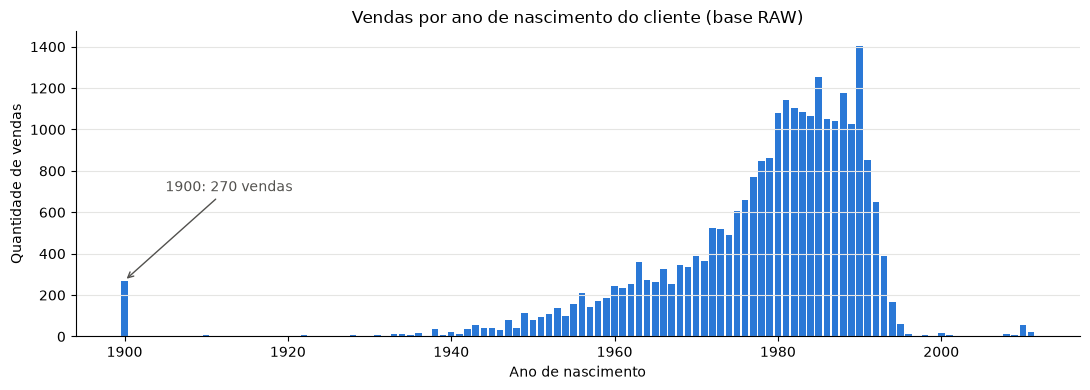

Datas com ano <= 1900:
Cliente_Data_Nascimento
1900-01-01    266
1900-11-11      4


In [25]:
# Distribuição dos anos de nascimento: o pico isolado em 1900 é visualmente evidente
nasc_por_ano = aux_nasc.dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(nasc_por_ano.index, nasc_por_ano.values, width=0.8, color="#2a78d6")
ax.set_title("Vendas por ano de nascimento do cliente (base RAW)")
ax.set_xlabel("Ano de nascimento")
ax.set_ylabel("Quantidade de vendas")
ax.annotate(f"1900: {nasc_por_ano.get(1900, 0)} vendas", xy=(1900, nasc_por_ano.get(1900, 0)),
            xytext=(1905, nasc_por_ano.max() * 0.5), color="#52514e",
            arrowprops={"arrowstyle": "->", "color": "#52514e"})
ax.grid(axis="y", color="#e5e5e3")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

anos_1900 = df_raw.loc[aux_nasc.dt.year <= 1900, "Cliente_Data_Nascimento"].value_counts()
print("Datas com ano <= 1900:")
print(anos_1900.to_string())

**Diagnóstico:**

- **Caso 1 — `1900-01-01` (o mais relevante):** 141 clientes distintos compartilham essa data, enquanto a data seguinte mais comum reúne só 13 (a mediana é 1 cliente por data). No gráfico, o ano de 1900 aparece como um pico isolado, separado do restante da distribuição por décadas quase vazias. Isso **não é um cliente centenário**: é um preenchimento padrão de sistema.
- **Caso 2 — `1900-11-11`:** 4 vendas. O que a define como sentinela é o **ano de 1900**, o mesmo valor-padrão do caso 1: nenhum cliente nascido nesse ano teria 110 anos e compraria pela internet em 2011. A regra adotada é, portanto, **objetiva e baseada no ano (≤ 1900)**, e não no formato da data.
- **Por que datas "bonitas" de outros anos não entram na regra:** existem nascimentos como `1910-10-10` (7 vendas, 1 cliente) e `1912-12-12` (1 venda), com o mesmo formato repetitivo. Eles são **suspeitos**, mas pertencem a um único cliente cada e produzem idades possíveis (100 e 98 anos). Diferentemente de `1900-01-01`, não há concentração entre clientes que prove preenchimento automático. Por isso são mantidos, e registrados aqui como ponto de atenção.
- **Caso 3 — datas `01-01` concentradas, como `1985-01-01` (13 clientes) e `2010-01-01` (9 clientes):** são suspeitas, mas **não conclusivas**. O primeiro de janeiro é um preenchimento comum quando só o ano é conhecido, mas também é uma data de nascimento real. Sem evidência forte, esses casos não serão tratados como sentinela. A de 2010 reaparece como idade improvável em 3.6.

## 3.6 Problemas em datas: idade na data da compra

A idade relevante para o negócio é a que o cliente tinha **no momento da compra**, não a idade atual. Cruzar `Cliente_Data_Nascimento` com `DataVenda` revela três situações: idades **impossíveis** (negativas), **improváveis** (crianças ou pessoas com mais de 100 anos comprando) e **plausíveis**.

Os limites usados no diagnóstico são **16 anos**, idade abaixo da qual uma compra autônoma com cartão ou boleto em nome próprio é pouco provável, e **100 anos**.

In [26]:
sentinela_1900 = aux_nasc.dt.year <= 1900

diagnostico_idade = pd.DataFrame({
    "situacao": ["Nascimento posterior à compra (idade < 0)",
                 "Idade entre 0 e 16 anos (improvável)",
                 "Idade acima de 100 anos, sem sentinela 1900 (improvável)",
                 "Sentinela 1900 (idade artificial)"],
    "vendas": [(aux_idade < 0).sum(),
               ((aux_idade >= 0) & (aux_idade < 16)).sum(),
               ((aux_idade > 100) & ~sentinela_1900).sum(),
               sentinela_1900.sum()],
})
display(diagnostico_idade)

print("Vendas com nascimento posterior à compra:")
display(df_raw.loc[aux_idade < 0, ["DataVenda", "Cliente_Codigo", "Cliente_Data_Nascimento"]])

,situacao,vendas
0,Nascimento posterior à compra (idade < 0),12
1,Idade entre 0 e 16 anos (improvável),172
2,"Idade acima de 100 anos, sem sentinela 1900 (i...",0
3,Sentinela 1900 (idade artificial),270


Vendas com nascimento posterior à compra:


,DataVenda,Cliente_Codigo,Cliente_Data_Nascimento
4148,2011-02-12 09:06:00,175884,2011-06-27
4149,2011-05-18 10:31:00,175884,2011-06-27
17032,2011-01-11 16:12:00,611500,2011-07-26
17033,2011-01-11 15:55:00,611500,2011-07-26
17034,2011-01-12 13:50:00,611500,2011-07-26
18441,2011-02-10 15:07:00,612643,2011-04-18
19562,2011-03-09 22:48:00,613631,2011-08-25
20404,2011-03-25 10:11:00,614288,2011-05-02
20956,2011-04-05 09:41:00,614668,2011-12-16
21115,2011-04-05 18:14:00,614781,2011-04-11


**Diagnóstico:**

- **Caso 1 — nascimento posterior à compra (impossível):** 12 vendas de clientes que, pelo cadastro, "nasceram" meses depois de comprar. Um caso chega a `2011-12-16`, data posterior ao fim da própria base. Provavelmente alguém digitou a data do cadastro ou da compra no campo de nascimento, mas não há como saber a data correta.
- **Caso 2 — clientes com menos de 16 anos (improvável):** 172 vendas. Podem ser erros de digitação, cadastros feitos por um responsável ou datas preenchidas com o ano corrente. São **possíveis mas improváveis**. Não há como distinguir os casos com certeza.
- **Caso 3 — acima de 100 anos sem sentinela:** nenhuma venda. O cliente mais velho fora do sentinela nasceu em `1910-10-10` e tinha **exatamente 100 anos** na data das 7 compras, o que fica no limite do plausível (ver 3.5).

A `DataVenda`, por sua vez, **não apresenta problemas**: todas as datas são válidas e ficam dentro do período esperado (2.4).

## 3.7 Valores monetários: zeros, precisão e extremos

A coluna `ValorVenda` foi investigada em três frentes: valores nulos ou negativos, precisão incompatível com a moeda (mais de 2 casas decimais) e valores extremos.

In [27]:
valor = df_raw["ValorVenda"]

# Frente 1: valores zero ou negativos, por forma de pagamento
print(f"Vendas com valor negativo: {(valor < 0).sum()}")
print(f"Vendas com valor zero    : {(valor == 0).sum()}")
display(df_raw.loc[valor == 0, "FormaPagamento"].value_counts().rename("vendas_valor_zero").to_frame())

Vendas com valor negativo: 0
Vendas com valor zero    : 16


,vendas_valor_zero
FormaPagamento,
Cupom de Desconto,14
Boleto Bancário,2


In [28]:
# Frente 2: valores com mais de 2 casas decimais (centavos fracionados)
mais_de_2_casas = (valor * 100).round(6) % 1 != 0
print(f"Vendas com mais de 2 casas decimais: {mais_de_2_casas.sum()}")
print(f"Maior diferença em relação ao valor arredondado: "
      f"R$ {(valor[mais_de_2_casas] - valor[mais_de_2_casas].round(2)).abs().max():.4f}")
# Formato com 4 casas para que as frações de centavo fiquem visíveis
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(df_raw.loc[mais_de_2_casas, ["ValorVenda", "FormaPagamento", "NumeroParcelas"]].head(8))

Vendas com mais de 2 casas decimais: 77
Maior diferença em relação ao valor arredondado: R$ 0.0050


,ValorVenda,FormaPagamento,NumeroParcelas
13,431.2750,Boleto Bancário,1
47,72.2930,Boleto Bancário,1
259,684.5795,Cupom de Desconto,1
260,703.7370,MasterCard,10
280,268.1680,Visa,6
623,857.7680,MasterCard,1
624,778.1680,Visa,0
782,141.5930,Boleto Bancário,1


In [29]:
# Frente 3: extremos pela regra do IQR (intervalo interquartil)
q1, q3 = valor.quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
limite_sup_extremo = q3 + 3 * iqr

print(f"Q1 = {q1:,.2f} | Q3 = {q3:,.2f} | IQR = {iqr:,.2f}")
print(f"Limite superior (Q3 + 1,5 IQR): {limite_sup:,.2f} -> {(valor > limite_sup).sum():,} vendas "
      f"({(valor > limite_sup).mean() * 100:.1f}%)")
print(f"Limite extremo  (Q3 + 3 IQR)  : {limite_sup_extremo:,.2f} -> {(valor > limite_sup_extremo).sum():,} vendas")
print(f"Limite inferior (Q1 - 1,5 IQR): {q1 - 1.5 * iqr:,.2f} -> nenhum valor abaixo (mínimo = {valor.min():.2f})")

print("\nAs 8 maiores vendas:")
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(df_raw.nlargest(8, "ValorVenda")[["DataVenda", "ValorVenda", "FormaPagamento",
                                                "NumeroParcelas", "Cliente_Codigo", "UF_Cliente"]])

Q1 = 129.00 | Q3 = 361.80 | IQR = 232.80
Limite superior (Q3 + 1,5 IQR): 711.00 -> 2,083 vendas (7.3%)
Limite extremo  (Q3 + 3 IQR)  : 1,060.20 -> 851 vendas
Limite inferior (Q1 - 1,5 IQR): -220.20 -> nenhum valor abaixo (mínimo = 0.00)

As 8 maiores vendas:


,DataVenda,ValorVenda,FormaPagamento,NumeroParcelas,Cliente_Codigo,UF_Cliente
19574,2011-03-10 03:14:00,"17,016.2500",Boleto Bancário,1,613641,DF
5885,2011-03-27 21:16:00,"16,662.6750",Visa,6,313853,RS
26551,2011-08-10 14:10:00,"10,979.0000",Boleto Bancário,1,619392,MG
10185,2011-07-05 19:24:00,"10,495.0000",Boleto Bancário,1,592811,RO
2230,2011-03-02 15:47:00,"9,987.0250",Boleto Bancário,1,8294,BA
16259,2011-01-17 17:20:00,"9,275.9000",Visa,10,610188,MA
10184,2011-06-22 14:09:00,"9,154.6500",Boleto Bancário,1,592811,RO
2231,2011-03-25 14:11:00,"6,453.1500",Boleto Bancário,1,8294,BA


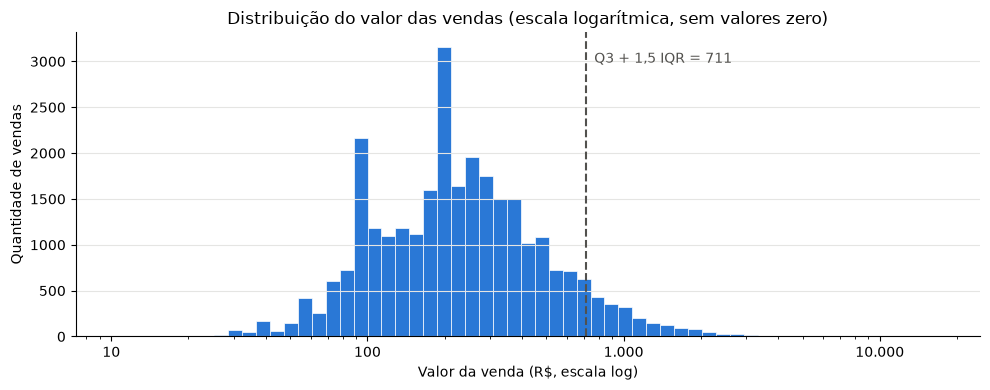

In [30]:
# Distribuição de ValorVenda em escala logarítmica (a escala linear esconderia a cauda)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(valor[valor > 0], bins=np.logspace(np.log10(valor[valor > 0].min()), np.log10(valor.max()), 60),
        color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.axvline(limite_sup, color="#52514e", linestyle="--", linewidth=1.5)
ax.text(limite_sup * 1.08, ax.get_ylim()[1] * 0.9, f"Q3 + 1,5 IQR = {limite_sup:,.0f}", color="#52514e")
ax.set_title("Distribuição do valor das vendas (escala logarítmica, sem valores zero)")
ax.set_xlabel("Valor da venda (R$, escala log)")
ax.set_ylabel("Quantidade de vendas")
ax.grid(axis="y", color="#e5e5e3")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Diagnóstico:**

- **Caso 1 — valor zero:** 16 vendas, 14 delas pagas com `Cupom de Desconto`. Um cupom que cobre 100% do pedido é **plausível** (brinde, troca, promoção). Já os 2 casos de `Boleto Bancário` com valor zero são **incoerentes**, porque não se emite boleto de R$ 0,00.
- **Caso 2 — centavos fracionados:** 77 vendas têm 3 ou 4 casas decimais (ex.: `431,275`). Isso **não é um erro de leitura**: o valor está assim no arquivo. A hipótese mais provável é um cálculo (desconto percentual ou juros) que não foi arredondado para centavos. A diferença para o valor arredondado é de no máximo meio centavo, então o impacto financeiro é desprezível, mas o valor não é monetariamente válido.
- **Caso 3 — extremos:** o critério do IQR marca 2.083 vendas (7,3%) acima de R$ 711,00. Uma proporção tão alta **não é compatível com erro**: é o formato natural de uma distribuição assimétrica de preços, como mostra o histograma, que é contínuo e sem ruptura. Os valores mais altos (R$ 17.016,25 e R$ 16.662,68) estão isolados, mas são coerentes com as demais colunas: forma de pagamento válida, parcelamento compatível. Um valor extremo **não é, por si só, um erro**.

## 3.8 Pagamento: consistência entre Id, forma, tipo e parcelas

As quatro colunas de pagamento descrevem a mesma realidade e devem concordar entre si. A verificação tem duas etapas: (i) cada `IdFormaDePagamento` corresponde a uma única forma e a um único tipo? (ii) o número de parcelas é compatível com a forma de pagamento?

In [31]:
# (i) Relação entre Id, forma e tipo: deve ser 1 para 1
combinacoes = df_raw.groupby(["IdFormaDePagamento", "FormaPagamento", "TipoFormaPagamento"]).size()
display(combinacoes.rename("vendas").to_frame())

print(f"Formas por Id : {df_raw.groupby('IdFormaDePagamento')['FormaPagamento'].nunique().max()}")
print(f"Ids por forma : {df_raw.groupby('FormaPagamento')['IdFormaDePagamento'].nunique().max()}")

,,,vendas
IdFormaDePagamento,FormaPagamento,TipoFormaPagamento,
1,Boleto Bancário,Boleto Bancário,7530
2,Visa,Cartão de Crédito,11805
3,MasterCard,Cartão de Crédito,8420
4,Diners,Cartão de Crédito,236
6,Cupom de Desconto,Cupom,511
7,Glamour VIP,Pagamentos Glamour,3


Formas por Id : 1
Ids por forma : 1


In [32]:
# (ii) Parcelas por forma de pagamento
display(pd.crosstab(df_raw["FormaPagamento"], df_raw["NumeroParcelas"]))

NumeroParcelas,0,1,2,3,4,5,6,7,8,9,10
FormaPagamento,,,,,,,,,,,
Boleto Bancário,0,7530,0,0,0,0,0,0,0,0,0
Cupom de Desconto,0,511,0,0,0,0,0,0,0,0,0
Diners,3,27,30,26,30,18,13,8,7,8,66
Glamour VIP,0,3,0,0,0,0,0,0,0,0,0
MasterCard,228,1302,1116,1069,1063,726,561,272,272,235,1576
Visa,354,1975,1641,1488,1493,983,831,362,380,261,2037


A relação Id × forma × tipo é **perfeitamente consistente**: cada Id tem uma única forma e cada forma um único Id. O Id `5` não existe na base, mas isso não é um problema, apenas um código não utilizado no período. Boleto, cupom e Glamour VIP estão sempre em 1 parcela, o que é coerente.

A anomalia está nos **cartões de crédito com 0 parcelas**. A pergunta é: o zero é um erro aleatório ou tem padrão?

In [33]:
cartao = df_raw["TipoFormaPagamento"].eq("Cartão de Crédito")
parcela_zero = cartao & df_raw["NumeroParcelas"].eq(0)

print(f"Vendas em cartão com 0 parcelas: {parcela_zero.sum()}")
print(f"Primeira ocorrência            : {aux_venda[parcela_zero].min()}")
print("\nOcorrências por mês:")
print(aux_venda[parcela_zero].dt.to_period("M").value_counts().sort_index().to_string())

# Comparação de valor com as demais vendas em cartão do mesmo período
periodo = cartao & (aux_venda >= aux_venda[parcela_zero].min())
comparacao = (df_raw[periodo].groupby(df_raw["NumeroParcelas"].eq(0).map({True: "0 parcelas", False: "1+ parcelas"}))
              ["ValorVenda"].agg(["count", "median", "mean"]))
display(comparacao)

Vendas em cartão com 0 parcelas: 585
Primeira ocorrência            : 2011-06-10 10:27:00

Ocorrências por mês:
DataVenda
2011-06    108
2011-07    316
2011-08    161
Freq: M


,count,median,mean
NumeroParcelas,,,
0 parcelas,585,69.00,92.66
1+ parcelas,7243,240.00,331.38


**Diagnóstico:** o zero **não é aleatório**. As 585 ocorrências começam em **10/06/2011** e não há nenhuma antes disso. Além disso, concentram-se em vendas de **valor baixo** (mediana de R$ 69,00, contra R$ 240,00 nas demais vendas em cartão do mesmo período). O padrão sugere uma **mudança no sistema** a partir de junho, por exemplo uma nova modalidade (débito, cartão pré-pago ou "à vista" registrado como 0) ou uma falha na captura das parcelas. Isso **não é um erro de digitação**, e a base não permite afirmar qual das hipóteses é a correta. É uma pergunta para a área de negócio.

## 3.9 Domínio: unidades federativas

`UF_Cliente` tem domínio fechado e conhecido: as 27 unidades federativas do Brasil. A verificação compara os valores da base com uma lista de referência, e essa regra é reutilizável em qualquer carga futura.

In [34]:
UFS_VALIDAS = {"AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO", "MA", "MT", "MS", "MG", "PA",
               "PB", "PR", "PE", "PI", "RJ", "RN", "RS", "RO", "RR", "SC", "SP", "SE", "TO"}

ufs_base = set(df_raw["UF_Cliente"].dropna().unique())
print(f"UFs distintas na base : {len(ufs_base)}")
print(f"UFs fora do domínio   : {sorted(ufs_base - UFS_VALIDAS) or 'nenhuma'}")
print(f"UFs sem nenhuma venda : {sorted(UFS_VALIDAS - ufs_base) or 'nenhuma'}")

UFs distintas na base : 27
UFs fora do domínio   : nenhuma
UFs sem nenhuma venda : nenhuma


`UF_Cliente` está **íntegra**: as 27 UFs aparecem, todas escritas no padrão oficial, sem variações de caixa ou espaços. Um bom lembrete de que o *profiling* também serve para **confirmar** que algo está correto.

## 3.10 Duplicidades e granularidade: o que é uma linha?

A granularidade esperada é **uma linha = uma venda**. A verificação tem dois níveis:

- **Duplicata exata:** todas as colunas iguais, incluindo data e hora ao minuto.
- **Possível repetição:** o mesmo cliente, com o mesmo valor, em um intervalo curto (até 60 minutos). Pode ser uma segunda compra legítima, mas também uma **nova tentativa de pagamento** (por exemplo, cartão recusado e depois boleto) registrada como uma nova venda.

In [35]:
duplicatas = df_raw.duplicated(keep="first")
print(f"Duplicatas exatas (linhas excedentes): {duplicatas.sum()}")
display(df_raw[df_raw.duplicated(keep=False)])

Duplicatas exatas (linhas excedentes): 1


,DataVenda,ValorVenda,IdFormaDePagamento,FormaPagamento,TipoFormaPagamento,NumeroParcelas,Cliente_Codigo,Cliente_Data_Nascimento,UF_Cliente,CanalVenda
6568,2011-05-08 15:23:00,195.00,1,Boleto Bancário,Boleto Bancário,1,375678,1986-01-22,PE,NaN
6569,2011-05-08 15:23:00,195.00,1,Boleto Bancário,Boleto Bancário,1,375678,1986-01-22,PE,NaN


In [36]:
JANELA_REPETICAO = pd.Timedelta(minutes=60)

# Ordena por cliente, valor e horário; mede o intervalo até a venda anterior de mesmo cliente e valor
ordem = pd.DataFrame({"cliente": df_raw["Cliente_Codigo"], "valor": df_raw["ValorVenda"],
                      "data": aux_venda, "forma": df_raw["FormaPagamento"]}).sort_values(["cliente", "valor", "data"])
grupo = ordem.groupby(["cliente", "valor"])
intervalo = grupo["data"].diff()
forma_anterior = grupo["forma"].shift()

repeticao = intervalo.notna() & (intervalo <= JANELA_REPETICAO) & (intervalo > pd.Timedelta(0))
print(f"Vendas repetidas (mesmo cliente e valor, até 60 min após a anterior): {repeticao.sum()}")
print(f"  - com a mesma forma de pagamento da anterior    : {(repeticao & (forma_anterior == ordem['forma'])).sum()}")
print(f"  - com forma de pagamento diferente da anterior  : {(repeticao & (forma_anterior != ordem['forma'])).sum()}")
print(f"Mediana do intervalo entre as duas vendas: {intervalo[repeticao].median()}")

Vendas repetidas (mesmo cliente e valor, até 60 min após a anterior): 891
  - com a mesma forma de pagamento da anterior    : 690
  - com forma de pagamento diferente da anterior  : 201
Mediana do intervalo entre as duas vendas: 0 days 00:10:00


**Diagnóstico:**

- **Caso 1 — duplicata exata:** 1 par de linhas idênticas (cliente `375678`, R$ 195,00, mesmo minuto, mesma forma de pagamento). Duas vendas legítimas iguais no mesmo minuto são improváveis: trata-se de um registro em duplicidade.
- **Caso 2 — possíveis repetições (o mais relevante para a granularidade):** 891 vendas repetem cliente e valor de outra venda feita até 60 minutos antes, com intervalo mediano de 10 minutos. Em 201 delas **a forma de pagamento mudou**, padrão típico de "cartão recusado, tentou boleto". Isso **não é duplicidade comprovada**: o cliente pode ter comprado o mesmo item duas vezes. Mas indica que **nem toda linha é necessariamente uma venda concluída**, e a base não tem uma coluna de status do pedido que permita confirmar.

## 3.11 Inconsistências entre colunas: o cliente e sua UF

Atributos do cliente deveriam ser estáveis entre as vendas de um mesmo `Cliente_Codigo`. Em 3.4 vimos que o nascimento é estável. A UF, porém, apresenta divergências.

In [37]:
ufs_por_cliente = df_raw.groupby("Cliente_Codigo")["UF_Cliente"].nunique()
clientes_multi_uf = ufs_por_cliente[ufs_por_cliente > 1].index
vendas_multi_uf = df_raw["Cliente_Codigo"].isin(clientes_multi_uf)

print(f"Clientes com mais de uma UF : {len(clientes_multi_uf)}")
print(f"Vendas desses clientes      : {vendas_multi_uf.sum()}")
display(df_raw[vendas_multi_uf].groupby("Cliente_Codigo")["UF_Cliente"].unique().head(8).to_frame())

Clientes com mais de uma UF : 53
Vendas desses clientes      : 223


,UF_Cliente
Cliente_Codigo,
2221,"[SP, RO]"
2368,"[MS, SP]"
3226,"[SP, MS]"
5629,"[GO, SP]"
8172,"[PR, SP]"
97193,"[PI, MA]"
129574,"[DF, RJ]"
134950,"[DF, TO]"


**Diagnóstico:** 53 clientes (223 vendas) aparecem com mais de uma UF, quase sempre duas. Isso **não é necessariamente um erro**: a UF pode refletir o **endereço de entrega** de cada pedido (presente para alguém em outro estado, mudança de endereço). Como a base não informa se `UF_Cliente` é do cadastro ou da entrega, a divergência é **mantida e sinalizada**.

## 3.12 Concentração por cliente: compradores atípicos

A distribuição de compras por cliente é muito concentrada no valor 1. Clientes com dezenas ou centenas de compras em oito meses podem ser revendedores, contas corporativas, contas de teste ou comportamento suspeito. Para defini-los de forma **genérica**, sem citar códigos, usamos o **percentil 99,9** do número de compras por cliente.

In [38]:
compras_por_cliente = df_raw["Cliente_Codigo"].value_counts()
print(compras_por_cliente.describe().round(2).to_string())

limite_atipico = compras_por_cliente.quantile(0.999)
clientes_atipicos = compras_por_cliente[compras_por_cliente > limite_atipico]
print(f"\nLimite (percentil 99,9): {limite_atipico:.1f} compras")
print(f"Clientes acima do limite: {len(clientes_atipicos)} ({clientes_atipicos.sum()} vendas)")

# Perfil dos 3 clientes mais frequentes
top3 = clientes_atipicos.head(3).index
perfil_top = df_raw[df_raw["Cliente_Codigo"].isin(top3)].groupby("Cliente_Codigo").agg(
    vendas=("ValorVenda", "size"),
    valor_total=("ValorVenda", "sum"),
    ufs=("UF_Cliente", "nunique"),
    canal_mais_comum=("CanalVenda", lambda s: s.value_counts(dropna=False).index[0]),
    pct_canal_mais_comum=("CanalVenda", lambda s: round(s.value_counts(dropna=False, normalize=True).iloc[0] * 100, 1)),
    forma_mais_comum=("FormaPagamento", lambda s: s.mode().iloc[0]),
    dias_com_compra=("DataVenda", lambda s: s.str[:10].nunique()),
).sort_values("vendas", ascending=False)
perfil_top

count   13,737.00
mean         2.08
std          3.37
min          1.00
25%          1.00
50%          1.00
75%          2.00
max        236.00

Limite (percentil 99,9): 30.3 compras
Clientes acima do limite: 14 (877 vendas)


,vendas,valor_total,ufs,canal_mais_comum,pct_canal_mais_comum,forma_mais_comum,dias_com_compra
Cliente_Codigo,,,,,,,
618107,236,"29,550.26",1,HiMidia,100.00,Boleto Bancário,30
597657,109,"16,443.32",1,NaN,71.60,MasterCard,60
3850,85,"9,387.90",1,xptoourMasc1,76.50,MasterCard,36


**Diagnóstico:** metade dos clientes compra uma única vez (mediana = 1), e o percentil 99,9 é de cerca de 30 compras. Acima dele estão 14 clientes, que somam 877 vendas. O caso mais extremo tem **236 vendas**, **100% pelo canal `HiMidia`**, quase todas em boleto, distribuídas em 30 dias diferentes. Um padrão tão uniforme **não é típico de um consumidor final** e se parece mais com uma conta de revenda, de integração ou de teste. Isso **não prova erro**, mas esse único cliente responde por uma fração relevante do canal `HiMidia` e pode distorcer o *ranking* de canais.

O cliente mais extremo chegou a fazer dezenas de compras **em um mesmo dia**. Isso levanta uma segunda pergunta, sobre **granularidade**: quantas compras um mesmo cliente costuma fazer em um único dia, e quantos clientes têm esse comportamento de "rajada"?

In [39]:
# Compras do mesmo cliente no mesmo dia (pares cliente-dia)
dia_venda = df_raw["DataVenda"].str[:10]
compras_cliente_dia = df_raw.groupby(["Cliente_Codigo", dia_venda]).size()
dist_cliente_dia = compras_cliente_dia.value_counts().sort_index()
display(pd.DataFrame({"pares_cliente_dia": dist_cliente_dia,
                      "%_acumulado": (dist_cliente_dia.cumsum() / dist_cliente_dia.sum() * 100).round(2)}).head(8).T)

LIMITE_RAJADA = 5
em_rajada = df_raw.groupby(["Cliente_Codigo", dia_venda])["Cliente_Codigo"].transform("size") >= LIMITE_RAJADA
print(f"Vendas em dias com {LIMITE_RAJADA}+ compras do mesmo cliente: {em_rajada.sum()} "
      f"| clientes: {df_raw.loc[em_rajada, 'Cliente_Codigo'].nunique()}")
print(f"Boleto nessas vendas: {(df_raw.loc[em_rajada, 'FormaPagamento'] == 'Boleto Bancário').mean() * 100:.1f}% "
      f"| na base: {(df_raw['FormaPagamento'] == 'Boleto Bancário').mean() * 100:.1f}%")

,1,2,3,4,5,6,7,8
pares_cliente_dia,"22,907.00","1,743.00",302.00,116.00,49.00,13.00,5.00,9.00
%_acumulado,91.02,97.94,99.14,99.60,99.80,99.85,99.87,99.90


Vendas em dias com 5+ compras do mesmo cliente: 742 | clientes: 64
Boleto nessas vendas: 37.1% | na base: 26.4%


**Diagnóstico:** 99,6% dos pares cliente-dia têm no máximo 4 compras. Comprar **5 ou mais vezes no mesmo dia** é raro, mas não é exclusivo do cliente mais extremo: há centenas de vendas de dezenas de clientes nessa situação, com uso de boleto bem acima da média da base. Pode ser revenda, reemissão de boletos não pagos, teste ou fraude, e a base não tem o status do pedido para decidir. A investigação completa desse comportamento está na descoberta livre (9.6).

## 3.13 Canal de venda: sinais de texto livre

`CanalVenda` será tratado em profundidade na seção 7.5. Aqui registramos apenas as **evidências** de que o campo exige normalização, medindo padrões recorrentes no texto.

In [40]:
canal = df_raw["CanalVenda"].dropna()

sinais_canal = pd.DataFrame([
    ("Valores distintos (texto original)", canal.nunique(), len(canal)),
    ("Valores distintos ignorando maiúsculas/minúsculas", canal.str.lower().nunique(), len(canal)),
    ("Contém parâmetro de URL (utm_ / '=')", canal[canal.str.contains("=|utm_", regex=True)].nunique(),
     canal.str.contains("=|utm_", regex=True).sum()),
    ("Contém lista separada por vírgula", canal[canal.str.contains(",")].nunique(), canal.str.contains(",").sum()),
    ("Termina com '/'", canal[canal.str.endswith("/")].nunique(), canal.str.endswith("/").sum()),
    ("Começa com o prefixo 'xpto' (campanhas próprias)", canal[canal.str.lower().str.startswith("xpto")].nunique(),
     canal.str.lower().str.startswith("xpto").sum()),
], columns=["padrao", "valores_distintos", "vendas"])
sinais_canal

,padrao,valores_distintos,vendas
0,Valores distintos (texto original),602,19023
1,Valores distintos ignorando maiúsculas/minúsculas,585,19023
2,Contém parâmetro de URL (utm_ / '='),12,222
3,Contém lista separada por vírgula,62,131
4,Termina com '/',1,101
5,Começa com o prefixo 'xpto' (campanhas próprias),513,9321


In [41]:
# Exemplos: variações de caixa, listas, parâmetros e grafias próximas
grupos_caixa = canal.groupby(canal.str.lower()).agg(lambda s: dict(s.value_counts()))
print("Mesmo canal, grafias com caixa diferente (exemplos):")
print(grupos_caixa[grupos_caixa.apply(len) > 1].head(6).to_string(), "\n")

print("Listas com vírgula (exemplos):", canal[canal.str.contains(",")].value_counts().head(4).index.tolist())
print("Parâmetros de URL (exemplos) :", canal[canal.str.contains("=")].value_counts().head(3).index.tolist())

# Grafias próximas: pares de canais externos que parecem ser o mesmo
for termo in ["twitt", "bradd|bradock", "calcaecinto|calaecinto|calçaecinto", "^fb$|facebook", "google"]:
    achados = canal[canal.str.lower().str.contains(termo, regex=True)].value_counts()
    print(f"  '{termo}': {achados.head(6).to_dict()}")

Mesmo canal, grafias com caixa diferente (exemplos):
CanalVenda
clubmapfre                          {'clubmapfre': 17, 'ClubMapfre': 6}
coluna                                      {'coluna': 45, 'Coluna': 8}
lg                                                  {'lg': 12, 'LG': 2}
twitter                                  {'twitter': 49, 'Twitter': 12}
xptockjf                               {'xptockjf': 48, 'xptockjF': 15}
xptockjf, xptockjf    {'xptockjf, xptockjf': 1, 'xptockjF, xptockjF'... 

Listas com vírgula (exemplos): ['xptoourNcl, xptoourFem1', 'xptoourNcl, xptoourFem3', 'xptoourNcl, xptoourNcl1', 'xptoourNcl, xptoourFem2']
Parâmetros de URL (exemplos) : ['xptoourmasccalcaecintockjutm_medium=Newsletter', 'xptockjutm_medium=Newsletter', 'xptoprlutm_medium=Newsletter']
  'twitt': {'twitter': 49, 'Twitter': 12, 'xptoourNcl, Twitter': 1, 'twitte': 1, 'ColunaFem2, twitter': 1}
  'bradd|bradock': {'braddock': 32, 'bradock': 1}
  'calcaecinto|calaecinto|calçaecinto': {'xptoourmasccalcae

**Diagnóstico:** o campo `CanalVenda` mistura **identificador de canal**, **identificador de campanha** e **parâmetros de rastreamento** em um único texto livre. As evidências:

- **Caso 1 — ausência (o mais relevante em volume):** 9.482 vendas (33,26%) sem canal, registradas de duas formas (vazio e `NULL`).
- **Caso 2 — maiúsculas/minúsculas:** 602 valores distintos caem para 585 ignorando a caixa (ex.: `twitter`/`Twitter`, `xptoourMasc1`/`xptoourmasc1`).
- **Caso 3 — parâmetros embutidos:** 222 vendas trazem `utm_medium=Newsletter` colado ao nome da campanha. É um parâmetro de rastreamento de URL, e **não faz parte do nome do canal**.
- **Caso 4 — listas:** 131 vendas têm dois valores separados por vírgula. Às vezes é o mesmo valor repetido (`xptoLS, xptoLS`), às vezes duas origens (`xptoourNcl, xptoourFem1`), indicando **atribuição múltipla**.
- **Caso 5 — grafias diferentes para o mesmo canal:** `twitte`/`twitter`, `bradock`/`braddock`, `Fb`/`Facebook`, e `calçaecinto`/`calcaecinto`/`calaecinto` (o mesmo texto com e sem cedilha, sinal de perda de acentuação em algum sistema de origem).
- **Caso 6 — campanhas próprias:** 9.321 vendas começam com `xpto`, o nome da própria empresa. São campanhas internas (newsletter, banners, vitrines), que respondem por 513 dos valores distintos.

# 4. Diagnóstico da qualidade

## 4.1 Tabela de Qualidade dos Dados

A tabela consolida os problemas encontrados na seção 3. Ela é **montada por código**: cada quantidade vem de uma variável calculada na investigação, e não de um número digitado, para que a tabela continue correta se a base mudar.

A severidade combina o **volume afetado** com o **impacto na análise**:

- **Alta:** distorce indicadores centrais do negócio.
- **Média:** afeta análises específicas.
- **Baixa:** impacto pontual ou apenas formal.

In [42]:
def brl(x):
    # Formata valor monetário no padrão brasileiro (1.234,56)
    return f"R$ {x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


canal_bruto = df_raw["CanalVenda"]
# Vendas cujo texto não está em forma canônica: maiúsculas, parâmetros, listas ou barra final
n_variacoes_canal = canal.str.contains(r"[A-Z=,/]", regex=True).sum()

tabela_qualidade = pd.DataFrame([
    ("CanalVenda", "Ausência de canal, com dois marcadores (vazio e 'NULL')",
     "3.4 / 3.13: maior 'categoria' da coluna", canal_bruto.isna().sum(),
     "Preservar o original; criar a categoria 'Não informado' no normalizado", "Alta"),
    ("CanalVenda", "Texto livre: caixa, parâmetros UTM, listas com vírgula e grafias diferentes",
     f"3.13: {canal.nunique()} valores distintos; {canal.str.lower().nunique()} ignorando a caixa; "
     "contagem = vendas com maiúsculas, '=', ',' ou '/'",
     n_variacoes_canal, "Normalizar por regras genéricas e agrupar em taxonomia (7.5)", "Alta"),
    ("Cliente_Data_Nascimento", "Data sentinela (ano <= 1900)",
     "3.5: 1900-01-01 compartilhada por 141 clientes distintos", sentinela_1900.sum(),
     "Substituir por ausente e criar flag", "Alta"),
    ("Cliente_Data_Nascimento", "Nascimento posterior à data da compra",
     "3.6: idade negativa; máximo em 2011-12-16", (aux_idade < 0).sum(),
     "Substituir por ausente e criar flag", "Média"),
    ("Cliente_Data_Nascimento", "Idade improvável na compra (< 16 ou > 100 anos, sem sentinela)",
     "3.6: idade exata < 16 anos (ex.: nascimentos em 2008-2010); nenhuma acima de 100",
     (((aux_idade >= 0) & (aux_idade < 16)) | ((aux_idade > 100) & ~sentinela_1900)).sum(),
     "Manter e criar flag de idade improvável", "Média"),
    ("Cliente_Data_Nascimento", "Ausente (literal 'NULL')",
     "1.4 / 3.4: ausência consistente por cliente", df_raw["Cliente_Data_Nascimento"].isna().sum(),
     "Manter como ausente; faixa etária 'Não informado'", "Média"),
    ("NumeroParcelas", "Cartão de crédito com 0 parcelas",
     "3.8: surge em 10/06/2011; mediana R$ 69 vs R$ 240", parcela_zero.sum(),
     "Manter o valor original e criar flag para análise", "Média"),
    ("ValorVenda", "Valor zero", "3.7: 14 com cupom (plausível) e 2 com boleto (incoerente)",
     (valor == 0).sum(), "Manter e criar flag", "Baixa"),
    ("ValorVenda", "Mais de 2 casas decimais", "3.7: ex. 431,275; diferença máxima de meio centavo",
     mais_de_2_casas.sum(), "Arredondar para 2 casas (centavos)", "Baixa"),
    ("ValorVenda", "Valores extremos (acima de Q3 + 1,5 IQR)", f"3.7: limite de {brl(limite_sup)}; máximo de {brl(valor.max())}",
     (valor > limite_sup).sum(), "Manter (distribuição assimétrica legítima) e criar flag", "Baixa"),
    ("Linha inteira", "Duplicata exata", "3.10: cliente 375678, mesmo minuto e valor",
     duplicatas.sum(), "Remover a cópia excedente", "Baixa"),
    ("Cliente_Codigo / ValorVenda / DataVenda", "Possível repetição (mesmo cliente e valor em até 60 min)",
     "3.10: intervalo mediano de 10 min; 201 com troca de forma de pagamento", repeticao.sum(),
     "Manter e criar flag (sem status do pedido para confirmar)", "Média"),
    ("UF_Cliente", "Cliente com mais de uma UF", f"3.11: {len(clientes_multi_uf)} clientes",
     vendas_multi_uf.sum(), "Manter a UF de cada venda e criar flag", "Baixa"),
    ("Cliente_Codigo", "Cliente com volume atípico de compras (> percentil 99,9)",
     "3.12: máximo de 236 vendas, 100% em um único canal", clientes_atipicos.sum(),
     "Manter e criar flag para análise", "Média"),
    ("Cliente_Codigo / DataVenda", "Rajada de compras (5+ compras do mesmo cliente no mesmo dia)",
     "3.12: 99,6% dos pares cliente-dia têm até 4 compras; boleto acima da média", em_rajada.sum(),
     "Manter e criar flag para análise", "Média"),
    ("DataVenda, Cliente_Data_Nascimento, códigos", "Tipos inadequados na leitura automática",
     "2.5: datas como texto; códigos como inteiros", len(df_raw),
     "Converter os tipos no df_clean", "Média"),
], columns=["Campo", "Problema encontrado", "Evidência", "Quantidade afetada", "Regra proposta", "Severidade"])

tabela_qualidade["% da base"] = (tabela_qualidade["Quantidade afetada"] / len(df_raw) * 100).round(2)
ordem_sev = {"Alta": 0, "Média": 1, "Baixa": 2}
tabela_qualidade = (tabela_qualidade.sort_values("Severidade", key=lambda s: s.map(ordem_sev), kind="stable")
                    .reset_index(drop=True))
tabela_qualidade.index = tabela_qualidade.index + 1

with pd.option_context("display.max_colwidth", None):
    display(tabela_qualidade)

,Campo,Problema encontrado,Evidência,Quantidade afetada,Regra proposta,Severidade,% da base
1,CanalVenda,"Ausência de canal, com dois marcadores (vazio e 'NULL')",3.4 / 3.13: maior 'categoria' da coluna,9482,Preservar o original; criar a categoria 'Não informado' no normalizado,Alta,33.26
2,CanalVenda,"Texto livre: caixa, parâmetros UTM, listas com vírgula e grafias diferentes","3.13: 602 valores distintos; 585 ignorando a caixa; contagem = vendas com maiúsculas, '=', ',' ou '/'",10805,Normalizar por regras genéricas e agrupar em taxonomia (7.5),Alta,37.91
3,Cliente_Data_Nascimento,Data sentinela (ano <= 1900),3.5: 1900-01-01 compartilhada por 141 clientes distintos,270,Substituir por ausente e criar flag,Alta,0.95
4,Cliente_Data_Nascimento,Nascimento posterior à data da compra,3.6: idade negativa; máximo em 2011-12-16,12,Substituir por ausente e criar flag,Média,0.04
5,Cliente_Data_Nascimento,"Idade improvável na compra (< 16 ou > 100 anos, sem sentinela)",3.6: idade exata < 16 anos (ex.: nascimentos em 2008-2010); nenhuma acima de 100,172,Manter e criar flag de idade improvável,Média,0.60
6,Cliente_Data_Nascimento,Ausente (literal 'NULL'),1.4 / 3.4: ausência consistente por cliente,2633,Manter como ausente; faixa etária 'Não informado',Média,9.24
7,NumeroParcelas,Cartão de crédito com 0 parcelas,3.8: surge em 10/06/2011; mediana R$ 69 vs R$ 240,585,Manter o valor original e criar flag para análise,Média,2.05
8,Cliente_Codigo / ValorVenda / DataVenda,Possível repetição (mesmo cliente e valor em até 60 min),3.10: intervalo mediano de 10 min; 201 com troca de forma de pagamento,891,Manter e criar flag (sem status do pedido para confirmar),Média,3.13
9,Cliente_Codigo,"Cliente com volume atípico de compras (> percentil 99,9)","3.12: máximo de 236 vendas, 100% em um único canal",877,Manter e criar flag para análise,Média,3.08
10,Cliente_Codigo / DataVenda,Rajada de compras (5+ compras do mesmo cliente no mesmo dia),"3.12: 99,6% dos pares cliente-dia têm até 4 compras; boleto acima da média",742,Manter e criar flag para análise,Média,2.60


## 4.2 Interpretação: o que mais pesa

- **O canal de venda é o problema mais grave.** Um terço das vendas não tem canal, e o restante está pulverizado em centenas de grafias. Sem tratamento, **qualquer análise de marketing fica comprometida**: o ranking de canais seria liderado pela ausência de informação, e canais relevantes apareceriam fragmentados em várias linhas.
- **O sentinela de nascimento é pequeno em volume (270 vendas), mas tem alto impacto.** Cada venda com `1900-01-01` soma uma "idade" de cerca de 110 anos. Poucas centenas desses valores bastam para deslocar a idade média e criar uma faixa etária de idosos que não existe.
- **As anomalias de pagamento e de granularidade são perguntas, não erros.** O zero em parcelas e as possíveis repetições têm padrão claro, mas a base não permite concluir a causa. Por isso a regra proposta é **sinalizar, não corrigir**.
- **Os extremos de valor não são problema.** Eles descrevem uma distribuição assimétrica real. Removê-los reduziria artificialmente o ticket médio.
- **Há boas notícias:** `UF_Cliente` está íntegra no domínio, a relação Id × forma × tipo de pagamento é perfeita e `DataVenda` não tem nenhum valor inválido.

# 5. Decisões sobre os problemas

## 5.1 Contexto: as cinco decisões possíveis

Cada problema recebe uma de cinco decisões:

- **A. Corrigir:** o valor está errado e existe uma regra objetiva para substituí-lo, mesmo que por "ausente".
- **B. Remover:** a linha não representa um fato real.
- **C. Manter:** o valor é estranho, mas legítimo.
- **D. Transformar:** o dado está correto, mas em formato inadequado para análise.
- **E. Marcar para análise:** há indício de problema, mas não prova. O valor é preservado e uma *flag* de qualidade o identifica.

O princípio geral é **"excluir dados não é limpar dados"**: a remoção é reservada para quando há certeza de que a linha não é uma venda real. Nos demais casos, a preferência é por *flags*, que deixam a decisão de filtrar para quem faz a análise, com transparência.

## 5.2 Duplicata exata: decisão B (Remover)

- **Problema:** duas linhas idênticas em todas as colunas.
- **Evidência:** 1 cópia excedente (3.10). Mesmo cliente, mesmo valor (R$ 195,00), mesmo minuto e mesma forma de pagamento.
- **Decisão:** **B. Remover** a cópia, mantendo a primeira ocorrência.
- **Por quê:** é a única situação da base em que não há dúvida razoável. Duas vendas idênticas no mesmo minuto, sem nenhuma diferença em nenhum atributo, correspondem a um registro gravado duas vezes. Mantê-la contaria a mesma venda em dobro.
- **Efeito:** −1 linha. A remoção fica registrada no *log* da seção 6.

## 5.3 Nascimento sentinela e nascimento posterior à compra: decisão A (Corrigir)

- **Problema:** datas de nascimento que não representam o nascimento real: ano ≤ 1900 (sentinela) ou data posterior à compra (impossível).
- **Evidência:** 270 vendas com sentinela (3.5) e 12 com idade negativa (3.6).
- **Decisão:** **A. Corrigir**, substituindo por ausente (`NaT`) no `df_clean`, com uma *flag* que registra o motivo (`sentinela` ou `posterior_compra`).
- **Por quê:** o valor informado é comprovadamente falso, e não existe fonte para descobrir o verdadeiro. Transformá-lo em ausente é a correção honesta: a informação passa a dizer "não sabemos", em vez de afirmar algo errado. A **venda não é removida**, porque valor, pagamento e canal continuam válidos.
- **Efeito:** o número de nascimentos ausentes no CLEAN aumenta. A idade média deixa de ser inflada pelas "idades" de 110 anos. O valor original continua disponível no `df_raw`.

## 5.4 Idades improváveis: decisão E (Marcar para análise)

- **Problema:** idades possíveis, mas improváveis, na data da compra: menos de 16 ou mais de 100 anos.
- **Evidência:** 172 vendas (3.6), todas de compradores com 0 a 15 anos na data da compra. Nenhuma venda passa de 100 anos, mas o limite superior fica na regra para cargas futuras.
- **Decisão:** **E. Marcar** com a *flag* `flag_idade_improvavel`, mantendo a data.
- **Por quê:** diferentemente do sentinela, **não há prova de erro**. Um cliente de 101 anos existe, e uma compra no cadastro de um adolescente também. Apagar esses valores seria substituir um dado possivelmente real por uma suposição.
- **Efeito:** nenhum valor é alterado. As análises de perfil etário (9.3) podem excluir os casos marcados, informando essa escolha.

## 5.5 Centavos fracionados em `ValorVenda`: decisão A (Corrigir)

- **Problema:** valores com 3 ou 4 casas decimais.
- **Evidência:** 77 vendas (3.7). A diferença máxima para o valor arredondado é de meio centavo.
- **Decisão:** **A. Corrigir**, arredondando para 2 casas decimais.
- **Por quê:** o real não tem frações de centavo. O arredondamento restaura a validade monetária sem mudar o sentido do dado, e o impacto somado é desprezível.
- **Efeito:** 77 valores alterados em menos de R$ 0,01 cada, registrados no *log*.

## 5.6 Valores zero e valores extremos: decisões E e C

- **Problema:** vendas de R$ 0,00 e vendas muito acima do padrão.
- **Evidência:** 16 vendas com valor zero, sendo 14 em cupom e 2 em boleto (3.7). Pela regra do IQR, 2.083 vendas acima de R$ 711,00, com máximo de R$ 17.016,25.
- **Decisão:**
  - **Valor zero, E. Marcar** (`flag_valor_zero`).
  - **Extremos, C. Manter** (com `flag_valor_extremo` apenas como informação).
- **Por quê:** o valor zero pago com cupom é plausível e o pago com boleto é suspeito, mas nos dois casos a venda existe. Os extremos somam 7,3% da base e formam a cauda contínua de uma distribuição assimétrica. **Não se remove um valor só por estar longe da média**, e retirá-los subestimaria o faturamento e o ticket médio.
- **Efeito:** nenhum valor alterado. As duas *flags* permitem análises com e sem esses casos.

## 5.7 Cartão com 0 parcelas: decisão E (Marcar para análise)

- **Problema:** vendas em cartão de crédito registradas com 0 parcelas.
- **Evidência:** 585 vendas, todas a partir de 10/06/2011, com valor mediano bem menor (3.8).
- **Decisão:** **E. Marcar** com `flag_parcelas_zero`, mantendo o `0` original.
- **Por quê:** o padrão temporal indica uma mudança de sistema ou de modalidade, e não um erro aleatório. "Corrigir" para 1 parcela suporia que o zero significa "à vista", uma hipótese que a base não confirma. A causa deve ser validada com a área de negócio.
- **Efeito:** nenhum valor alterado. As análises de parcelamento devem tratar esses casos à parte.

## 5.8 Possíveis repetições, rajadas, clientes atípicos e clientes com várias UFs: decisões E e C

- **Problema:** linhas que podem não ser vendas independentes (repetições em até 60 minutos e rajadas de 5+ compras no mesmo dia), clientes com volume de compras fora do padrão e clientes com mais de uma UF.
- **Evidência:** 891 possíveis repetições (3.10), rajadas de compras (3.12), 14 clientes atípicos com 877 vendas (3.12) e 53 clientes com várias UFs (3.11).
- **Decisão:**
  - **Repetições, E. Marcar** (`flag_possivel_repeticao`).
  - **Rajadas, E. Marcar** (`flag_rajada_compras`).
  - **Clientes atípicos, E. Marcar** (`flag_cliente_atipico`).
  - **UF múltipla, C. Manter** (`flag_cliente_multi_uf`).
- **Por quê:** em todos os casos há uma explicação legítima possível (segunda compra, revendedor, endereço de entrega diferente), e falta à base a informação que decidiria a questão, como o status do pedido ou o tipo de cliente. Remover as repetições, por exemplo, poderia apagar vendas reais.
- **Efeito:** nenhuma linha removida. As *flags* permitem medir a **sensibilidade** dos indicadores, por exemplo o ranking de canais com e sem o cliente atípico.

## 5.9 Canal de venda: decisão D (Transformar)

- **Problema:** texto livre com ausências, variações de caixa, parâmetros UTM, listas e grafias diferentes.
- **Evidência:** 9.482 ausentes e 602 valores distintos (3.13).
- **Decisão:** **D. Transformar**, criando três colunas:
  - `CanalVenda_Original`: o texto bruto, preservado.
  - `CanalVenda_Normalizado`: minúsculas, sem parâmetros, sem duplicação, com as grafias unificadas.
  - `GrupoCanal`: uma taxonomia de negócio.

  As ausências viram a categoria explícita `Não informado`.
- **Por quê:** o conteúdo não está errado, apenas em formato impróprio para agregação. A normalização usa **regras genéricas** (funções, *regex* e dicionário de mapeamento), para funcionar com canais novos em cargas futuras.
- **Efeito:** nenhuma linha removida. A cardinalidade cai de centenas de valores para poucos grupos analisáveis (detalhes na seção 7.5).

## 5.10 Tipos de dados: decisão D (Transformar)

- **Problema:** datas lidas como texto e códigos lidos como números.
- **Evidência:** seção 2.5.
- **Decisão:** **D. Transformar**:
  - `DataVenda` e `Cliente_Data_Nascimento` para `datetime64`.
  - `Cliente_Codigo` para texto.
  - `IdFormaDePagamento`, `FormaPagamento`, `TipoFormaPagamento` e `UF_Cliente` para `category`.
- **Por quê:** permite cálculos temporais, impede operações sem sentido sobre códigos e reduz a memória.
- **Efeito:** nenhum valor alterado, apenas a representação.

## 5.11 Resumo das decisões

| Problema | Decisão | Justificativa | Tratamento aplicado |
|---|---|---|---|
| Duplicata exata | **B. Remover** | Registro idêntico no mesmo minuto; sem dúvida razoável | Remover a cópia excedente (`keep="first"`) e registrar no *log* |
| Nascimento sentinela (ano ≤ 1900) | **A. Corrigir** | Valor comprovadamente artificial | Substituir por `NaT` + `flag_nascimento_invalido = "sentinela"` |
| Nascimento posterior à compra | **A. Corrigir** | Valor impossível | Substituir por `NaT` + `flag_nascimento_invalido = "posterior_compra"` |
| Idade improvável (< 16 ou > 100) | **E. Marcar** | Possível, sem prova de erro | `flag_idade_improvavel` |
| Centavos fracionados | **A. Corrigir** | Frações de centavo não existem | Arredondar `ValorVenda` para 2 casas |
| Valor zero | **E. Marcar** | Cupom integral plausível; boleto zerado suspeito | `flag_valor_zero` |
| Valores extremos | **C. Manter** | Cauda natural de distribuição assimétrica | `flag_valor_extremo` (informativa) |
| Cartão com 0 parcelas | **E. Marcar** | Padrão temporal; causa desconhecida | `flag_parcelas_zero` |
| Possível repetição (≤ 60 min) | **E. Marcar** | Pode ser recompra ou nova tentativa de pagamento | `flag_possivel_repeticao` |
| Rajada de compras (5+ no mesmo dia) | **E. Marcar** | Pode ser revenda, reemissão de boleto, teste ou fraude | `flag_rajada_compras` |
| Cliente com volume atípico | **E. Marcar** | Pode ser revendedor ou conta de teste | `flag_cliente_atipico` |
| Cliente com várias UFs | **C. Manter** | UF pode ser a de entrega | `flag_cliente_multi_uf` |
| Canal ausente ou em texto livre | **D. Transformar** | Conteúdo válido em formato impróprio | `CanalVenda_Original`, `CanalVenda_Normalizado`, `GrupoCanal` |
| Tipos inadequados | **D. Transformar** | Datas como texto; códigos como números | Conversão de tipos no `df_clean` |

**Síntese:** das 14 decisões, apenas **uma remove linhas** (uma única cópia duplicada). Todas as outras preservam as vendas, e quatro delas alteram algum valor: nascimentos inválidos, arredondamento, canal e tipos.

## 5.12 Parâmetros das regras

As regras de decisão dependem de alguns limites. Eles ficam centralizados em um único lugar, em vez de espalhados pelo código, para que a seção 6 os aplique de forma consistente e para que possam ser revistos sem editar a lógica. Nenhum deles é específico desta base (não há índices de linha nem códigos de cliente).

In [43]:
PARAMETROS_REGRAS = {
    "ano_max_sentinela_nascimento": 1900,   # nascimento com ano <= 1900 é sentinela
    "idade_min_provavel": 16,               # abaixo disso: idade improvável
    "idade_max_provavel": 100,              # acima disso: idade improvável
    "casas_decimais_valor": 2,              # centavos
    "fator_iqr_extremo": 1.5,               # regra clássica do IQR
    "janela_repeticao_min": 60,             # minutos entre vendas de mesmo cliente e valor
    "percentil_cliente_atipico": 0.999,     # volume de compras por cliente
    "compras_mesmo_dia_rajada": LIMITE_RAJADA,  # compras do mesmo cliente no mesmo dia (3.12)
}
pd.Series({k: str(v) for k, v in PARAMETROS_REGRAS.items()}, name="valor").to_frame()

,valor
ano_max_sentinela_nascimento,1900
idade_min_provavel,16
idade_max_provavel,100
casas_decimais_valor,2
fator_iqr_extremo,1.5
janela_repeticao_min,60
percentil_cliente_atipico,0.999
compras_mesmo_dia_rajada,5


# 6. Limpeza e transformação

## 6.1 Contexto: cópia de trabalho e rastreabilidade

A limpeza acontece sobre o `df_clean`, uma **cópia independente** do `df_raw` (`copy(deep=True)`). Alterar a cópia não afeta o original, e o *hash* calculado em 1.5 é conferido no fim da seção 7 para provar isso.

Cada registro recebe um identificador, `id_registro`, igual à sua posição no RAW. É ele que permite rastrear qualquer linha da base limpa até a linha de origem, mesmo depois de remoções.

Dois *logs* documentam o processo:

- **`log_etapas`:** uma linha por etapa, com a quantidade de linhas antes e depois e a quantidade de registros afetados.
- **`log_registros`:** uma linha por **valor alterado ou registro removido**, com `id_registro`, coluna, valor anterior, valor novo e motivo.

As *flags* de qualidade não alteram valores, apenas acrescentam informação. Por isso ficam registradas no `log_etapas`, e não no `log_registros`.

In [44]:
df_clean = df_raw.copy(deep=True)
df_clean.insert(0, "id_registro", df_raw.index)

log_etapas = []
log_registros = []


def registrar_etapa(etapa, decisao, linhas_antes, linhas_depois, afetados, descricao):
    # Registra o resumo de uma etapa do pipeline
    log_etapas.append({"etapa": etapa, "decisao": decisao, "linhas_antes": linhas_antes,
                       "linhas_depois": linhas_depois, "registros_afetados": int(afetados),
                       "descricao": descricao})


def registrar_registros(df, mascara, etapa, acao, coluna, depois, motivo):
    # Registra, linha a linha, os valores alterados (ou os registros removidos)
    afetados = df.loc[mascara]
    antes = afetados[coluna].astype(str) if coluna else "-"
    novos = depois[mascara].astype(str) if isinstance(depois, pd.Series) else depois
    log_registros.append(pd.DataFrame({
        "id_registro": afetados["id_registro"].values, "etapa": etapa, "acao": acao,
        "coluna": coluna or "(linha inteira)", "valor_antes": np.asarray(antes),
        "valor_depois": np.asarray(novos), "motivo": motivo,
    }))


print(f"df_clean criado: {df_clean.shape[0]:,} linhas x {df_clean.shape[1]} colunas "
      f"(10 originais + id_registro)")
print(f"df_clean é um objeto diferente do df_raw: {df_clean is not df_raw}")

df_clean criado: 28,505 linhas x 11 colunas (10 originais + id_registro)
df_clean é um objeto diferente do df_raw: True


## 6.2 Duplicata exata: remoção (decisão B)

A regra é aplicada sobre as **colunas originais**. O `id_registro` fica de fora da comparação, porque é diferente por definição. A primeira ocorrência é mantida e a cópia é removida.

In [45]:
colunas_originais = list(df_raw.columns)
linhas_antes = len(df_clean)

mascara_dup = df_clean.duplicated(subset=colunas_originais, keep="first")
registrar_registros(df_clean, mascara_dup, "6.2", "removido", None, "-",
                    "Duplicata exata de outro registro (todas as colunas originais iguais)")
df_clean = df_clean.loc[~mascara_dup]

registrar_etapa("6.2", "B. Remover", linhas_antes, len(df_clean), mascara_dup.sum(),
                "Remoção de duplicatas exatas (mantida a primeira ocorrência)")
print(f"Linhas antes: {linhas_antes:,} | removidas: {mascara_dup.sum()} | linhas depois: {len(df_clean):,}")

Linhas antes: 28,505 | removidas: 1 | linhas depois: 28,504


## 6.3 Tipos de dados: conversão (decisão D)

As conversões seguem o diagnóstico de 2.5. Os formatos de data são os mesmos confirmados em 1.3 (`FORMATOS_DATA`). O parâmetro `errors="coerce"` garante que um valor fora do formato vire `NaT` em vez de interromper o *pipeline*. A contagem de `NaT` antes e depois mostra que **nenhuma data válida foi perdida**.

In [46]:
ausentes_antes = df_clean[["DataVenda", "Cliente_Data_Nascimento"]].isna().sum()

df_clean["DataVenda"] = pd.to_datetime(df_clean["DataVenda"], format=FORMATOS_DATA["DataVenda"], errors="coerce")
df_clean["Cliente_Data_Nascimento"] = pd.to_datetime(df_clean["Cliente_Data_Nascimento"],
                                                     format=FORMATOS_DATA["Cliente_Data_Nascimento"],
                                                     errors="coerce")
df_clean["Cliente_Codigo"] = df_clean["Cliente_Codigo"].astype(str)
for coluna in ["IdFormaDePagamento", "FormaPagamento", "TipoFormaPagamento", "UF_Cliente"]:
    df_clean[coluna] = df_clean[coluna].astype("category")

ausentes_depois = df_clean[["DataVenda", "Cliente_Data_Nascimento"]].isna().sum()
assert ausentes_antes.equals(ausentes_depois), "A conversão de datas gerou ausentes novos"

registrar_etapa("6.3", "D. Transformar", len(df_clean), len(df_clean), len(df_clean),
                "Conversão de tipos: datas para datetime64, Cliente_Codigo para texto, 4 colunas para category")

comparacao_tipos = pd.DataFrame({"tipo_RAW": df_raw.dtypes.astype(str),
                                 "tipo_CLEAN": df_clean[colunas_originais].dtypes.astype(str)})
comparacao_tipos["ausentes_RAW"] = df_raw.isna().sum()
comparacao_tipos["ausentes_CLEAN"] = df_clean[colunas_originais].isna().sum()
comparacao_tipos

,tipo_RAW,tipo_CLEAN,ausentes_RAW,ausentes_CLEAN
DataVenda,str,datetime64[us],0,0
ValorVenda,float64,float64,0,0
IdFormaDePagamento,int64,category,0,0
FormaPagamento,str,category,0,0
TipoFormaPagamento,str,category,0,0
NumeroParcelas,int64,int64,0,0
Cliente_Codigo,int64,str,0,0
Cliente_Data_Nascimento,str,datetime64[us],2633,2633
UF_Cliente,str,category,0,0
CanalVenda,str,str,9482,9481


## 6.4 Nascimentos inválidos: correção para ausente (decisão A)

Duas regras identificam datas de nascimento **comprovadamente falsas**:

- **Sentinela:** ano ≤ `PARAMETROS_REGRAS["ano_max_sentinela_nascimento"]` (1900).
- **Posterior à compra:** nascimento depois da `DataVenda` da mesma linha.

O valor é substituído por `NaT`, e a *flag* `flag_nascimento_invalido` guarda o **motivo**. Assim a análise sabe *por que* a data está ausente: "não informado na origem" é diferente de "informado, mas inválido".

In [47]:
nasc = df_clean["Cliente_Data_Nascimento"]
eh_sentinela = nasc.dt.year <= PARAMETROS_REGRAS["ano_max_sentinela_nascimento"]
eh_posterior = nasc > df_clean["DataVenda"]

df_clean["flag_nascimento_invalido"] = np.select([eh_sentinela, eh_posterior],
                                                 ["sentinela", "posterior_compra"], default="")
df_clean["flag_nascimento_invalido"] = df_clean["flag_nascimento_invalido"].replace("", np.nan)

invalido = eh_sentinela | eh_posterior
registrar_registros(df_clean, eh_sentinela, "6.4", "modificado", "Cliente_Data_Nascimento", "NaT",
                    "Data sentinela (ano <= 1900) substituída por ausente")
registrar_registros(df_clean, eh_posterior, "6.4", "modificado", "Cliente_Data_Nascimento", "NaT",
                    "Nascimento posterior à data da compra substituído por ausente")

ausentes_antes = nasc.isna().sum()
df_clean.loc[invalido, "Cliente_Data_Nascimento"] = pd.NaT
ausentes_depois = df_clean["Cliente_Data_Nascimento"].isna().sum()

registrar_etapa("6.4", "A. Corrigir", len(df_clean), len(df_clean), invalido.sum(),
                "Nascimentos sentinela ou posteriores à compra substituídos por NaT + flag_nascimento_invalido")

print(f"Sentinelas corrigidos           : {eh_sentinela.sum()}")
print(f"Posteriores à compra corrigidos : {eh_posterior.sum()}")
print(f"Nascimentos ausentes: antes {ausentes_antes:,} -> depois {ausentes_depois:,}")
print(f"Nascimento mínimo após a correção: {df_clean['Cliente_Data_Nascimento'].min().date()}")
print(f"Nascimento máximo após a correção: {df_clean['Cliente_Data_Nascimento'].max().date()}")

Sentinelas corrigidos           : 270
Posteriores à compra corrigidos : 12
Nascimentos ausentes: antes 2,633 -> depois 2,915
Nascimento mínimo após a correção: 1910-10-10
Nascimento máximo após a correção: 2011-05-27


## 6.5 Centavos fracionados: arredondamento (decisão A)

O arredondamento usa a regra **comercial** (meio centavo arredonda para cima), aplicada com `decimal.Decimal`. Por que não `round()` ou `np.round()`? Porque um número como `431,275` não tem representação exata em ponto flutuante: internamente é `431,27499999...`, e o arredondamento binário daria `431,27`. A conversão via texto (`Decimal(str(x))`) preserva o valor como está escrito no arquivo.

In [48]:
from decimal import Decimal, ROUND_HALF_UP

CASAS = PARAMETROS_REGRAS["casas_decimais_valor"]
QUANTUM = Decimal(1).scaleb(-CASAS)  # 0.01 para 2 casas


def arredondar_comercial(x):
    # Arredonda meio centavo para cima, a partir da representação textual do número
    return float(Decimal(str(x)).quantize(QUANTUM, rounding=ROUND_HALF_UP))


valor_antes = df_clean["ValorVenda"].copy()
valor_depois = valor_antes.map(arredondar_comercial)
alterado = valor_antes.ne(valor_depois)

registrar_registros(df_clean, alterado, "6.5", "modificado", "ValorVenda", valor_depois,
                    "Valor com mais de 2 casas decimais arredondado para centavos")
df_clean["ValorVenda"] = valor_depois
registrar_etapa("6.5", "A. Corrigir", len(df_clean), len(df_clean), alterado.sum(),
                "ValorVenda arredondado para 2 casas (arredondamento comercial)")

print(f"Valores alterados : {alterado.sum()}")
print(f"Soma antes        : {valor_antes.sum():,.4f}")
print(f"Soma depois       : {valor_depois.sum():,.4f}")
print(f"Diferença total   : {valor_depois.sum() - valor_antes.sum():,.4f}")
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(pd.DataFrame({"antes": valor_antes[alterado], "depois": valor_depois[alterado]}).head(6))

Valores alterados : 77


Soma antes        : 8,967,894.9091
Soma depois       : 8,967,895.1400
Diferença total   : 0.2309


,antes,depois
13,431.2750,431.2800
47,72.2930,72.2900
259,684.5795,684.5800
260,703.7370,703.7400
280,268.1680,268.1700
623,857.7680,857.7700


## 6.6 Granularidade e clientes: *flags* de análise (decisões E e C)

Quatro *flags* registram situações que **não são erros comprovados**, mas que podem afetar indicadores:

- **`flag_possivel_repeticao`:** a venda repete cliente e valor de outra feita até `janela_repeticao_min` (60) minutos antes. A primeira venda do par **não** recebe a *flag*, apenas as repetições, para que filtrar a *flag* mantenha uma venda de cada par.
- **`flag_cliente_atipico`:** o cliente tem mais compras que o percentil 99,9 da base.
- **`flag_cliente_multi_uf`:** o cliente aparece com mais de uma UF.
- **`flag_rajada_compras`:** o cliente fez `compras_mesmo_dia_rajada` (5) ou mais compras no mesmo dia (3.12). A motivação detalhada desta regra, e o seu efeito sobre o canal HiMidia, estão na descoberta livre (9.6).

As regras são funções genéricas, sem códigos de cliente ou índices fixos.

In [49]:
def marcar_repeticoes(df, janela_min):
    # True para vendas que repetem cliente e valor de uma venda anterior dentro da janela
    ordenado = df.sort_values(["Cliente_Codigo", "ValorVenda", "DataVenda"])
    intervalo = ordenado.groupby(["Cliente_Codigo", "ValorVenda"])["DataVenda"].diff()
    repete = intervalo.notna() & (intervalo > pd.Timedelta(0)) & (intervalo <= pd.Timedelta(minutes=janela_min))
    return repete.reindex(df.index)


def marcar_clientes_atipicos(df, percentil):
    # True para vendas de clientes cujo número de compras supera o percentil informado
    compras = df["Cliente_Codigo"].map(df["Cliente_Codigo"].value_counts())
    limite = df["Cliente_Codigo"].value_counts().quantile(percentil)
    return compras > limite


def marcar_clientes_multi_uf(df):
    # True para vendas de clientes que aparecem com mais de uma UF
    return df.groupby("Cliente_Codigo")["UF_Cliente"].transform("nunique") > 1


def marcar_rajadas(df, minimo_compras):
    # True para vendas de clientes com pelo menos minimo_compras compras no mesmo dia
    compras_dia = df.groupby(["Cliente_Codigo", df["DataVenda"].dt.normalize()])["id_registro"].transform("size")
    return compras_dia >= minimo_compras


df_clean["flag_possivel_repeticao"] = marcar_repeticoes(df_clean, PARAMETROS_REGRAS["janela_repeticao_min"])
df_clean["flag_cliente_atipico"] = marcar_clientes_atipicos(df_clean, PARAMETROS_REGRAS["percentil_cliente_atipico"])
df_clean["flag_cliente_multi_uf"] = marcar_clientes_multi_uf(df_clean)
df_clean["flag_rajada_compras"] = marcar_rajadas(df_clean, PARAMETROS_REGRAS["compras_mesmo_dia_rajada"])

for flag, decisao in [("flag_possivel_repeticao", "E. Marcar"), ("flag_cliente_atipico", "E. Marcar"),
                      ("flag_cliente_multi_uf", "C. Manter"), ("flag_rajada_compras", "E. Marcar")]:
    registrar_etapa("6.6", decisao, len(df_clean), len(df_clean), df_clean[flag].sum(), f"Criação de {flag}")
    print(f"{flag:<26}: {df_clean[flag].sum():,} vendas")

flag_possivel_repeticao   : 891 vendas
flag_cliente_atipico      : 877 vendas
flag_cliente_multi_uf     : 223 vendas
flag_rajada_compras       : 742 vendas


**Leitura:** as quantidades coincidem com o diagnóstico da seção 3 (891 possíveis repetições, 877 vendas de clientes atípicos, 223 de clientes com várias UFs e as vendas em rajada). A remoção da duplicata exata não alterou esses números, porque o par duplicado tinha intervalo zero e já estava excluído da regra de repetição.

As demais decisões da seção 5 (idade improvável, valor zero e extremo, parcelas zero e canal) dependem de atributos derivados. Por isso são aplicadas na seção 7, com o mesmo registro em *log*.

# 7. Criação de atributos

## 7.1 Datas: componentes temporais da venda

A partir de `DataVenda`, já convertida para `datetime64` em 6.3, são derivados os atributos abaixo. A utilidade de cada um foi avaliada:

| Atributo | Regra | Utilidade |
|---|---|---|
| `Ano` | `dt.year` | **Baixa nesta base** (só 2011), mas mantido para o *pipeline* funcionar em cargas com vários anos |
| `Mes` / `AnoMes` | `dt.month` / `dt.to_period("M")` | **Alta:** evolução mensal (9.1). `AnoMes` evita misturar o mesmo mês de anos diferentes |
| `Dia` | `dt.day` | **Média:** permite estudar efeitos de início e fim de mês (dia de pagamento de salário) |
| `DiaSemana` | `dt.dayofweek` + dicionário em português | **Alta:** padrão semanal de compra e planejamento de campanhas |
| `FimDeSemana` | sábado ou domingo | **Média:** atalho binário para comparar dias úteis e fins de semana |
| `Hora` | `dt.hour` | **Alta:** horário de pico, janela de disparo de e-mails |
| `PeriodoDia` | faixas de hora | **Alta:** versão agregada e legível da hora |

O nome do dia da semana vem de um **dicionário próprio**, e não de `dt.day_name(locale=...)`, porque a disponibilidade de *locales* em português varia entre ambientes (o Colab, por exemplo, não garante `pt_BR`).

**Regra de `PeriodoDia`:** Madrugada [0h, 6h), Manhã [6h, 12h), Tarde [12h, 18h) e Noite [18h, 24h). São intervalos fechados à esquerda, sem sobreposição.

In [50]:
DIAS_SEMANA = {0: "Segunda", 1: "Terça", 2: "Quarta", 3: "Quinta", 4: "Sexta", 5: "Sábado", 6: "Domingo"}
PERIODOS_DIA = {"limites": [0, 6, 12, 18, 24], "rotulos": ["Madrugada", "Manhã", "Tarde", "Noite"]}

data = df_clean["DataVenda"]
df_clean["Ano"] = data.dt.year
df_clean["Mes"] = data.dt.month
df_clean["AnoMes"] = data.dt.to_period("M").astype(str)
df_clean["Dia"] = data.dt.day
df_clean["DiaSemana"] = pd.Categorical(data.dt.dayofweek.map(DIAS_SEMANA),
                                       categories=list(DIAS_SEMANA.values()), ordered=True)
df_clean["FimDeSemana"] = data.dt.dayofweek >= 5
df_clean["Hora"] = data.dt.hour
df_clean["PeriodoDia"] = pd.cut(data.dt.hour, bins=PERIODOS_DIA["limites"], labels=PERIODOS_DIA["rotulos"],
                                right=False)

registrar_etapa("7.1", "D. Transformar", len(df_clean), len(df_clean), len(df_clean),
                "Derivação de Ano, Mes, AnoMes, Dia, DiaSemana, FimDeSemana, Hora e PeriodoDia")

assert df_clean["PeriodoDia"].notna().all() and df_clean["DiaSemana"].notna().all()
df_clean[["DataVenda", "Ano", "Mes", "AnoMes", "Dia", "DiaSemana", "FimDeSemana", "Hora", "PeriodoDia"]].head()

,DataVenda,Ano,Mes,AnoMes,Dia,DiaSemana,FimDeSemana,Hora,PeriodoDia
0,2011-05-05 12:14:00,2011,5,2011-05,5,Quinta,False,12,Tarde
1,2011-05-10 16:20:00,2011,5,2011-05,10,Terça,False,16,Tarde
2,2011-05-15 22:42:00,2011,5,2011-05,15,Domingo,True,22,Noite
3,2011-07-08 18:52:00,2011,7,2011-07,8,Sexta,False,18,Noite
4,2011-02-11 12:54:00,2011,2,2011-02,11,Sexta,False,12,Tarde


In [51]:
# Conferência das distribuições derivadas
print(frequencias(df_clean["DiaSemana"]).sort_index().to_string(), "\n")
print(frequencias(df_clean["PeriodoDia"]).sort_index().to_string())

           quantidade  percentual
DiaSemana                        
Segunda          4946       17.35
Terça            4782       16.78
Quarta           4845       17.00
Quinta           5265       18.47
Sexta            3862       13.55
Sábado           2440        8.56
Domingo          2364        8.29 

            quantidade  percentual
PeriodoDia                        
Madrugada         2137        7.50
Manhã             6918       24.27
Tarde            10882       38.18
Noite             8567       30.06


**Leitura:** a distribuição por dia da semana e por período confirma que as derivações fazem sentido: as vendas se concentram em dias úteis e à tarde. A madrugada tem volume pequeno, mas não nulo, o que é esperado no comércio eletrônico. Esses padrões são explorados na seção 9.

## 7.2 Dados do cliente: idade na data da compra e faixa etária

**A idade é calculada na data da compra, não na data de hoje.** Um cliente que comprou em 2011 com 30 anos deve ser analisado como "30 anos", e não com a idade que teria hoje, que dependeria do dia em que o notebook foi executado e tornaria o resultado **não reprodutível**.

O cálculo é **exato**: a diferença de anos é reduzida em 1 quando o aniversário ainda não tinha acontecido naquele ano. Uma aproximação como `dias / 365,25` erraria perto da data de aniversário (um cliente nascido em `1910-10-10` apareceria com "100,1 anos" numa compra feita quando ele tinha exatamente 100). A função `idade_na_data` foi definida em 3.1 e é a **mesma** usada no diagnóstico do RAW, de modo que a comparação RAW × CLEAN da seção 8 mede só o efeito da limpeza, e não uma mudança de método.

In [52]:
# idade_na_data foi definida em 3.1 e já foi usada no diagnóstico: o mesmo método vale para RAW e CLEAN
df_clean["IdadeNaCompra"] = idade_na_data(df_clean["Cliente_Data_Nascimento"], df_clean["DataVenda"])

# Verificação em um caso controlado: aniversário um dia depois e um dia antes da compra
teste_nasc = pd.Series(pd.to_datetime(["1980-05-11", "1980-05-09"]))
teste_ref = pd.Series(pd.to_datetime(["2011-05-10", "2011-05-10"]))
assert idade_na_data(teste_nasc, teste_ref).tolist() == [30, 31]

print(df_clean["IdadeNaCompra"].describe().round(2).to_string())

count   25,589.00
mean        31.81
std         11.51
min          0.00
25%         23.00
50%         29.00
75%         37.00
max        100.00


Com a idade calculada, investigamos os quatro tipos de situação exigidos. As idades **impossíveis** e os **sentinelas** já foram corrigidos em 6.4. Aqui eles aparecem como ausentes com motivo registrado.

In [53]:
idade = df_clean["IdadeNaCompra"]
improvavel = (idade < PARAMETROS_REGRAS["idade_min_provavel"]) | (idade > PARAMETROS_REGRAS["idade_max_provavel"])
df_clean["flag_idade_improvavel"] = improvavel.fillna(False).astype(bool)

situacao_idade = pd.Series({
    "Nascimento ausente na origem (NULL)": df_raw["Cliente_Data_Nascimento"].isna().sum(),
    "Sentinela corrigido para ausente (6.4)": (df_clean["flag_nascimento_invalido"] == "sentinela").sum(),
    "Impossível: posterior à compra, corrigido (6.4)": (df_clean["flag_nascimento_invalido"] == "posterior_compra").sum(),
    f"Improvável: < {PARAMETROS_REGRAS['idade_min_provavel']} anos": (idade < PARAMETROS_REGRAS["idade_min_provavel"]).sum(),
    f"Improvável: > {PARAMETROS_REGRAS['idade_max_provavel']} anos": (idade > PARAMETROS_REGRAS["idade_max_provavel"]).sum(),
    "Idade plausível": (idade.notna() & ~improvavel.fillna(False)).sum(),
}, name="vendas").to_frame()
situacao_idade["percentual"] = (situacao_idade["vendas"] / len(df_clean) * 100).round(2)

registrar_etapa("7.2", "E. Marcar", len(df_clean), len(df_clean), df_clean["flag_idade_improvavel"].sum(),
                "Criação de IdadeNaCompra e flag_idade_improvavel")
situacao_idade

,vendas,percentual
Nascimento ausente na origem (NULL),2633,9.24
Sentinela corrigido para ausente (6.4),270,0.95
"Impossível: posterior à compra, corrigido (6.4)",12,0.04
Improvável: < 16 anos,172,0.60
Improvável: > 100 anos,0,0.00
Idade plausível,25417,89.17


**Leitura:** as quantidades coincidem com o diagnóstico de 3.6 e com a Tabela de Qualidade (4.1): 172 vendas de clientes com menos de 16 anos e nenhuma acima de 100. O cliente mais velho, nascido em `1910-10-10`, tinha **exatamente 100 anos** nas 7 compras e fica dentro do limite (ver a ressalva em 3.5).

**Faixa etária: regra das faixas.** As faixas seguem cortes usuais em pesquisas de mercado, com amplitude de 10 anos na fase adulta e uma faixa inicial mais estreita (18 a 24) para separar o público jovem. Os limites são fechados à esquerda (`right=False`): 25 anos pertence a "25–34", e não a "18–24".

A primeira faixa começa em **16**, e não em 0, porque idades abaixo de `idade_min_provavel` (16) já são tratadas como improváveis. O rótulo "16–17" descreve exatamente quem está nela, enquanto "Menor de 18" sugeriria que há crianças na base.

Dois rótulos especiais evitam que dados sem qualidade se misturem às faixas:

- **`Não informado`:** nascimento ausente na origem ou corrigido para ausente.
- **`Idade improvável`:** idade marcada pela *flag*. Assim, um "cliente de 5 anos" não entra em nenhuma faixa de idade real e um de 101 anos não vai para "65 ou mais".

In [54]:
FAIXAS_ETARIAS = {
    "limites": [PARAMETROS_REGRAS["idade_min_provavel"], 18, 25, 35, 45, 55, 65, np.inf],
    "rotulos": ["16–17", "18–24", "25–34", "35–44", "45–54", "55–64", "65 ou mais"],
}
ROTULOS_ESPECIAIS = ["Idade improvável", "Não informado"]

faixa = pd.cut(df_clean["IdadeNaCompra"].astype(float), bins=FAIXAS_ETARIAS["limites"],
               labels=FAIXAS_ETARIAS["rotulos"], right=False).astype(str)
faixa = faixa.mask(df_clean["flag_idade_improvavel"], "Idade improvável")
faixa = faixa.mask(df_clean["IdadeNaCompra"].isna(), "Não informado")
df_clean["FaixaEtaria"] = pd.Categorical(faixa, categories=FAIXAS_ETARIAS["rotulos"] + ROTULOS_ESPECIAIS,
                                         ordered=True)

assert df_clean["FaixaEtaria"].notna().all(), "Alguma venda ficou sem faixa etária"
registrar_etapa("7.2", "D. Transformar", len(df_clean), len(df_clean), len(df_clean), "Criação de FaixaEtaria")
frequencias(df_clean["FaixaEtaria"], n=20).sort_index()

,quantidade,percentual
FaixaEtaria,,
16–17,363,1.27
18–24,7028,24.66
25–34,10022,35.16
35–44,4307,15.11
45–54,2364,8.29
55–64,980,3.44
65 ou mais,353,1.24
Idade improvável,172,0.60
Não informado,2915,10.23


In [55]:
# Efeito das correções na idade média: RAW (com sentinelas e datas impossíveis) x CLEAN (sem inválidos)
idade_raw = aux_idade  # calculada em 3.1 sobre o RAW, com a mesma função idade_na_data
idade_clean_valida = df_clean.loc[~df_clean["flag_idade_improvavel"], "IdadeNaCompra"]

print(f"Idade média RAW (todas as datas preenchidas)         : {idade_raw.mean():.2f} anos")
print(f"Idade média CLEAN (sem inválidos, sem improváveis)   : {idade_clean_valida.mean():.2f} anos")
print(f"Idade mediana RAW / CLEAN                            : {idade_raw.median():.1f} / {idade_clean_valida.median():.1f}")

Idade média RAW (todas as datas preenchidas)         : 32.62 anos
Idade média CLEAN (sem inválidos, sem improváveis)   : 31.98 anos
Idade mediana RAW / CLEAN                            : 29.0 / 29.0


**Leitura:** a correção dos sentinelas e das datas impossíveis, e a exclusão das idades improváveis, **reduz a idade média** do cliente (de 32,62 para 31,98 anos). A mediana não muda (29 anos), porque é robusta a extremos. A diferença mostra por que a média calculada sobre o RAW seria enganosa, e esse efeito é quantificado como indicador na seção 8.

## 7.3 Valores monetários: extremos, valores zero e comportamento das vendas

`ValorVenda` já é numérica desde a leitura (`decimal=","`) e foi arredondada para centavos em 6.5. Falta aplicar as decisões de 5.6 e verificar se os extremos têm algum padrão que indique erro: concentração em uma forma de pagamento, em um mês ou em um cliente.

In [56]:
valor = df_clean["ValorVenda"]
q1, q3 = valor.quantile([0.25, 0.75])
iqr = q3 - q1
limite_extremo = q3 + PARAMETROS_REGRAS["fator_iqr_extremo"] * iqr

df_clean["flag_valor_zero"] = valor.eq(0)
df_clean["flag_valor_extremo"] = valor.gt(limite_extremo)

registrar_etapa("7.3", "E. Marcar", len(df_clean), len(df_clean), df_clean["flag_valor_zero"].sum(),
                "Criação de flag_valor_zero")
registrar_etapa("7.3", "C. Manter", len(df_clean), len(df_clean), df_clean["flag_valor_extremo"].sum(),
                f"Criação de flag_valor_extremo (acima de {limite_extremo:,.2f})")

print(f"Q1 = {q1:,.2f} | Q3 = {q3:,.2f} | IQR = {iqr:,.2f} | limite superior = {limite_extremo:,.2f}")
print(f"flag_valor_zero    : {df_clean['flag_valor_zero'].sum()} vendas")
print(f"flag_valor_extremo : {df_clean['flag_valor_extremo'].sum():,} vendas "
      f"({df_clean['flag_valor_extremo'].mean() * 100:.1f}%) | "
      f"{valor[df_clean['flag_valor_extremo']].sum() / valor.sum() * 100:.1f}% do faturamento")

Q1 = 129.00 | Q3 = 361.83 | IQR = 232.83 | limite superior = 711.08
flag_valor_zero    : 16 vendas
flag_valor_extremo : 2,083 vendas (7.3%) | 28.6% do faturamento


In [57]:
# Os extremos se concentram em alguma forma de pagamento? (participação nos extremos x na base)
extremos_forma = pd.DataFrame({
    "%_da_base": df_clean["FormaPagamento"].value_counts(normalize=True) * 100,
    "%_dos_extremos": df_clean.loc[df_clean["flag_valor_extremo"], "FormaPagamento"].value_counts(normalize=True) * 100,
}).round(1)
display(extremos_forma)

# E ao longo do tempo? (proporção de vendas extremas por mês)
print("Proporção de vendas extremas por mês (%):")
print((df_clean.groupby("AnoMes")["flag_valor_extremo"].mean() * 100).round(1).to_string())

print(f"\nClientes distintos entre as vendas extremas: "
      f"{df_clean.loc[df_clean['flag_valor_extremo'], 'Cliente_Codigo'].nunique():,}")

,%_da_base,%_dos_extremos
FormaPagamento,,
Boleto Bancário,26.40,29.10
Cupom de Desconto,1.80,0.80
Diners,0.80,1.40
Glamour VIP,0.00,0.00
MasterCard,29.50,28.50
Visa,41.40,40.20


Proporção de vendas extremas por mês (%):


AnoMes
2011-01   7.50
2011-02   6.60
2011-03   7.50
2011-04   8.00
2011-05   7.90
2011-06   8.30
2011-07   7.10
2011-08   5.80

Clientes distintos entre as vendas extremas: 1,232


**Diagnóstico dos extremos:** a participação das formas de pagamento nas vendas extremas é **próxima** da participação na base, a proporção de extremos é **estável** entre os meses e as vendas extremas estão espalhadas por muitos clientes diferentes. Um erro de sistema (por exemplo, um valor multiplicado por 100) costuma se concentrar em um período, um canal ou uma forma de pagamento. Aqui não há nada disso. Os extremos são **vendas legítimas de valor alto**, e a decisão de 5.6 (C. Manter) se confirma.

O comportamento dos valores também mostra **preços psicológicos**: os valores mais frequentes terminam em 9 (R$ 199,00, R$ 99,00, R$ 89,00, vistos em 3.2). Isso reforça que `ValorVenda` representa o preço de etiqueta do pedido.

In [58]:
# Valores incompatíveis: valor zero por forma de pagamento
display(pd.crosstab(df_clean["FormaPagamento"], df_clean["flag_valor_zero"], margins=True)
        .rename(columns={False: "valor > 0", True: "valor = 0"}))

flag_valor_zero,valor > 0,valor = 0,All
FormaPagamento,,,
Boleto Bancário,7527,2,7529
Cupom de Desconto,497,14,511
Diners,236,0,236
Glamour VIP,3,0,3
MasterCard,8420,0,8420
Visa,11805,0,11805
All,28488,16,28504


**Valores zero:** 14 das 16 vendas zeradas foram pagas com **cupom**, o que é compatível com um desconto integral. As 2 zeradas em **boleto** são incompatíveis, porque não se emite boleto de R$ 0,00. Todas foram mantidas com `flag_valor_zero`, e a *flag* permite excluí-las do cálculo de ticket médio.

## 7.4 Pagamento: consistência entre Id, forma, tipo e parcelas

As quatro colunas são validadas contra um **dicionário de referência** do domínio de pagamento. Em produção, esse dicionário viria de uma tabela cadastral. As regras verificam:

1. **Id × descrição:** o Id corresponde à forma e ao tipo esperados? Um Id que não está no dicionário também é marcado, o que protege o *pipeline* contra formas novas.
2. **Parcelas × forma:** formas que não são cartão de crédito devem ter exatamente 1 parcela. Cartão deve ter de 1 a 10 parcelas. Zero parcelas é marcado à parte (decisão 5.7).
3. **Valor da parcela:** o valor de cada parcela deve ser positivo e compatível com um parcelamento real.

In [59]:
DOMINIO_PAGAMENTO = {
    1: ("Boleto Bancário", "Boleto Bancário"),
    2: ("Visa", "Cartão de Crédito"),
    3: ("MasterCard", "Cartão de Crédito"),
    4: ("Diners", "Cartão de Crédito"),
    6: ("Cupom de Desconto", "Cupom"),
    7: ("Glamour VIP", "Pagamentos Glamour"),
}
TIPOS_PARCELAVEIS = {"Cartão de Crédito"}
PARCELAS_MAX = 10

id_pag = df_clean["IdFormaDePagamento"].astype(int)
forma_esperada = id_pag.map({k: v[0] for k, v in DOMINIO_PAGAMENTO.items()})
tipo_esperado = id_pag.map({k: v[1] for k, v in DOMINIO_PAGAMENTO.items()})
tipo = df_clean["TipoFormaPagamento"].astype(str)
parcelas = df_clean["NumeroParcelas"]

regras_pagamento = pd.DataFrame({
    "id_desconhecido": forma_esperada.isna(),
    "forma_diverge_do_id": forma_esperada.notna() & forma_esperada.ne(df_clean["FormaPagamento"].astype(str)),
    "tipo_diverge_do_id": tipo_esperado.notna() & tipo_esperado.ne(tipo),
    "nao_parcelavel_com_parcelas_diferente_de_1": ~tipo.isin(TIPOS_PARCELAVEIS) & parcelas.ne(1),
    "parcelas_acima_do_maximo": parcelas.gt(PARCELAS_MAX),
    "parcelas_negativas": parcelas.lt(0),
})
regras_pagamento.sum().rename("vendas_violando").to_frame()

,vendas_violando
id_desconhecido,0
forma_diverge_do_id,0
tipo_diverge_do_id,0
nao_parcelavel_com_parcelas_diferente_de_1,0
parcelas_acima_do_maximo,0
parcelas_negativas,0


Nenhuma das regras estruturais é violada. A relação Id × forma × tipo é íntegra, e boleto, cupom e Glamour VIP sempre têm 1 parcela. As regras continuam no *pipeline* como **testes de qualidade**: numa carga futura, qualquer violação será marcada automaticamente em `flag_pagamento_inconsistente`.

A única anomalia é o **cartão com 0 parcelas**, que recebe uma *flag* própria por ter um padrão específico (3.8).

In [60]:
cartao = tipo.isin(TIPOS_PARCELAVEIS)
df_clean["flag_pagamento_inconsistente"] = regras_pagamento.any(axis=1)
df_clean["flag_parcelas_zero"] = cartao & parcelas.eq(0)

# Modalidade legível: à vista, parcelado ou não informado (cartão com 0 parcelas)
df_clean["ModalidadePagamento"] = np.select(
    [cartao & parcelas.eq(0), cartao & parcelas.gt(1)],
    ["Não informado", "Parcelado"], default="À vista")

# Valor de cada parcela (indefinido quando o número de parcelas é 0)
df_clean["ValorParcela"] = (df_clean["ValorVenda"] / parcelas.where(parcelas > 0)).round(2)

for flag in ["flag_pagamento_inconsistente", "flag_parcelas_zero"]:
    registrar_etapa("7.4", "E. Marcar", len(df_clean), len(df_clean), df_clean[flag].sum(), f"Criação de {flag}")
registrar_etapa("7.4", "D. Transformar", len(df_clean), len(df_clean), len(df_clean),
                "Criação de ModalidadePagamento e ValorParcela")

print(f"flag_pagamento_inconsistente: {df_clean['flag_pagamento_inconsistente'].sum()}")
print(f"flag_parcelas_zero          : {df_clean['flag_parcelas_zero'].sum()}")
display(pd.crosstab(df_clean["FormaPagamento"], df_clean["ModalidadePagamento"], margins=True))

flag_pagamento_inconsistente: 0
flag_parcelas_zero          : 585


ModalidadePagamento,Não informado,Parcelado,À vista,All
FormaPagamento,,,,
Boleto Bancário,0,0,7529,7529
Cupom de Desconto,0,0,511,511
Diners,3,206,27,236
Glamour VIP,0,0,3,3
MasterCard,228,6890,1302,8420
Visa,354,9476,1975,11805
All,585,16572,11347,28504


In [61]:
# Valor da parcela em vendas parceladas: há parcelas de valor irrisório?
parcelado = df_clean["ModalidadePagamento"].eq("Parcelado")
print(df_clean.loc[parcelado, "ValorParcela"].describe().round(2).to_string())
print(f"\nMenor valor de parcela por número de parcelas:")
print(df_clean[parcelado].groupby("NumeroParcelas")["ValorParcela"].min().to_string())

count   16,572.00
mean        67.55
std         64.91
min         20.00
25%         38.25
50%         49.73
75%         76.88
max      2,777.11

Menor valor de parcela por número de parcelas:
NumeroParcelas
2    20.40
3    20.00
4    20.00
5    20.06
6    20.00
7    20.00
8    20.00
9    20.11
10   20.00


**Leitura:** em todas as quantidades de parcelas (de 2 a 10), a menor parcela fica em torno de **R$ 20,00**, com mínimo exato de R$ 20,00. Um piso tão regular sugere uma **regra de parcela mínima** no *checkout*: a loja só permite parcelar quando cada parcela é de pelo menos R$ 20. Não há parcelamentos incompatíveis com o valor da venda.

Resumo das *flags* de pagamento:

- **`flag_pagamento_inconsistente`:** nenhuma ocorrência nesta base; funciona como teste para cargas futuras.
- **`flag_parcelas_zero`:** 585 vendas, preservadas com `ModalidadePagamento = "Não informado"`, para não serem tratadas nem como "à vista" nem como "parceladas" sem evidência.

## 7.5 Canal de venda: normalização e taxonomia (principal desafio)

### 7.5.1 Contexto: o que o campo realmente contém

A investigação de 3.13 mostrou que `CanalVenda` não é uma lista de canais, e sim um **texto de rastreamento** que mistura três informações:

- **Origem externa:** `google`, `yahoo`, `HiMidia`, `buscape`, parceiros diversos.
- **Campanha interna:** 513 códigos com prefixo `xpto`, como `xptoourMasc1` e `xptockjH`. Parecem combinar peça, marca e público, mas a codificação interna não é documentada.
- **Parâmetro de mídia:** `utm_medium=Newsletter`, um parâmetro de URL que identifica o **meio** (e-mail), e não o canal.

Antes de normalizar, a célula abaixo quantifica **famílias** de valores pelo prefixo. Isso mostra que a variedade tem estrutura: poucos prefixos respondem pela maior parte dos valores distintos.

In [62]:
canal_original = df_raw["CanalVenda"]
canal_preenchido = canal_original.dropna()

familias = canal_preenchido.str.lower().str.extract(r"^(xpto|uol|coluna|extra)", expand=False).fillna("(outros)")
resumo_familias = pd.DataFrame({
    "valores_distintos": canal_preenchido.groupby(familias).nunique(),
    "vendas": canal_preenchido.groupby(familias).size(),
}).sort_values("vendas", ascending=False)
resumo_familias.loc["(ausente)"] = [0, canal_original.isna().sum()]
resumo_familias

,valores_distintos,vendas
CanalVenda,,
xpto,513,9321
(outros),56,9146
coluna,10,321
uol,18,185
extra,5,50
(ausente),0,9482


### 7.5.2 Normalização: regras aplicadas em sequência

O `CanalVenda_Normalizado` é produzido por uma sequência de regras **genéricas**. Cada regra resolve um tipo de variação e nenhuma depende de valores específicos desta base, exceto o pequeno dicionário de grafias da última etapa, que é explícito e fácil de manter.

1. **Espaços e caixa:** `strip()` e `lower()`.
2. **Acentos:** remoção via `unicodedata` (`calçaecinto` → `calcaecinto`).
3. **Parâmetros de rastreamento:** remoção de `utm_*=...` e de *query strings* (`?`, `&`). Antes da remoção, o valor de `utm_medium` é **extraído** para a coluna `CanalVenda_Midia`, para não perder a informação.
4. **Listas:** o texto é dividido pela vírgula, as partes repetidas são eliminadas e **fica a primeira**. A *flag* `flag_canal_multiplo` marca as vendas com duas origens *distintas*.
5. **Pontuação nas bordas:** remoção de `/` e espaços no início e no fim (`xptosBanner/` → `xptosbanner`).
6. **Grafias conhecidas:** um dicionário corrige erros de digitação e abreviações (`twitte` → `twitter`, `fb` → `facebook`).

**Por que manter a primeira origem nas listas?** A base não informa se a ordem representa o primeiro ou o último contato. Manter a primeira é uma convenção declarada, e não uma verdade. O impacto é pequeno, e a *flag* deixa os casos identificáveis.

In [63]:
import unicodedata

CORRECOES_GRAFIA = {        # valor inteiro -> forma canônica
    "twitte": "twitter",
    "fb": "facebook",
    "bradock": "braddock",
}
CORRECOES_TRECHO = {        # trecho dentro do valor -> forma canônica
    "calaecinto": "calcaecinto",   # 'calça' que perdeu o 'ç' em algum sistema de origem
}
PADRAO_RASTREAMENTO = r"(utm_\w+=[^,\s&]*|[?&]\S*)"
ROTULO_AUSENTE = "nao informado"


def remover_acentos(texto):
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")


def partes_canal(texto):
    # Aplica as regras 1-6 e devolve a lista de origens distintas (na ordem original)
    partes = []
    for parte in texto.split(","):
        p = remover_acentos(parte.strip().lower())
        p = re.sub(PADRAO_RASTREAMENTO, "", p).strip(" /")
        for errado, certo in CORRECOES_TRECHO.items():
            p = p.replace(errado, certo)
        p = CORRECOES_GRAFIA.get(p, p)
        if p and p not in partes:
            partes.append(p)
    return partes


def normalizar_canal(valor):
    if pd.isna(valor):
        return ROTULO_AUSENTE
    partes = partes_canal(valor)
    return partes[0] if partes else ROTULO_AUSENTE


def extrair_midia(valor):
    if pd.isna(valor):
        return np.nan
    achado = re.search(r"utm_medium=([^,\s&]+)", valor, flags=re.IGNORECASE)
    return achado.group(1).lower() if achado else np.nan


# Demonstração: quantos valores distintos restam após cada regra (aplicadas cumulativamente)
etapas_normalizacao = [
    ("0. Original", lambda s: s),
    ("1. strip + minúsculas", lambda s: s.str.strip().str.lower()),
    ("2. sem acentos", lambda s: s.map(remover_acentos)),
    ("3. sem parâmetros de rastreamento", lambda s: s.str.replace(PADRAO_RASTREAMENTO, "", regex=True)),
    ("4. listas: primeira origem distinta", lambda s: s.map(lambda t: t.split(",")[0].strip())),
    ("5. sem '/' e espaços nas bordas", lambda s: s.str.strip(" /")),
    ("6. dicionário de grafias", lambda s: s.map(normalizar_canal)),
]
serie, evolucao = canal_preenchido.copy(), []
for nome, funcao in etapas_normalizacao:
    serie = funcao(serie)
    evolucao.append((nome, serie.nunique()))
pd.DataFrame(evolucao, columns=["regra aplicada", "valores_distintos"])

,regra aplicada,valores_distintos
0,0. Original,602
1,1. strip + minúsculas,585
2,2. sem acentos,584
3,3. sem parâmetros de rastreamento,583
4,4. listas: primeira origem distinta,524
5,5. sem '/' e espaços nas bordas,523
6,6. dicionário de grafias,519


A normalização reduz a quantidade de grafias distintas, mas **o que resta não é erro**. São centenas de **códigos de campanha legítimos**, que continuam distintos no `CanalVenda_Normalizado`: normalizar é padronizar a escrita, não apagar informação. A agregação em poucas categorias analisáveis é papel de outra coluna, o `GrupoCanal`.

A célula abaixo cria as três colunas exigidas, mais a mídia extraída e a *flag* de múltiplas origens.

In [64]:
df_clean["CanalVenda_Original"] = df_clean["CanalVenda"]
df_clean["CanalVenda_Normalizado"] = df_clean["CanalVenda"].map(normalizar_canal)
df_clean["CanalVenda_Midia"] = df_clean["CanalVenda"].map(extrair_midia)
df_clean["flag_canal_multiplo"] = df_clean["CanalVenda"].map(
    lambda v: False if pd.isna(v) else len(partes_canal(v)) > 1)
df_clean = df_clean.drop(columns="CanalVenda")  # substituída por CanalVenda_Original (conteúdo idêntico)

assert df_clean["CanalVenda_Original"].equals(df_raw.loc[df_clean.index, "CanalVenda"]), "Original alterado"

print(f"Distintos no original   : {df_clean['CanalVenda_Original'].nunique()} (+ ausentes)")
print(f"Distintos no normalizado: {df_clean['CanalVenda_Normalizado'].nunique()} (incluindo '{ROTULO_AUSENTE}')")
print(f"Vendas com mídia extraída (utm_medium): {df_clean['CanalVenda_Midia'].notna().sum()} "
      f"-> {df_clean['CanalVenda_Midia'].value_counts().to_dict()}")
print(f"Vendas com mais de uma origem distinta: {df_clean['flag_canal_multiplo'].sum()}")

Distintos no original   : 602 (+ ausentes)
Distintos no normalizado: 520 (incluindo 'nao informado')
Vendas com mídia extraída (utm_medium): 222 -> {'newsletter': 222}
Vendas com mais de uma origem distinta: 62


### 7.5.3 Taxonomia: `GrupoCanal`

A taxonomia agrupa os canais pela **natureza do tráfego**, que é a pergunta que o marketing faz ("quanto vem de busca? de parcerias? de campanhas próprias?"). Ela é aplicada por **regras ordenadas**, e a primeira que casa define o grupo:

| Ordem | Grupo | Regra | Justificativa |
|---|---|---|---|
| 1 | Não informado | canal ausente | Ausência explícita, nunca misturada a outra categoria |
| 2 | E-mail e CRM | `CanalVenda_Midia = newsletter` ou `aviseme` | O parâmetro UTM identifica o meio e-mail; `AviseMe` é, pelo nome, o alerta de disponibilidade enviado ao cliente |
| 3 | Campanhas próprias XPTO | contém `xpto` ou começa com `campanha` | Prefixo com o nome da empresa: vitrines, banners e ações internas |
| 4 | Busca | `google`, `googleadwords`, `yahoo`, `bing` | Buscadores (orgânico e pago); ex.: google → Busca, yahoo → Busca |
| 5 | Portais e mídia display | começa com `uol` ou `himidia` | Portal UOL (formatos de banner, *newsletter* do portal) e rede de anúncios |
| 6 | Redes sociais e blogs | `twitter`, `facebook`, `redessociais`, `blog` | Mídias sociais e conteúdo |
| 7 | Bancos, cartões e fidelidade | bancos, bandeiras, seguradoras e programas de pontos (`visavale`, `dotz`, `unibanco`, `citi`, `hsbc`...) | Parcerias com bases de clientes de instituições financeiras |
| 8 | Comparadores e marketplaces | `buscape`, `mercadolivre` | Sites que listam ofertas de várias lojas |
| 9 | Outros parceiros | lista explícita de parceiros conhecidos sem categoria clara | Canais externos identificados, mas cuja natureza não se deduz com segurança pelo nome |
| 10 | Não mapeado | nenhuma regra casou | **Rede de segurança:** um canal novo em carga futura cai aqui, em vez de ser classificado errado ou gerar erro |

**Limites desta taxonomia:** os grupos 2, 5, 7 e 9 dependem da interpretação do nome. Por exemplo, `Coluna*` e `STB` foram mantidos em "Outros parceiros" justamente porque o nome não permite inferir a natureza do canal. Em um projeto real, a tabela deve ser validada com a equipe de marketing. Por isso ela está isolada em uma estrutura de dados, e não espalhada pelo código.

In [65]:
REGRAS_GRUPO_CANAL = [
    ("Não informado",                 r"^nao informado$"),
    ("E-mail e CRM",                  r"^aviseme$"),
    ("Campanhas próprias XPTO",       r"xpto|^campanha"),
    ("Busca",                         r"^(google|googleadwords|yahoo|bing)$"),
    ("Portais e mídia display",       r"^(uol|himidia)"),
    ("Redes sociais e blogs",         r"^(twitter|facebook|redessociais|blog)$"),
    ("Bancos, cartões e fidelidade",  r"^(visavale|dotz|unicard|unibanco|citi|credicard|hsbc|americanasitaucard"
                                      r"|cartaopetrobras|bbseguro|clubmapfre|portoseguro)"),
    ("Comparadores e marketplaces",   r"^(buscape|mercadolivre)$"),
    ("Outros parceiros",              r"^(coluna|extra|muccashop|muccaclub|stb|descontobrabo|cotacota|braddock"
                                      r"|compra3|lg|fashionismo|calvin_klein|faslhe|depoisdosquinze|inclub"
                                      r"|gourmet_travel|nautico|vasco|elike|opote|t-shirt|cvg|sergio_k|gola)"),
]
GRUPO_NAO_MAPEADO = "Não mapeado"
MIDIAS_EMAIL = {"newsletter", "email", "e-mail"}


def classificar_canal(normalizado, midia):
    # Mídia de e-mail tem precedência: o parâmetro UTM informa o meio, independentemente do nome
    if normalizado != ROTULO_AUSENTE and isinstance(midia, str) and midia in MIDIAS_EMAIL:
        return "E-mail e CRM"
    for grupo, padrao in REGRAS_GRUPO_CANAL:
        if re.search(padrao, normalizado):
            return grupo
    return GRUPO_NAO_MAPEADO


df_clean["GrupoCanal"] = [classificar_canal(n, m) for n, m in
                          zip(df_clean["CanalVenda_Normalizado"], df_clean["CanalVenda_Midia"])]

registrar_etapa("7.5", "D. Transformar", len(df_clean), len(df_clean), len(df_clean),
                "Criação de CanalVenda_Original, CanalVenda_Normalizado, CanalVenda_Midia, GrupoCanal "
                "e flag_canal_multiplo")

resumo_grupos = (df_clean.groupby("GrupoCanal")
                 .agg(vendas=("id_registro", "size"),
                      canais_normalizados=("CanalVenda_Normalizado", "nunique"),
                      grafias_originais=("CanalVenda_Original", "nunique"),
                      faturamento=("ValorVenda", "sum"))
                 .sort_values("vendas", ascending=False))
resumo_grupos["%_vendas"] = (resumo_grupos["vendas"] / len(df_clean) * 100).round(2)
resumo_grupos

,vendas,canais_normalizados,grafias_originais,faturamento,%_vendas
GrupoCanal,,,,,
Não informado,9481,1,0,"3,120,512.67",33.26
Campanhas próprias XPTO,9121,433,504,"2,888,667.46",32.00
Busca,5789,3,3,"1,830,594.49",20.31
Portais e mídia display,1763,19,19,"464,315.87",6.19
Outros parceiros,945,35,39,"270,898.85",3.32
E-mail e CRM,666,10,13,"186,171.15",2.34
"Bancos, cartões e fidelidade",471,13,14,"121,992.71",1.65
Comparadores e marketplaces,130,2,2,"31,524.40",0.46
Redes sociais e blogs,108,4,7,"39,748.46",0.38


In [66]:
# Quais canais caíram em "Não mapeado"? (deve ser uma lista curta e justificável)
nao_mapeados = df_clean.loc[df_clean["GrupoCanal"].eq(GRUPO_NAO_MAPEADO), "CanalVenda_Original"].value_counts()
print(f"Canais não mapeados: {len(nao_mapeados)} valor(es), {nao_mapeados.sum()} vendas")
print(nao_mapeados.to_string())

Canais não mapeados: 1 valor(es), 30 vendas
CanalVenda_Original
E    30


O único valor sem grupo é `E`, uma **letra isolada**. Ela não identifica nenhum canal e pode ser um valor truncado. Classificá-la em qualquer grupo seria adivinhação, por isso ela fica em "Não mapeado". O fato de a regra de segurança capturar apenas esse caso mostra que a taxonomia cobre todos os demais valores da base.

### 7.5.4 Tabela de mapeamento: original → normalizado → grupo

A tabela completa tem uma linha por grafia original. Abaixo aparecem as mais frequentes e, em seguida, exemplos que mostram as regras em ação (caixa, UTM, listas, grafias).

In [67]:
tabela_mapeamento_canal = (df_clean
    .assign(CanalVenda_Original=df_clean["CanalVenda_Original"].fillna("<ausente>"))
    .groupby(["CanalVenda_Original", "CanalVenda_Normalizado", "GrupoCanal"])
    .size().rename("vendas").reset_index()
    .sort_values("vendas", ascending=False, ignore_index=True))

print(f"Linhas na tabela de mapeamento (grafias originais distintas): {len(tabela_mapeamento_canal)}")
with pd.option_context("display.max_rows", 30):
    display(tabela_mapeamento_canal.head(25))

Linhas na tabela de mapeamento (grafias originais distintas): 603


,CanalVenda_Original,CanalVenda_Normalizado,GrupoCanal,vendas
0,<ausente>,nao informado,Não informado,9481
1,google,google,Busca,5593
2,HiMidia,himidia,Portais e mídia display,1578
3,xptoourMasc1,xptoourmasc1,Campanhas próprias XPTO,626
4,AviseMe,aviseme,E-mail e CRM,444
5,xptoourFem1,xptoourfem1,Campanhas próprias XPTO,443
6,visavale,visavale,"Bancos, cartões e fidelidade",246
7,xptoourFem2,xptoourfem2,Campanhas próprias XPTO,241
8,xptoourNcl1,xptoourncl1,Campanhas próprias XPTO,230
9,xptosfolder,xptosfolder,Campanhas próprias XPTO,217


In [68]:
# Exemplos de cada regra: grafias originais diferentes que convergem para o mesmo canal normalizado
exemplos = ["twitter", "facebook", "braddock", "xptoourmasc1", "xptoourncl", "xptols",
            "xptoourfemcalcaecintockj", "xptosbanner"]
convergencia = tabela_mapeamento_canal[tabela_mapeamento_canal["CanalVenda_Normalizado"].isin(exemplos)]
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 70):
    display(convergencia.sort_values(["CanalVenda_Normalizado", "vendas"], ascending=[True, False]))

,CanalVenda_Original,CanalVenda_Normalizado,GrupoCanal,vendas
79,braddock,braddock,Outros parceiros,32
541,bradock,braddock,Outros parceiros,1
480,Facebook,facebook,Redes sociais e blogs,2
599,Fb,facebook,Redes sociais e blogs,1
44,twitter,twitter,Redes sociais e blogs,49
233,Twitter,twitter,Redes sociais e blogs,12
547,twitte,twitter,Redes sociais e blogs,1
342,"xptoLS, xptoLS",xptols,Campanhas próprias XPTO,7
193,xptoourfemcalçaecintockjutm_medium=Newsletter,xptoourfemcalcaecintockj,E-mail e CRM,16
442,xptoourfemcalcaecintockjutm_medium=Newsletter,xptoourfemcalcaecintockj,E-mail e CRM,4


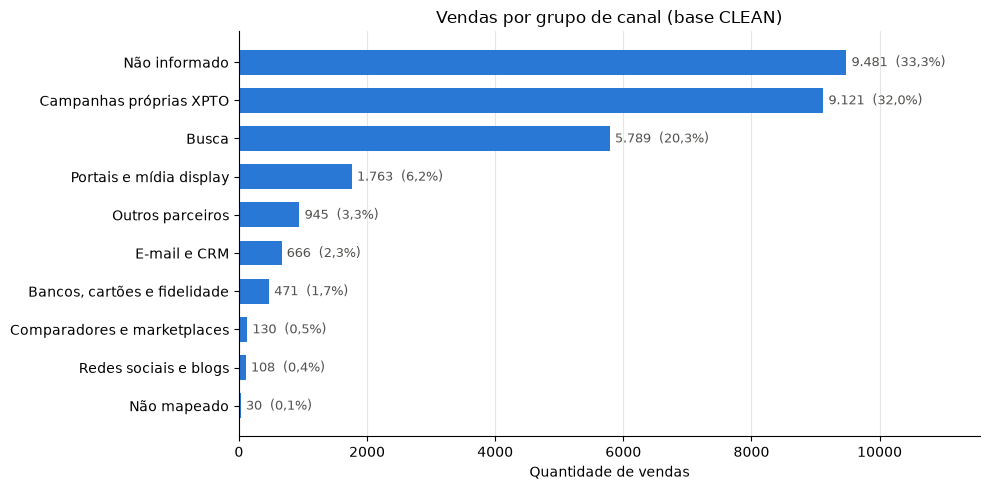

In [69]:
# Participação das vendas por grupo de canal
dados_grafico = resumo_grupos["vendas"].sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(dados_grafico.index, dados_grafico.values, color="#2a78d6", height=0.65)
for barra, qtd in zip(barras, dados_grafico.values):
    ax.text(barra.get_width() + 80, barra.get_y() + barra.get_height() / 2,
            f"{qtd:,}".replace(",", ".") + f"  ({qtd / len(df_clean) * 100:.1f}%)".replace(".", ","),
            va="center", color="#52514e", fontsize=9)
ax.set_title("Vendas por grupo de canal (base CLEAN)")
ax.set_xlabel("Quantidade de vendas")
ax.set_ylabel("")
ax.set_xlim(0, dados_grafico.max() * 1.22)
ax.grid(axis="x", color="#e5e5e3")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 7.5.5 Síntese do canal de venda

**Solução adotada:** o campo bruto foi preservado em `CanalVenda_Original` e decomposto em informações analisáveis:

- **`CanalVenda_Normalizado`:** grafia padronizada, sem parâmetros e sem duplicação. Os códigos de campanha foram mantidos.
- **`CanalVenda_Midia`:** o meio de comunicação extraído do parâmetro UTM, antes descartado ou "colado" ao nome do canal.
- **`GrupoCanal`:** a taxonomia de negócio, com regras ordenadas, explícitas e com uma rede de segurança para canais novos.
- **`flag_canal_multiplo`:** as vendas com mais de uma origem.

Nenhuma venda foi removida por problema de canal, e a ausência passou a ser uma **categoria explícita**, e não um valor que some silenciosamente de agregações. A seção 9.4 mostra como essa transformação muda a leitura de quais canais mais vendem.

**Por que o `CanalVenda_Normalizado` ainda tem centenas de valores?** Porque a normalização foi feita em **dois níveis**, cada um com um papel:

| Nível | Coluna | Cardinalidade | Pergunta que responde |
|---|---|---|---|
| Grafia | `CanalVenda_Normalizado` | 519 canais + "nao informado" | "Qual campanha ou origem específica gerou a venda?" |
| Negócio | `GrupoCanal` | 10 grupos | "Quanto vem de busca, parceiros, campanhas próprias, e-mail?" |

Todas as grafias **equivalentes** foram unificadas: caixa, acentos, parâmetros UTM, listas repetidas, barras e erros de digitação (602 → 519). O que sobrou são **códigos de campanha diferentes entre si** (433 deles no grupo de campanhas próprias XPTO), e não o mesmo canal escrito de formas diferentes. Juntar `xptoourmasc1` e `xptoourfem2` na coluna normalizada destruiria a informação de qual peça de campanha vendeu. O agrupamento de canais que "deveriam ser agrupados" (ex.: `google` e `yahoo` em Busca) é justamente o papel do `GrupoCanal`.

## 7.6 Geografia: região do cliente

A UF tem 27 valores, o que dificulta comparações com poucas vendas por estado. A coluna `Regiao` agrega as UFs nas cinco grandes regiões, a partir de um **dicionário de domínio** (divisão regional do IBGE, o Instituto Brasileiro de Geografia e Estatística). Ela é usada na seção 9.5 e fica disponível na base final. O `assert` garante que nenhuma UF fique sem região, o que protegeria o *pipeline* contra um código de UF inválido em uma carga futura.

In [70]:
REGIOES = {
    "Norte": ["AC", "AM", "AP", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MS", "MT"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sul": ["PR", "RS", "SC"],
}
UF_PARA_REGIAO = {uf: regiao for regiao, ufs in REGIOES.items() for uf in ufs}
assert set(UF_PARA_REGIAO) == UFS_VALIDAS, "Dicionário de regiões diferente do domínio de UFs (3.9)"

df_clean["Regiao"] = df_clean["UF_Cliente"].astype(str).map(UF_PARA_REGIAO).astype("category")
assert df_clean["Regiao"].notna().all(), "UF sem região"
registrar_etapa("7.6", "D. Transformar", len(df_clean), len(df_clean), len(df_clean), "Criação de Regiao")
frequencias(df_clean["Regiao"])

,quantidade,percentual
Regiao,,
Sudeste,13841,48.56
Nordeste,7523,26.39
Sul,3117,10.94
Centro-Oeste,2589,9.08
Norte,1434,5.03


## 7.7 Resumo das transformações

As células a seguir consolidam o que foi feito nas seções 6 e 7: o *log* de etapas, a contagem de registros modificados e removidos, e a lista de novas variáveis. Por último, confirmamos que o `df_raw` **permanece intocado**.

In [71]:
log_etapas_df = pd.DataFrame(log_etapas)
log_etapas_df.index = log_etapas_df.index + 1
with pd.option_context("display.max_colwidth", 110):
    display(log_etapas_df)

,etapa,decisao,linhas_antes,linhas_depois,registros_afetados,descricao
1,6.2,B. Remover,28505,28504,1,Remoção de duplicatas exatas (mantida a primeira ocorrência)
2,6.3,D. Transformar,28504,28504,28504,"Conversão de tipos: datas para datetime64, Cliente_Codigo para texto, 4 colunas para category"
3,6.4,A. Corrigir,28504,28504,282,Nascimentos sentinela ou posteriores à compra substituídos por NaT + flag_nascimento_invalido
4,6.5,A. Corrigir,28504,28504,77,ValorVenda arredondado para 2 casas (arredondamento comercial)
5,6.6,E. Marcar,28504,28504,891,Criação de flag_possivel_repeticao
6,6.6,E. Marcar,28504,28504,877,Criação de flag_cliente_atipico
7,6.6,C. Manter,28504,28504,223,Criação de flag_cliente_multi_uf
8,6.6,E. Marcar,28504,28504,742,Criação de flag_rajada_compras
9,7.1,D. Transformar,28504,28504,28504,"Derivação de Ano, Mes, AnoMes, Dia, DiaSemana, FimDeSemana, Hora e PeriodoDia"
10,7.2,E. Marcar,28504,28504,172,Criação de IdadeNaCompra e flag_idade_improvavel


In [72]:
log_registros_df = pd.concat(log_registros, ignore_index=True)

resumo_log = (log_registros_df.groupby(["etapa", "acao", "coluna", "motivo"])
              .agg(registros=("id_registro", "nunique")).reset_index())
with pd.option_context("display.max_colwidth", 90):
    display(resumo_log)

print(f"Registros removidos                  : {log_registros_df.loc[log_registros_df['acao'].eq('removido'), 'id_registro'].nunique()}")
print(f"Registros com algum valor modificado : {log_registros_df.loc[log_registros_df['acao'].eq('modificado'), 'id_registro'].nunique()}")
print(f"Linhas: RAW {len(df_raw):,} -> CLEAN {len(df_clean):,}")

,etapa,acao,coluna,motivo,registros
0,6.2,removido,(linha inteira),Duplicata exata de outro registro (todas as colunas originais iguais),1
1,6.4,modificado,Cliente_Data_Nascimento,Data sentinela (ano <= 1900) substituída por ausente,270
2,6.4,modificado,Cliente_Data_Nascimento,Nascimento posterior à data da compra substituído por ausente,12
3,6.5,modificado,ValorVenda,Valor com mais de 2 casas decimais arredondado para centavos,77


Registros removidos                  : 1
Registros com algum valor modificado : 358
Linhas: RAW 28,505 -> CLEAN 28,504


In [73]:
# Exemplo de rastreabilidade: as primeiras entradas do log, linha a linha
log_registros_df.head(8)

,id_registro,etapa,acao,coluna,valor_antes,valor_depois,motivo
0,6569,6.2,removido,(linha inteira),-,-,Duplicata exata de outro registro (todas as co...
1,2472,6.4,modificado,Cliente_Data_Nascimento,1900-01-01,NaT,Data sentinela (ano <= 1900) substituída por a...
2,2473,6.4,modificado,Cliente_Data_Nascimento,1900-01-01,NaT,Data sentinela (ano <= 1900) substituída por a...
3,2486,6.4,modificado,Cliente_Data_Nascimento,1900-11-11,NaT,Data sentinela (ano <= 1900) substituída por a...
4,2487,6.4,modificado,Cliente_Data_Nascimento,1900-11-11,NaT,Data sentinela (ano <= 1900) substituída por a...
5,2488,6.4,modificado,Cliente_Data_Nascimento,1900-11-11,NaT,Data sentinela (ano <= 1900) substituída por a...
6,2499,6.4,modificado,Cliente_Data_Nascimento,1900-01-01,NaT,Data sentinela (ano <= 1900) substituída por a...
7,2523,6.4,modificado,Cliente_Data_Nascimento,1900-01-01,NaT,Data sentinela (ano <= 1900) substituída por a...


In [74]:
colunas_novas = [c for c in df_clean.columns if c not in df_raw.columns]
DESCRICAO_NOVAS = {
    "id_registro": "Posição do registro no RAW (rastreabilidade)",
    "flag_nascimento_invalido": "Motivo da correção do nascimento: 'sentinela' ou 'posterior_compra'",
    "flag_possivel_repeticao": "Repete cliente e valor de venda anterior em até 60 min",
    "flag_cliente_atipico": "Cliente acima do percentil 99,9 de compras",
    "flag_cliente_multi_uf": "Cliente aparece com mais de uma UF",
    "Ano": "Ano da venda", "Mes": "Mês da venda (1-12)", "AnoMes": "Ano e mês (AAAA-MM)",
    "Dia": "Dia do mês", "DiaSemana": "Dia da semana em português (ordenado)",
    "FimDeSemana": "Venda no sábado ou domingo", "Hora": "Hora da venda (0-23)",
    "PeriodoDia": "Madrugada, Manhã, Tarde ou Noite",
    "IdadeNaCompra": "Idade exata do cliente na data da compra",
    "flag_idade_improvavel": "Idade < 16 ou > 100 anos",
    "FaixaEtaria": "Faixa etária (com 'Idade improvável' e 'Não informado')",
    "flag_valor_zero": "Venda com valor R$ 0,00",
    "flag_valor_extremo": "Valor acima de Q3 + 1,5 IQR (informativa)",
    "flag_pagamento_inconsistente": "Violação do domínio de pagamento (Id, tipo ou parcelas)",
    "flag_parcelas_zero": "Cartão de crédito com 0 parcelas",
    "ModalidadePagamento": "À vista, Parcelado ou Não informado",
    "ValorParcela": "Valor de cada parcela",
    "CanalVenda_Original": "Texto bruto do canal (preservado)",
    "CanalVenda_Normalizado": "Canal com grafia padronizada",
    "CanalVenda_Midia": "Mídia extraída do parâmetro utm_medium",
    "flag_canal_multiplo": "Venda com mais de uma origem distinta no canal",
    "GrupoCanal": "Taxonomia de negócio do canal",
    "Regiao": "Região do IBGE correspondente à UF",
    "flag_rajada_compras": "Cliente com 5+ compras no mesmo dia",
}
assert set(colunas_novas) == set(DESCRICAO_NOVAS), set(colunas_novas) ^ set(DESCRICAO_NOVAS)

novas = pd.DataFrame({"tipo": df_clean[colunas_novas].dtypes.astype(str),
                      "descricao": pd.Series(DESCRICAO_NOVAS)}).loc[colunas_novas]
print(f"Novas variáveis: {len(colunas_novas)} | colunas no df_clean: {df_clean.shape[1]}")
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 40):
    display(novas)

Novas variáveis: 29 | colunas no df_clean: 38


,tipo,descricao
id_registro,int64,Posição do registro no RAW (rastreabilidade)
flag_nascimento_invalido,str,Motivo da correção do nascimento: 'sentinela' ou 'posterior_compra'
flag_possivel_repeticao,bool,Repete cliente e valor de venda anterior em até 60 min
flag_cliente_atipico,bool,"Cliente acima do percentil 99,9 de compras"
flag_cliente_multi_uf,bool,Cliente aparece com mais de uma UF
flag_rajada_compras,bool,Cliente com 5+ compras no mesmo dia
Ano,int32,Ano da venda
Mes,int32,Mês da venda (1-12)
AnoMes,str,Ano e mês (AAAA-MM)
Dia,int32,Dia do mês


In [75]:
# Garantia final: o RAW não foi modificado em nenhuma etapa
hash_atual = pd.util.hash_pandas_object(df_raw, index=True).sum()
assert hash_atual == HASH_RAW, "O df_raw foi alterado!"
print(f"df_raw intacto: hash {hash_atual} idêntico ao calculado na leitura.")

# Resumo das flags de qualidade
flags = [c for c in df_clean.columns if c.startswith("flag_")]
# Flags booleanas: soma dos True; flag de motivo (texto): quantidade de preenchidos
resumo_flags = pd.Series({f: int(df_clean[f].sum() if pd.api.types.is_bool_dtype(df_clean[f])
                                 else df_clean[f].notna().sum())
                          for f in flags}, name="vendas_marcadas").to_frame()
resumo_flags["%"] = (resumo_flags["vendas_marcadas"] / len(df_clean) * 100).round(2)
resumo_flags

df_raw intacto: hash 14142524782292839979 idêntico ao calculado na leitura.


,vendas_marcadas,%
flag_nascimento_invalido,282,0.99
flag_possivel_repeticao,891,3.13
flag_cliente_atipico,877,3.08
flag_cliente_multi_uf,223,0.78
flag_rajada_compras,742,2.60
flag_idade_improvavel,172,0.60
flag_valor_zero,16,0.06
flag_valor_extremo,2083,7.31
flag_pagamento_inconsistente,0,0.00
flag_parcelas_zero,585,2.05


**Síntese das seções 6 e 7:**

- **Registros removidos:** apenas 1 (duplicata exata). A base CLEAN mantém 28.504 das 28.505 vendas.
- **Registros modificados:** nascimentos inválidos convertidos em ausentes e valores arredondados para centavos, todos rastreáveis no `log_registros_df` pelo `id_registro`.
- **Novas variáveis:** 29 colunas que não existiam no RAW com esse nome. Uma delas, `CanalVenda_Original`, é a `CanalVenda` renomeada, então são **28 variáveis realmente novas**: componentes de data, idade e faixa etária, região, atributos de pagamento, as colunas derivadas do canal, o `id_registro` e **11 *flags* de qualidade**. Com as 10 originais, a base final tem 38 colunas. Nenhuma coluna original teve seu conteúdo perdido: `CanalVenda` vive em `CanalVenda_Original`, e os valores originais de nascimento e de valor continuam no RAW.
- **Princípio seguido:** das anomalias encontradas, a maioria foi **marcada**, e não corrigida nem removida. A base CLEAN entrega **mais informação que a RAW**, não menos: além de cada dado, ela diz o quanto se pode confiar nele.

# 8. Comparação RAW × CLEAN

## 8.1 Contexto: o que um analista concluiria com a base bruta?

A pergunta desta seção é prática: **a preparação muda as respostas de negócio?** Para responder, os mesmos indicadores são calculados duas vezes:

- **RAW:** da forma como um analista faria se abrisse o arquivo e calculasse direto, com `value_counts()`, `mean()` e os valores como vieram.
- **CLEAN:** usando os atributos tratados e as *flags* de qualidade.

Foram escolhidos quatro indicadores, que cobrem as três frentes da preparação: canal, cliente e valor.

1. **Quantidade de canais de venda distintos:** o tamanho do "cardápio" de canais que o marketing enxerga.
2. **Participação dos canais nas vendas**, medida de duas formas:
   - **2a. Participação do `google`:** o **mesmo canal** medido nas duas bases. É a comparação mais justa, porque isola o efeito da limpeza (ausentes explícitos e grafias unificadas).
   - **2b. Principal origem de vendas:** o que cada base aponta como "líder". Aqui o CLEAN usa o `GrupoCanal`, então a diferença combina limpeza **e** taxonomia; o resultado é lido com essa ressalva.
3. **Idade média do cliente e participação de clientes com 65 anos ou mais:** o público-alvo. Nas duas bases a idade é calculada com a **mesma função exata** (`idade_na_data`, definida em 3.1), de modo que a diferença vem só da correção dos nascimentos inválidos e da exclusão das idades improváveis.
4. **Ticket médio:** indicador financeiro central.

In [76]:
# Indicador 1: quantidade de canais distintos
canais_raw = df_raw["CanalVenda"].nunique()
canais_clean_norm = df_clean.loc[df_clean["CanalVenda_Normalizado"] != ROTULO_AUSENTE, "CanalVenda_Normalizado"].nunique()
grupos_clean = df_clean.loc[~df_clean["GrupoCanal"].isin(["Não informado", GRUPO_NAO_MAPEADO]), "GrupoCanal"].nunique()

print(f"RAW  : {canais_raw} valores distintos em CanalVenda")
print(f"CLEAN: {canais_clean_norm} canais normalizados, agrupados em {grupos_clean} grupos de origem conhecida")

RAW  : 602 valores distintos em CanalVenda
CLEAN: 519 canais normalizados, agrupados em 8 grupos de origem conhecida


In [77]:
# Indicador 2: participação do principal canal
# RAW: value_counts() descarta os ausentes por padrão -> o percentual é calculado só sobre as vendas com canal
part_raw = df_raw["CanalVenda"].value_counts(normalize=True) * 100
principal_raw, pct_principal_raw = part_raw.index[0], part_raw.iloc[0]

# CLEAN: percentual sobre TODAS as vendas; 'Não informado' é uma categoria explícita
part_clean = df_clean["GrupoCanal"].value_counts(normalize=True) * 100
part_clean_conhecido = part_clean.drop(["Não informado", GRUPO_NAO_MAPEADO], errors="ignore")
principal_clean, pct_principal_clean = part_clean_conhecido.index[0], part_clean_conhecido.iloc[0]
pct_busca_clean = part_clean.get("Busca", 0)

# 2a. O mesmo canal nas duas bases: google
pct_google_raw = part_raw.get("google", 0)
pct_google_clean = df_clean["CanalVenda_Normalizado"].eq("google").mean() * 100
print(f"google -> RAW: {pct_google_raw:.2f}% (sobre vendas com canal) | CLEAN: {pct_google_clean:.2f}% (sobre todas as vendas)\n")

print(f"RAW  : principal canal = '{principal_raw}' com {pct_principal_raw:.2f}% das vendas")
print(f"CLEAN: principal grupo = '{principal_clean}' com {pct_principal_clean:.2f}% das vendas")
print(f"CLEAN: 'Busca' (google + yahoo + googleadwords) = {pct_busca_clean:.2f}% | "
      f"'Não informado' = {part_clean['Não informado']:.2f}%")
print("\nTop 5 RAW:")
print(part_raw.head(5).round(2).to_string())
print("\nTop 5 CLEAN (GrupoCanal):")
print(part_clean.head(5).round(2).to_string())

google -> RAW: 29.40% (sobre vendas com canal) | CLEAN: 19.62% (sobre todas as vendas)

RAW  : principal canal = 'google' com 29.40% das vendas
CLEAN: principal grupo = 'Campanhas próprias XPTO' com 32.00% das vendas
CLEAN: 'Busca' (google + yahoo + googleadwords) = 20.31% | 'Não informado' = 33.26%

Top 5 RAW:
CanalVenda
google         29.40
HiMidia         8.30
xptoourMasc1    3.29
AviseMe         2.33
xptoourFem1     2.33

Top 5 CLEAN (GrupoCanal):
GrupoCanal
Não informado             33.26
Campanhas próprias XPTO   32.00
Busca                     20.31
Portais e mídia display    6.19
Outros parceiros           3.32


In [78]:
# Indicador 3: idade média e participação de 65+
# RAW: idade exata (idade_na_data, 3.1) com todas as datas preenchidas, incluindo sentinelas e datas impossíveis
idade_raw = aux_idade.dropna().astype(float)
idade_media_raw = idade_raw.mean()
pct_65_raw = (idade_raw >= 65).mean() * 100

# CLEAN: mesma função, sem datas inválidas e sem idades improváveis
idade_valida = df_clean.loc[~df_clean["flag_idade_improvavel"], "IdadeNaCompra"].dropna().astype(float)
idade_media_clean = idade_valida.mean()
pct_65_clean = (idade_valida >= 65).mean() * 100

print(f"Idade média  -> RAW: {idade_media_raw:.2f} | CLEAN: {idade_media_clean:.2f}")
print(f"% 65 ou mais -> RAW: {pct_65_raw:.2f}% | CLEAN: {pct_65_clean:.2f}%")

Idade média  -> RAW: 32.62 | CLEAN: 31.98
% 65 ou mais -> RAW: 2.41% | CLEAN: 1.39%


In [79]:
# Indicador 4: ticket médio
ticket_raw = df_raw["ValorVenda"].mean()
ticket_clean = df_clean.loc[~df_clean["flag_valor_zero"], "ValorVenda"].mean()
ticket_clean_sem_rep = df_clean.loc[~df_clean["flag_valor_zero"] & ~df_clean["flag_possivel_repeticao"], "ValorVenda"].mean()

print(f"Ticket médio -> RAW: {ticket_raw:,.2f} | CLEAN (sem valor zero): {ticket_clean:,.2f} | "
      f"CLEAN (sem valor zero e sem possíveis repetições): {ticket_clean_sem_rep:,.2f}")

Ticket médio -> RAW: 314.61 | CLEAN (sem valor zero): 314.80 | CLEAN (sem valor zero e sem possíveis repetições): 318.71


## 8.2 Tabela comparativa

In [80]:
def fmt_pct(x):
    return f"{x:.2f}%".replace(".", ",")


def fmt_num(x, casas=2):
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


comparacao_raw_clean = pd.DataFrame([
    ("Quantidade de canais distintos", f"{canais_raw}",
     f"{canais_clean_norm} normalizados / {grupos_clean} grupos",
     f"-{canais_raw - canais_clean_norm} grafias; {grupos_clean} grupos analisáveis"),
    ("Participação do google nas vendas (mesmo canal)", fmt_pct(pct_google_raw), fmt_pct(pct_google_clean),
     f"{fmt_num(pct_google_clean - pct_google_raw)} p.p. (ausentes passam a contar no denominador)"),
    ("Principal origem de vendas (CLEAN por GrupoCanal)", f"{principal_raw}: {fmt_pct(pct_principal_raw)}",
     f"{principal_clean}: {fmt_pct(pct_principal_clean)}",
     f"Líder muda (limpeza + taxonomia); Busca = {fmt_pct(pct_busca_clean)}"),
    ("Idade média do cliente (anos)", fmt_num(idade_media_raw), fmt_num(idade_media_clean),
     f"{fmt_num(idade_media_clean - idade_media_raw)} anos"),
    ("Clientes com 65 anos ou mais (% das vendas com idade)", fmt_pct(pct_65_raw), fmt_pct(pct_65_clean),
     f"{fmt_num(pct_65_clean - pct_65_raw)} p.p. ({fmt_num((pct_65_clean / pct_65_raw - 1) * 100, 1)}%)"),
    ("Ticket médio (R$)", fmt_num(ticket_raw), fmt_num(ticket_clean), f"{fmt_num(ticket_clean - ticket_raw)}"),
], columns=["Indicador", "Base RAW", "Base CLEAN", "Diferença"])

with pd.option_context("display.max_colwidth", None):
    display(comparacao_raw_clean)

,Indicador,Base RAW,Base CLEAN,Diferença
0,Quantidade de canais distintos,602,519 normalizados / 8 grupos,-83 grafias; 8 grupos analisáveis
1,Participação do google nas vendas (mesmo canal),"29,40%","19,62%","-9,78 p.p. (ausentes passam a contar no denominador)"
2,Principal origem de vendas (CLEAN por GrupoCanal),"google: 29,40%","Campanhas próprias XPTO: 32,00%","Líder muda (limpeza + taxonomia); Busca = 20,31%"
3,Idade média do cliente (anos),"32,62","31,98","-0,64 anos"
4,Clientes com 65 anos ou mais (% das vendas com idade),"2,41%","1,39%","-1,02 p.p. (-42,3%)"
5,Ticket médio (R$),"314,61","314,80","0,18"


## 8.3 Interpretação: alguma decisão gerencial seria diferente?

**Sim, pelo menos duas decisões gerenciais seriam diferentes, e uma não mudaria.**

- **Caso 1 — investimento em canais (o mais relevante):** na base bruta, o `google` aparece com **29,40%** das vendas, e a conclusão natural seria concentrar a verba em busca. O número está inflado porque `value_counts()` descarta as 9.482 vendas sem canal. Medido na base tratada, o **mesmo canal** responde por **19,62%** do total (−9,78 p.p.), e a busca inteira (google, yahoo e googleadwords) por **20,31%**. Olhando os grupos de origem, o maior é o das **campanhas próprias XPTO (32,00%)**, que no RAW ficavam invisíveis por estar fragmentadas em centenas de códigos, nenhum acima de 3,3%. Além disso, **um terço das vendas (33,26%) não tem origem**. Com os dados limpos, a primeira decisão seria **investir em rastreamento**, e não redistribuir a verba entre canais.
- **Caso 2 — dimensionamento de público:** a base bruta indica que **2,41%** das vendas com idade são de clientes com 65 anos ou mais. A tratada mostra **1,39%**. O sentinela `1900-01-01` cria "clientes de 110 anos", e uma ação voltada à terceira idade seria planejada para um público cerca de **1,7 vez maior** que o real. A idade média cai de 32,62 para 31,98 anos (−0,64): como as duas bases usam a mesma função de idade, essa diferença vem **só** da limpeza. Parece pouco na média, mas a distorção se concentra justamente na faixa de idosos, como mostra o indicador anterior.
- **Caso 3 — ticket médio (não muda):** R$ 314,61 no RAW contra R$ 314,80 no CLEAN. Mesmo excluindo as possíveis repetições, o ticket vai a R$ 318,71, cerca de 1% acima. **Decisões de preço e de meta de faturamento seriam as mesmas.** Isso também é um resultado: os problemas desta base estão nos atributos **descritivos** (canal e cliente), e não no valor das vendas, que foi preservado. Nem toda limpeza muda todos os números, e mostrar onde ela **não** muda dá credibilidade às diferenças onde ela muda.

# 9. Perguntas de negócio

## 9.0 Contexto: regras usadas em todas as análises

Todas as análises usam **somente o `df_clean`**. Para que os resultados sejam comparáveis, três convenções valem para a seção inteira:

- **Ticket médio** exclui `flag_valor_zero`: uma venda de R$ 0,00 não representa preço pago.
- **Mediana ao lado da média:** a distribuição de valores é assimétrica (3.7), e a mediana mostra o valor "típico" sem a influência da cauda.
- **Grupos pequenos são sinalizados:** categorias com poucas vendas (por exemplo, `Glamour VIP`, com 3) aparecem nas tabelas, mas não sustentam conclusões.

A função `estilo_eixo` padroniza os gráficos: grade discreta atrás das barras e sem bordas superiores e direitas.

In [81]:
COR_PRINCIPAL = "#2a78d6"
COR_SECUNDARIA = "#eb6834"
COR_TEXTO = "#52514e"
plt.rcParams["text.parse_math"] = False  # "R$" nos rótulos não deve virar fórmula matemática
vendas_validas = df_clean[~df_clean["flag_valor_zero"]]


def estilo_eixo(ax, titulo, xlabel, ylabel, eixo_grade="y"):
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis=eixo_grade, color="#e5e5e3")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


def formato_br(x, _=None):
    return f"{x:,.0f}".replace(",", ".")

## 9.1 Evolução das vendas ao longo do período

Como janeiro (a partir do dia 10) e agosto (até o dia 28) são meses **parciais** (2.4), comparar totais mensais seria injusto. A medida principal é a **média de vendas por dia com venda**, calculada dividindo o total do mês pelo número de dias em que houve vendas.

In [82]:
evolucao = df_clean.groupby("AnoMes").agg(
    vendas=("id_registro", "size"),
    faturamento=("ValorVenda", "sum"),
    dias_com_venda=("DataVenda", lambda s: s.dt.normalize().nunique()),
)
evolucao["vendas_por_dia"] = (evolucao["vendas"] / evolucao["dias_com_venda"]).round(1)
evolucao["faturamento_por_dia"] = (evolucao["faturamento"] / evolucao["dias_com_venda"]).round(2)
evolucao["ticket_medio"] = vendas_validas.groupby("AnoMes")["ValorVenda"].mean().round(2)
evolucao["variacao_vendas_dia_%"] = (evolucao["vendas_por_dia"].pct_change() * 100).round(1)
evolucao

,vendas,faturamento,dias_com_venda,vendas_por_dia,faturamento_por_dia,ticket_medio,variacao_vendas_dia_%
AnoMes,,,,,,,
2011-01,2426,"772,421.14",22,110.30,"35,110.05",318.39,NaN
2011-02,3395,"1,027,789.22",28,121.20,"36,706.76",302.74,9.90
2011-03,3142,"1,018,497.75",31,101.40,"32,854.77",324.16,-16.30
2011-04,2984,"964,974.31",30,99.50,"32,165.81",323.60,-1.90
2011-05,3800,"1,198,566.03",31,122.60,"38,663.42",316.08,23.20
2011-06,3977,"1,325,249.54",30,132.60,"44,174.98",333.31,8.20
2011-07,4983,"1,518,670.94",31,160.70,"48,989.39",304.89,21.20
2011-08,3797,"1,141,726.21",28,135.60,"40,775.94",300.93,-15.60


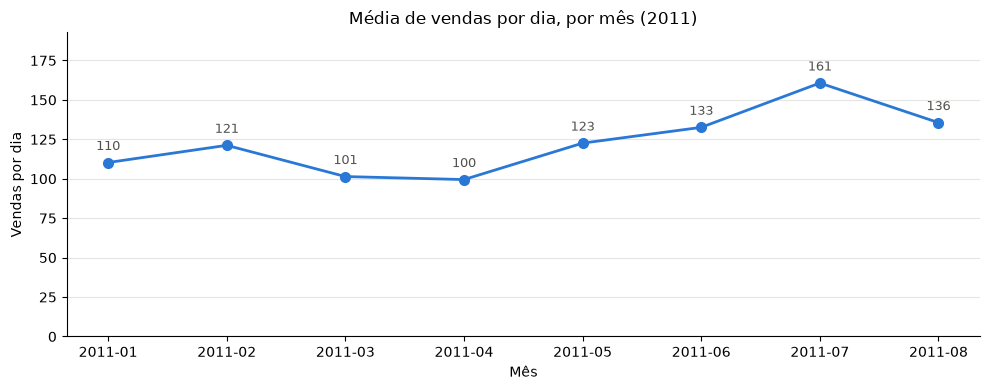

In [83]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(evolucao.index, evolucao["vendas_por_dia"], color=COR_PRINCIPAL, linewidth=2, marker="o", markersize=7)
for mes, valor_mes in evolucao["vendas_por_dia"].items():
    ax.annotate(f"{valor_mes:.0f}", (mes, valor_mes), textcoords="offset points", xytext=(0, 9),
                ha="center", color=COR_TEXTO, fontsize=9)
ax.set_ylim(0, evolucao["vendas_por_dia"].max() * 1.2)
estilo_eixo(ax, "Média de vendas por dia, por mês (2011)", "Mês", "Vendas por dia")
plt.tight_layout()
plt.show()

In [84]:
# Padrão semanal complementar: vendas médias por dia da semana
dias_por_semana = df_clean.groupby("DiaSemana", observed=True)["DataVenda"].apply(lambda s: s.dt.normalize().nunique())
vendas_semana = df_clean.groupby("DiaSemana", observed=True).size()
(vendas_semana / dias_por_semana).round(1).rename("vendas_por_dia").to_frame().T

DiaSemana,Segunda,Terça,Quarta,Quinta,Sexta,Sábado,Domingo
vendas_por_dia,149.90,144.90,146.80,159.50,117.00,73.90,71.60


**Conclusão:**

- **Crescimento:** a média de vendas por dia cresce de **110** em janeiro para **161** em julho (+46%), com uma queda em março e abril (cerca de 100 por dia) e aceleração a partir de maio. O faturamento por dia acompanha: de R$ 35,1 mil para R$ 49,0 mil.
- **Origem do crescimento:** o ticket médio fica estável entre R$ 301 e R$ 333 ao longo dos meses. **O crescimento vem do volume de pedidos, não do preço.**
- **Agosto:** a queda para 136 vendas por dia (−15,6%) precisa ser lida com cuidado, porque parte do volume do mês vem de um único cliente (9.6). Sem ele, agosto fica em cerca de 128 vendas por dia. O pico de julho pode refletir sazonalidade (férias, liquidações), mas a base não tem o ano anterior para confirmar essa hipótese.
- **Padrão semanal:** de segunda a quinta, a loja vende entre 145 e 160 pedidos por dia. Na sexta, 117. No sábado e no domingo, cerca de 72 a 74, **metade de um dia útil**. O comportamento indica compras feitas principalmente em horário de trabalho, o que é relevante para agendar campanhas e disparos de e-mail.

## 9.2 Diferença de ticket entre formas de pagamento

In [85]:
ticket_forma = vendas_validas.groupby("FormaPagamento", observed=True)["ValorVenda"].agg(
    vendas="size", ticket_medio="mean", ticket_mediano="median",
    q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75)).round(2)
ticket_forma["amostra"] = np.where(ticket_forma["vendas"] < 30, "insuficiente (< 30)", "ok")
ticket_forma.sort_values("ticket_mediano", ascending=False)

,vendas,ticket_medio,ticket_mediano,q1,q3,amostra
FormaPagamento,,,,,,
Diners,236,410.45,332.26,199.00,513.52,ok
MasterCard,8420,314.59,231.00,143.19,369.00,ok
Visa,11805,315.34,230.00,139.30,369.00,ok
Boleto Bancário,7527,316.89,199.00,109.00,329.00,ok
Cupom de Desconto,497,229.36,164.00,90.00,259.00,ok
Glamour VIP,3,92.00,69.00,58.50,114.00,insuficiente (< 30)


In [86]:
# Ticket por modalidade e por número de parcelas
display(vendas_validas.groupby("ModalidadePagamento")["ValorVenda"]
        .agg(vendas="size", ticket_medio="mean", ticket_mediano="median").round(2))
display(vendas_validas.groupby("NumeroParcelas")["ValorVenda"]
        .agg(vendas="size", ticket_medio="mean", ticket_mediano="median").round(2).T)

,vendas,ticket_medio,ticket_mediano
ModalidadePagamento,,,
Não informado,585,92.66,69.00
Parcelado,16572,336.53,249.00
À vista,11331,294.48,196.00


NumeroParcelas,0,1,2,3,4,5,6,7,8,9,10
vendas,585.00,"11,331.00","2,787.00","2,583.00","2,586.00","1,727.00","1,405.00",642.00,659.00,504.00,"3,679.00"
ticket_medio,92.66,294.48,193.83,239.65,248.92,312.83,359.06,349.96,339.22,332.23,574.50
ticket_mediano,69.00,196.00,129.00,179.00,199.00,236.30,277.00,299.00,328.00,269.00,456.00


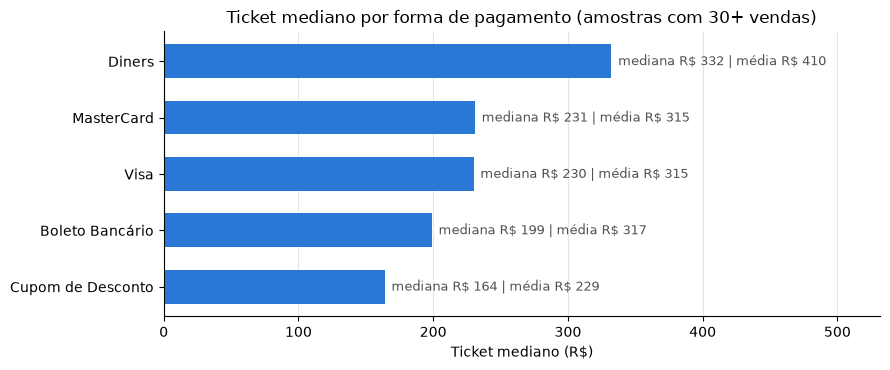

In [87]:
dados = ticket_forma[ticket_forma["amostra"] == "ok"].sort_values("ticket_mediano")
fig, ax = plt.subplots(figsize=(9, 3.8))
barras = ax.barh(dados.index.astype(str), dados["ticket_mediano"], color=COR_PRINCIPAL, height=0.6)
for barra, med, media in zip(barras, dados["ticket_mediano"], dados["ticket_medio"]):
    ax.text(barra.get_width() + 5, barra.get_y() + barra.get_height() / 2,
            f"mediana R$ {med:,.0f} | média R$ {media:,.0f}".replace(",", "."), va="center", color=COR_TEXTO, fontsize=9)
ax.set_xlim(0, dados["ticket_mediano"].max() * 1.6)
estilo_eixo(ax, "Ticket mediano por forma de pagamento (amostras com 30+ vendas)", "Ticket mediano (R$)", "", "x")
plt.tight_layout()
plt.show()

**Conclusão:**

- **`Diners`** tem o maior ticket: mediana de R$ 332 e média de R$ 410. É uma bandeira tradicionalmente associada a clientes de maior renda, mas essa é uma hipótese que a base não permite confirmar.
- **`Visa` e `MasterCard`** são praticamente idênticos: mediana de R$ 230 e R$ 231, média de R$ 315.
- **`Boleto Bancário`** tem mediana **menor** (R$ 199), mas média **igual** à dos cartões (R$ 317). A distribuição é mais dispersa: muitas compras pequenas e algumas muito grandes. As maiores vendas da base, como a de R$ 17.016,25, foram em boleto, o que é coerente com compras de alto valor feitas por quem prefere não usar o limite do cartão.
- **`Cupom de Desconto`** tem o menor ticket entre as formas com amostra suficiente: mediana de R$ 164.
- **`Glamour VIP`** (3 vendas) não permite conclusão.

**A diferença mais forte, porém, não está na forma de pagamento, e sim no parcelamento.** O ticket mediano das vendas parceladas é R$ 249, contra R$ 196 à vista, e cresce com o número de parcelas: R$ 129 em 2x e R$ 456 em 10x. O parcelamento é o que viabiliza os pedidos de maior valor.

## 9.3 Perfil etário dos clientes

A análise usa `FaixaEtaria` e considera apenas as vendas com **idade válida**, ou seja, sem `Não informado` e sem `Idade improvável`. A participação desses dois grupos é informada à parte, para deixar claro sobre qual parcela da base a conclusão se apoia.

Como um cliente pode comprar várias vezes, o perfil é mostrado de duas formas: **por venda** (quem gera o volume) e **por cliente** (quem é a base de compradores).

In [88]:
faixas_validas = FAIXAS_ETARIAS["rotulos"]
com_idade = df_clean[df_clean["FaixaEtaria"].isin(faixas_validas)]

print(f"Vendas com idade válida: {len(com_idade):,} ({len(com_idade) / len(df_clean) * 100:.1f}% da base)")
print(f"Não informado: {(df_clean['FaixaEtaria'] == 'Não informado').sum():,} | "
      f"Idade improvável: {(df_clean['FaixaEtaria'] == 'Idade improvável').sum():,}")

perfil_etario = pd.DataFrame({
    "%_vendas": com_idade["FaixaEtaria"].value_counts(normalize=True) * 100,
    "%_clientes": com_idade.drop_duplicates("Cliente_Codigo")["FaixaEtaria"].value_counts(normalize=True) * 100,
    "ticket_mediano": com_idade[~com_idade["flag_valor_zero"]].groupby("FaixaEtaria", observed=True)["ValorVenda"].median(),
    "%_parcelado": com_idade.groupby("FaixaEtaria", observed=True)["ModalidadePagamento"]
                   .apply(lambda s: (s == "Parcelado").mean() * 100),
}).loc[faixas_validas].round(1)
perfil_etario

Vendas com idade válida: 25,417 (89.2% da base)
Não informado: 2,915 | Idade improvável: 172


,%_vendas,%_clientes,ticket_mediano,%_parcelado
FaixaEtaria,,,,
16–17,1.40,1.70,139.00,34.40
18–24,27.70,28.20,188.00,52.30
25–34,39.40,39.00,211.60,58.80
35–44,16.90,16.40,249.00,59.40
45–54,9.30,9.20,269.00,63.70
55–64,3.90,4.00,289.00,65.10
65 ou mais,1.40,1.40,279.00,59.50


count   25,417.00
mean        32.00
std         11.30
min         16.00
25%         23.00
50%         29.00
75%         37.00
max        100.00


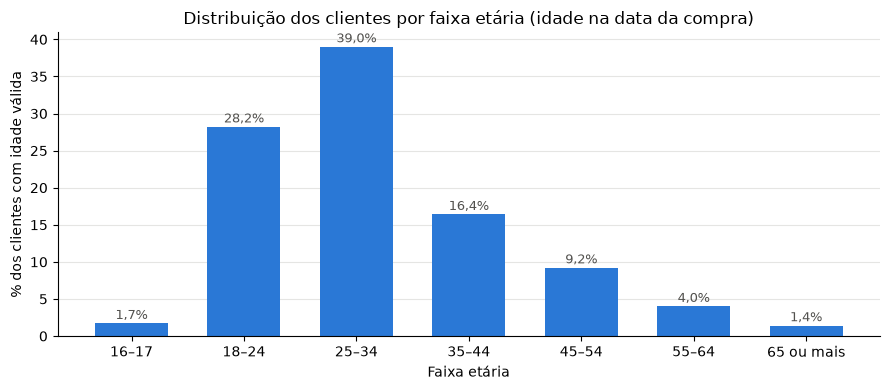

In [89]:
print(com_idade["IdadeNaCompra"].astype(float).describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(perfil_etario.index, perfil_etario["%_clientes"], color=COR_PRINCIPAL, width=0.65)
for i, v in enumerate(perfil_etario["%_clientes"]):
    ax.text(i, v + 0.6, f"{v:.1f}%".replace(".", ","), ha="center", color=COR_TEXTO, fontsize=9)
estilo_eixo(ax, "Distribuição dos clientes por faixa etária (idade na data da compra)", "Faixa etária",
            "% dos clientes com idade válida")
plt.tight_layout()
plt.show()

**Conclusão:** a base de clientes é **jovem**.

- **Concentração:** a faixa de **25 a 34 anos** reúne 39,0% dos clientes, e somada à de 18 a 24 chega a **67,2%**. A mediana de idade é 29 anos e a média, 32. Clientes com 55 anos ou mais somam apenas 5,4%.
- **Valor por faixa:** o ticket mediano **cresce com a idade**, de R$ 188 (18 a 24) para R$ 289 (55 a 64). O uso de parcelamento também, de 52,3% para 65,1%. Os clientes mais velhos são poucos, mas compram mais caro por pedido.
- **16 e 17 anos:** a faixa "16–17" (1,7%) tem o menor ticket (R$ 139) e o menor uso de parcelamento (34,4%), coerente com menos acesso a cartão de crédito.

**Ressalva:** 10,8% das vendas estão fora desta análise (não informado ou idade improvável). Se esses clientes tiverem perfil diferente, as proporções mudam. A base não permite avaliar esse viés.

## 9.4 Canais com maior volume de vendas

A resposta é dada em dois níveis: o **grupo de canal**, que mostra de onde vem o tráfego, e o **canal normalizado**, que mostra quais origens específicas mais vendem. Em seguida, o mesmo *ranking* é feito com o `CanalVenda_Original` para mostrar por que ele levaria a conclusões inadequadas.

In [90]:
ranking_grupo = df_clean.groupby("GrupoCanal").agg(
    vendas=("id_registro", "size"), faturamento=("ValorVenda", "sum"),
    ticket_mediano=("ValorVenda", "median"), canais=("CanalVenda_Normalizado", "nunique"))
ranking_grupo["%_vendas"] = ranking_grupo["vendas"] / len(df_clean) * 100
ranking_grupo["%_faturamento"] = ranking_grupo["faturamento"] / df_clean["ValorVenda"].sum() * 100
ranking_grupo.sort_values("vendas", ascending=False).round(2)

,vendas,faturamento,ticket_mediano,canais,%_vendas,%_faturamento
GrupoCanal,,,,,,
Não informado,9481,"3,120,512.67",214.00,1,33.26,34.80
Campanhas próprias XPTO,9121,"2,888,667.46",233.30,433,32.00,32.21
Busca,5789,"1,830,594.49",219.00,3,20.31,20.41
Portais e mídia display,1763,"464,315.87",198.00,19,6.19,5.18
Outros parceiros,945,"270,898.85",202.00,35,3.32,3.02
E-mail e CRM,666,"186,171.15",204.80,10,2.34,2.08
"Bancos, cartões e fidelidade",471,"121,992.71",209.00,13,1.65,1.36
Comparadores e marketplaces,130,"31,524.40",198.00,2,0.46,0.35
Redes sociais e blogs,108,"39,748.46",179.12,4,0.38,0.44


In [91]:
# Top 10 canais específicos (normalizados, com origem conhecida)
top_norm = (df_clean[df_clean["CanalVenda_Normalizado"] != ROTULO_AUSENTE]
            .groupby(["CanalVenda_Normalizado", "GrupoCanal"]).size().rename("vendas")
            .sort_values(ascending=False).head(10).reset_index())
top_norm["grafias_originais"] = top_norm["CanalVenda_Normalizado"].map(
    df_clean.groupby("CanalVenda_Normalizado")["CanalVenda_Original"].nunique())
top_norm

,CanalVenda_Normalizado,GrupoCanal,vendas,grafias_originais
0,google,Busca,5593,1
1,himidia,Portais e mídia display,1578,1
2,xptoourmasc1,Campanhas próprias XPTO,652,2
3,xptoourfem1,Campanhas próprias XPTO,461,2
4,aviseme,E-mail e CRM,444,1
5,xptoourfem2,Campanhas próprias XPTO,276,2
6,xptoourncl,Campanhas próprias XPTO,267,9
7,visavale,"Bancos, cartões e fidelidade",246,1
8,xptoourncl1,Campanhas próprias XPTO,231,2
9,xptosfolder,Campanhas próprias XPTO,217,1


**Por que o `CanalVenda` original levaria a uma conclusão inadequada?** O código abaixo compara o *ranking* ingênuo sobre o campo bruto com o *ranking* tratado, medindo quatro distorções.

In [92]:
ranking_raw = df_raw["CanalVenda"].value_counts()

# Distorção 1: a ausência some do ranking bruto e infla a participação dos demais
print("Distorção 1 — ausência invisível")
print(f"  Vendas sem canal: {df_raw['CanalVenda'].isna().sum():,} "
      f"({df_raw['CanalVenda'].isna().mean() * 100:.1f}%) -> não aparecem em value_counts()")
print(f"  google: {pct_principal_raw:.1f}% no RAW (sobre vendas com canal) vs "
      f"{df_clean['CanalVenda_Normalizado'].eq('google').mean() * 100:.1f}% do total real de vendas\n")

# Distorção 2: fragmentação de um mesmo canal em várias grafias
print("Distorção 2 — fragmentação")
frag = (df_clean.groupby("CanalVenda_Normalizado")
        .agg(grafias=("CanalVenda_Original", "nunique"), vendas=("id_registro", "size"),
             maior_grafia=("CanalVenda_Original", lambda s: s.value_counts().iloc[0] if s.notna().any() else 0)))
frag = frag[frag["grafias"] > 1].sort_values("vendas", ascending=False)
print(f"  Canais normalizados com mais de uma grafia no original: {len(frag)}")
print(frag.head(6).to_string(), "\n")

# Distorção 3: um meio inteiro (e-mail) fica invisível
email = df_clean["GrupoCanal"].eq("E-mail e CRM")
maior_valor_email_raw = df_clean.loc[email, "CanalVenda_Original"].value_counts().iloc[0]
print("Distorção 3 — meio invisível")
print(f"  'E-mail e CRM' soma {email.sum()} vendas; no RAW está espalhado em "
      f"{df_clean.loc[email, 'CanalVenda_Original'].nunique()} grafias (a maior tem {maior_valor_email_raw})\n")

# Distorção 4: concentração em um único cliente
himidia = df_clean["CanalVenda_Normalizado"].eq("himidia")
atipico_himidia = df_clean.loc[himidia, "flag_cliente_atipico"].sum()
print("Distorção 4 — concentração")
print(f"  himidia: {himidia.sum():,} vendas, das quais {atipico_himidia} ({atipico_himidia / himidia.sum() * 100:.1f}%) "
      f"de clientes atípicos")

Distorção 1 — ausência invisível
  Vendas sem canal: 9,482 (33.3%) -> não aparecem em value_counts()
  google: 29.4% no RAW (sobre vendas com canal) vs 19.6% do total real de vendas

Distorção 2 — fragmentação
  Canais normalizados com mais de uma grafia no original: 68
                        grafias  vendas  maior_grafia
CanalVenda_Normalizado                               
xptoourmasc1                  2     652           626
xptoourfem1                   2     461           443
xptoourfem2                   2     276           241
xptoourncl                    9     267           150
xptoourncl1                   2     231           230
xptockjh                      2     193           192 

Distorção 3 — meio invisível
  'E-mail e CRM' soma 666 vendas; no RAW está espalhado em 13 grafias (a maior tem 444)

Distorção 4 — concentração
  himidia: 1,578 vendas, das quais 241 (15.3%) de clientes atípicos


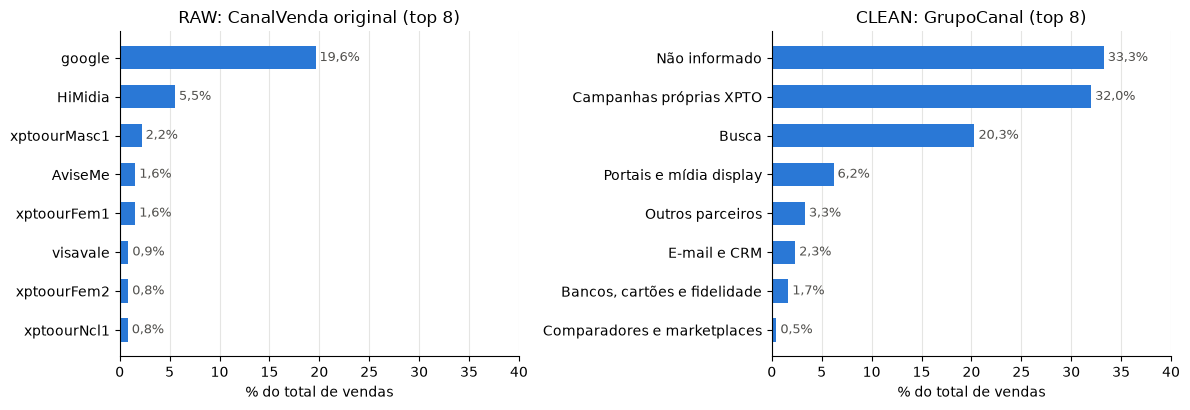

In [93]:
# Visual: os 8 maiores do ranking bruto x os 8 maiores grupos tratados
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bruto = (ranking_raw / len(df_raw) * 100).head(8).sort_values()
tratado = (df_clean["GrupoCanal"].value_counts(normalize=True) * 100).head(8).sort_values()
for ax, dados_rank, titulo in [(axes[0], bruto, "RAW: CanalVenda original (top 8)"),
                               (axes[1], tratado, "CLEAN: GrupoCanal (top 8)")]:
    ax.barh(dados_rank.index, dados_rank.values, color=COR_PRINCIPAL, height=0.6)
    for i, v in enumerate(dados_rank.values):
        ax.text(v + 0.4, i, f"{v:.1f}%".replace(".", ","), va="center", color=COR_TEXTO, fontsize=9)
    ax.set_xlim(0, 40)
    estilo_eixo(ax, titulo, "% do total de vendas", "", "x")
plt.tight_layout()
plt.show()

**Conclusão:**

- **Grupos de canal:** as vendas vêm, em ordem, de campanhas próprias XPTO (32,0%), busca (20,3%) e portais e mídia display (6,2%). Um terço (33,3%) não tem origem registrada, e o grupo "Não informado" fatura R$ 3,1 milhões, o maior volume individual.
- **Canais individuais:** `google` é o maior canal específico (5.593 vendas, 19,6% do total), seguido por `himidia` (1.578) e pela campanha `xptoourmasc1` (652).

**Por que o `CanalVenda` original levaria a uma conclusão inadequada:**

1. **Ausência invisível:** `value_counts()` descarta os 9.482 ausentes, e os percentuais passam a ser calculados sobre dois terços da base. O `google` sobe de 19,6% para 29,4%.
2. **Fragmentação:** 68 canais aparecem com mais de uma grafia. `xptoourncl` soma 267 vendas em **9 grafias**, e a maior delas tem só 150. Um ranking pelo campo bruto subestima esses canais.
3. **Meio invisível:** o e-mail (`utm_medium=Newsletter` e `AviseMe`) soma 666 vendas em 13 grafias. E as campanhas próprias, o **maior grupo da empresa**, não aparecem como relevantes no bruto, porque nenhum código isolado passa de 3,3%.
4. **Concentração:** 15,3% das vendas do `himidia` vêm de clientes atípicos. Sem essa informação, o canal parece mais forte do que é (9.6).

No gráfico, os dois painéis usam o mesmo denominador (total de vendas). Mesmo assim, o painel RAW **não mostra** o terço de vendas sem canal nem o peso das campanhas próprias.

Em resumo, o campo bruto responde "qual **grafia** aparece mais", e não "qual **canal** vende mais".

## 9.5 Diferenças relevantes entre estados brasileiros

Além das UFs, as vendas são agregadas por **região** (Norte, Nordeste, Centro-Oeste, Sudeste e Sul), usando a coluna `Regiao` criada na seção 7.6.

Os indicadores comparados são: volume, ticket (média e mediana), uso de boleto e uso de parcelamento. Como algumas UFs têm poucas vendas, as conclusões por UF consideram apenas as que têm **pelo menos 100 vendas**.

In [94]:
def indicadores_geo(df, chave):
    base = df.groupby(chave, observed=True).agg(
        vendas=("id_registro", "size"), faturamento=("ValorVenda", "sum"),
        ticket_medio=("ValorVenda", "mean"), ticket_mediano=("ValorVenda", "median"),
        pct_boleto=("FormaPagamento", lambda s: (s == "Boleto Bancário").mean() * 100),
        pct_parcelado=("ModalidadePagamento", lambda s: (s == "Parcelado").mean() * 100))
    base["%_vendas"] = base["vendas"] / base["vendas"].sum() * 100
    return base.sort_values("vendas", ascending=False).round(2)


por_regiao = indicadores_geo(vendas_validas, "Regiao")
por_regiao

,vendas,faturamento,ticket_medio,ticket_mediano,pct_boleto,pct_parcelado,%_vendas
Regiao,,,,,,,
Sudeste,13836,"4,453,172.91",321.85,233.30,23.32,60.51,48.57
Nordeste,7521,"2,169,274.13",288.43,199.00,30.13,57.04,26.40
Sul,3113,"1,048,502.69",336.81,233.30,26.66,55.16,10.93
Centro-Oeste,2584,"842,562.86",326.07,208.00,27.71,56.66,9.07
Norte,1434,"454,382.55",316.86,208.00,34.03,50.84,5.03


In [95]:
por_uf = indicadores_geo(vendas_validas, "UF_Cliente")
por_uf["Regiao"] = por_uf.index.astype(str).map(UF_PARA_REGIAO)
uf_relevantes = por_uf[por_uf["vendas"] >= 100]
print(f"UFs com 100+ vendas: {len(uf_relevantes)} de {len(por_uf)}")

print("\nMaiores e menores tickets medianos (UFs com 100+ vendas):")
display(uf_relevantes.sort_values("ticket_mediano", ascending=False)
        [["Regiao", "vendas", "ticket_mediano", "ticket_medio", "pct_boleto", "pct_parcelado"]].iloc[[0, 1, 2, -3, -2, -1]])

print("Maior e menor uso de boleto (UFs com 100+ vendas):")
display(uf_relevantes.sort_values("pct_boleto", ascending=False)
        [["Regiao", "vendas", "pct_boleto", "pct_parcelado", "ticket_mediano"]].iloc[[0, 1, 2, -3, -2, -1]])

UFs com 100+ vendas: 23 de 27

Maiores e menores tickets medianos (UFs com 100+ vendas):


,Regiao,vendas,ticket_mediano,ticket_medio,pct_boleto,pct_parcelado
UF_Cliente,,,,,,
AL,Nordeste,402,255.50,326.62,34.83,51.74
PB,Nordeste,440,249.00,316.29,32.27,57.73
RO,Norte,212,247.50,467.02,35.38,50.00
RN,Nordeste,581,181.96,222.03,19.97,63.51
SE,Nordeste,147,181.00,208.72,34.69,53.06
TO,Norte,313,179.00,283.10,39.62,45.37


Maior e menor uso de boleto (UFs com 100+ vendas):


,Regiao,vendas,pct_boleto,pct_parcelado,ticket_mediano
UF_Cliente,,,,,
TO,Norte,313,39.62,45.37,179.00
MT,Centro-Oeste,511,36.79,51.27,238.30
MA,Nordeste,1094,35.47,48.63,198.15
ES,Sudeste,586,22.53,60.07,209.00
SP,Sudeste,7731,22.51,61.98,239.00
RN,Nordeste,581,19.97,63.51,181.96


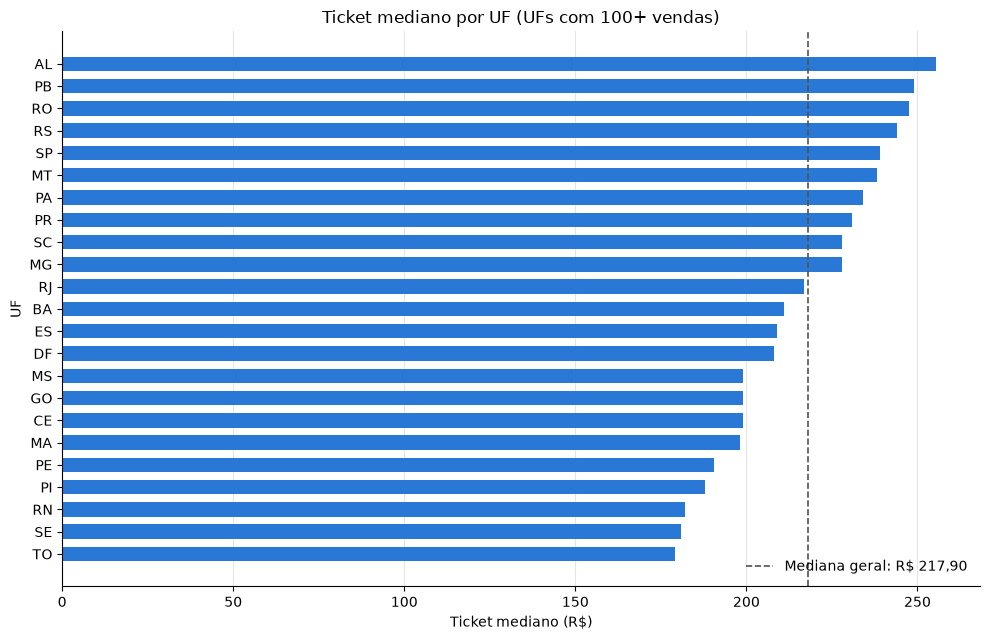

In [96]:
dados = uf_relevantes.sort_values("ticket_mediano")
mediana_geral = vendas_validas["ValorVenda"].median()
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(dados.index.astype(str), dados["ticket_mediano"], color=COR_PRINCIPAL, height=0.65)
ax.axvline(mediana_geral, color=COR_TEXTO, linestyle="--", linewidth=1.2,
           label=f"Mediana geral: R$ {mediana_geral:,.2f}".replace(".", ","))
ax.legend(frameon=False, loc="lower right")
estilo_eixo(ax, "Ticket mediano por UF (UFs com 100+ vendas)", "Ticket mediano (R$)", "UF", "x")
plt.tight_layout()
plt.show()

**Conclusão:**

- **Concentração de volume:** o Sudeste responde por **48,6%** das vendas, e São Paulo sozinho por 27%.
- **Ticket por região:** Sudeste e Sul têm ticket mediano de R$ 233, contra R$ 199 no Nordeste e R$ 208 no Norte e no Centro-Oeste.
- **A região esconde diferenças internas relevantes:** os três maiores tickets medianos são de estados fora do eixo Sul-Sudeste — **Alagoas (R$ 255,50), Paraíba (R$ 249) e Rondônia (R$ 247,50)** — enquanto Rio Grande do Norte, Sergipe e Tocantins têm os menores (cerca de R$ 180). Uma estratégia só por região trataria AL e RN da mesma forma, mas os tickets são muito diferentes.
- **Média engana em UFs pequenas:** Rondônia tem ticket **médio** de R$ 467, o maior do país, mas mediana de R$ 247,50. A diferença vem de poucas vendas de valor muito alto, o que mostra por que a mediana é a medida mais segura para comparar estados com pouco volume.
- **Meio de pagamento:** o uso de **boleto** é maior no Norte (34,0%) e no Nordeste (30,1%) do que no Sudeste (23,3%). Tocantins (39,6%) e Mato Grosso (36,8%) lideram, e o Rio Grande do Norte (20,0%) e São Paulo (22,5%) têm os menores índices. Onde o boleto pesa mais, o parcelamento pesa menos (Tocantins: 45,4% parcelado, contra 62,0% em São Paulo).

**Implicação:** condições de pagamento (desconto no boleto, número de parcelas) deveriam ser pensadas por **UF**, e não só por região. Uma hipótese a investigar com dados externos, que esta base não traz, é a relação entre renda e acesso a crédito.

## 9.6 Descoberta livre: um único cliente distorce agosto, o canal HiMidia e o indicador de repetições

### O que foi encontrado

Um **único cliente** (código `618107`, do Ceará) fez **236 compras em dois meses**, 221 delas em agosto de 2011. As compras seguem um padrão muito uniforme:

- **100% pelo canal HiMidia.**
- **233 de 236 em boleto.**
- **83% no mesmo valor**, R$ 109,00.
- **Até 33 compras em um único dia.**

Esse cliente sozinho responde por **51,5% das vendas do canal HiMidia em agosto**, **18,4% de todas as possíveis repetições** da base e **5,8% de todas as vendas de agosto**.

### Como se chegou nele

A descoberta surgiu do **cruzamento de três *flags* independentes**, criadas por motivos diferentes:

- Na seção 3.12, um cliente se destacou pelo volume de compras (`flag_cliente_atipico`).
- Na seção 3.10, o mesmo código aparecia com frequência entre as possíveis repetições (`flag_possivel_repeticao`).
- Na seção 9.4, a concentração do canal HiMidia apontava para clientes atípicos.

A pergunta natural foi: **esses sinais são o mesmo fenômeno?** A investigação abaixo segue o cliente ao longo do tempo.

In [97]:
# Cliente com maior número de compras (identificado por regra, sem código fixo)
cliente_top = df_clean["Cliente_Codigo"].value_counts().index[0]
compras_top = df_clean[df_clean["Cliente_Codigo"] == cliente_top]

print(f"Cliente: {cliente_top}")
print(f"Compras: {len(compras_top)} | de {compras_top['DataVenda'].min():%d/%m/%Y} a {compras_top['DataVenda'].max():%d/%m/%Y}")
print(f"UF: {compras_top['UF_Cliente'].astype(str).unique().tolist()} | "
      f"Canais: {compras_top['CanalVenda_Normalizado'].value_counts().to_dict()}")
print(f"Formas de pagamento: {compras_top['FormaPagamento'].astype(str).value_counts().to_dict()}")
print(f"Valor mais frequente: R$ {compras_top['ValorVenda'].mode().iloc[0]:.2f} "
      f"({(compras_top['ValorVenda'] == compras_top['ValorVenda'].mode().iloc[0]).mean() * 100:.0f}% das compras)")
print(f"Marcadas como possível repetição: {compras_top['flag_possivel_repeticao'].sum()} "
      f"({compras_top['flag_possivel_repeticao'].sum() / df_clean['flag_possivel_repeticao'].sum() * 100:.1f}% "
      f"de todas as repetições da base)")

print("\nCompras por mês:")
print(compras_top.groupby("AnoMes").size().to_string())
print("\nDias com mais compras:")
print(compras_top["DataVenda"].dt.date.value_counts().head(5).to_string())

Cliente: 618107
Compras: 236 | de 22/06/2011 a 22/08/2011
UF: ['CE'] | Canais: {'himidia': 236}
Formas de pagamento: {'Boleto Bancário': 233, 'Visa': 3}
Valor mais frequente: R$ 109.00 (83% das compras)
Marcadas como possível repetição: 164 (18.4% de todas as repetições da base)

Compras por mês:
AnoMes
2011-06      1
2011-07     14
2011-08    221

Dias com mais compras:
DataVenda
2011-08-20    33
2011-08-13    20
2011-08-16    20
2011-08-15    19
2011-08-04    13


,Cliente atípico,Demais clientes,%_cliente_atipico
AnoMes,,,
2011-01,0,75,0.00
2011-02,0,72,0.00
2011-03,0,91,0.00
2011-04,0,94,0.00
2011-05,0,178,0.00
2011-06,1,350,0.30
2011-07,14,274,4.90
2011-08,221,208,51.50


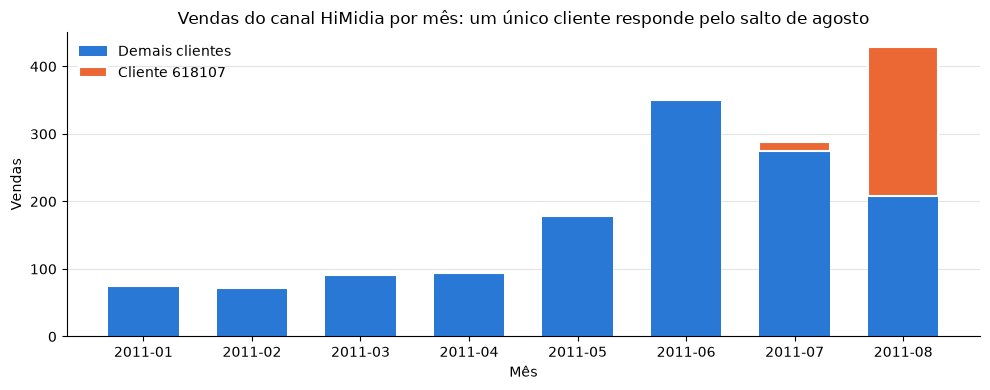

In [98]:
# Evidência 1: a evolução mensal do canal HiMidia, separando o cliente das demais vendas
himidia_mes = pd.crosstab(df_clean.loc[himidia, "AnoMes"],
                          np.where(df_clean.loc[himidia, "Cliente_Codigo"] == cliente_top,
                                   "Cliente atípico", "Demais clientes"))
himidia_mes.columns.name = None
himidia_mes["%_cliente_atipico"] = (himidia_mes["Cliente atípico"] / himidia_mes.sum(axis=1) * 100).round(1)
display(himidia_mes)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(himidia_mes.index, himidia_mes["Demais clientes"], color=COR_PRINCIPAL, width=0.65, label="Demais clientes")
ax.bar(himidia_mes.index, himidia_mes["Cliente atípico"], bottom=himidia_mes["Demais clientes"],
       color=COR_SECUNDARIA, width=0.65, label=f"Cliente {cliente_top}", edgecolor="white", linewidth=1.5)
ax.legend(frameon=False, loc="upper left")
estilo_eixo(ax, "Vendas do canal HiMidia por mês: um único cliente responde pelo salto de agosto",
            "Mês", "Vendas")
plt.tight_layout()
plt.show()

In [99]:
# Evidência 2: efeito sobre a evolução geral de agosto (9.1)
agosto = evolucao.index.max()
vendas_ago_sem = (df_clean["AnoMes"].eq(agosto) & df_clean["Cliente_Codigo"].ne(cliente_top)).sum()
print(f"{agosto}: {evolucao.loc[agosto, 'vendas_por_dia']:.1f} vendas/dia com o cliente | "
      f"{vendas_ago_sem / evolucao.loc[agosto, 'dias_com_venda']:.1f} sem o cliente")
print(f"Participação do cliente nas vendas de {agosto}: "
      f"{(compras_top['AnoMes'] == agosto).sum() / evolucao.loc[agosto, 'vendas'] * 100:.1f}%")

2011-08: 135.6 vendas/dia com o cliente | 127.7 sem o cliente
Participação do cliente nas vendas de 2011-08: 5.8%


### Da descoberta à regra: a *flag* de rajada de compras

Um achado só é útil para o *pipeline* se virar uma **regra genérica**, que funcione sem citar o código do cliente. Foi esta investigação que motivou a *flag* `flag_rajada_compras` (5 ou mais compras do mesmo cliente no mesmo dia). Para que a base preparada estivesse completa **antes** das análises, a regra foi registrada no *profiling* (3.12) e aplicada junto com as demais *flags* de cliente (6.6). Aqui ela é usada para verificar se o comportamento descoberto é isolado ou se repete em outros clientes.

In [100]:
distribuicao = (df_clean.groupby(["Cliente_Codigo", df_clean["DataVenda"].dt.normalize()]).size()
                .value_counts().sort_index())
dist_tab = pd.DataFrame({"pares_cliente_dia": distribuicao,
                         "%_acumulado": (distribuicao.cumsum() / distribuicao.sum() * 100).round(3)})
display(dist_tab.head(8).T)

rajada = df_clean["flag_rajada_compras"]
print(f"Vendas em rajada: {rajada.sum()} | clientes: {df_clean.loc[rajada, 'Cliente_Codigo'].nunique()} | "
      f"das quais do cliente {cliente_top}: {(rajada & df_clean['Cliente_Codigo'].eq(cliente_top)).sum()}")
print(f"Boleto nas vendas em rajada: {(df_clean.loc[rajada, 'FormaPagamento'] == 'Boleto Bancário').mean() * 100:.1f}% "
      f"| na base: {(df_clean['FormaPagamento'] == 'Boleto Bancário').mean() * 100:.1f}%")
print(f"Possível repetição nas vendas em rajada: {df_clean.loc[rajada, 'flag_possivel_repeticao'].mean() * 100:.1f}% "
      f"| na base: {df_clean['flag_possivel_repeticao'].mean() * 100:.1f}%")

,1,2,3,4,5,6,7,8
pares_cliente_dia,"22,907.00","1,744.00",301.00,116.00,49.00,13.00,5.00,9.00
%_acumulado,91.02,97.95,99.14,99.60,99.80,99.85,99.87,99.91


Vendas em rajada: 742 | clientes: 64 | das quais do cliente 618107: 215
Boleto nas vendas em rajada: 37.1% | na base: 26.4%
Possível repetição nas vendas em rajada: 36.7% | na base: 3.1%


**Evidência e interpretação:**

- **O "crescimento" do HiMidia em agosto é ilusório.** Pelo total, o canal sobe de 288 vendas em julho para 429 em agosto (+49%). Separando o cliente, as vendas dos **demais clientes caem** de 274 para 208 (−24%). As duas leituras levam a decisões opostas: ampliar ou rever o investimento no canal.
- **Agosto também muda:** sem esse cliente, a média do mês cai de 135,6 para 127,7 vendas por dia.
- **O padrão não é isolado.** Comprar 5 ou mais vezes no mesmo dia acontece em apenas 0,4% dos pares cliente-dia (99,6% ficam em até 4 compras). Mesmo assim, a regra encontra **742 vendas de 64 clientes**, 215 delas do cliente descoberto. Nessas "rajadas", o boleto sobe para 37,1% (contra 26,4% na base) e a possível repetição para 36,7% (contra 3,1%).

**Por que é relevante:**

- **Pode superestimar o faturamento.** Rajadas de boletos do mesmo valor sugerem boletos emitidos e não pagos, reemissões, contas de teste, revenda ou fraude. A base não tem **status de pagamento**, então não é possível saber quantas dessas vendas se converteram em receita. Esta é a principal recomendação à área de negócio: incluir o status do pedido na próxima extração.
- **Distorce a avaliação de parceiros.** Se o HiMidia for remunerado por venda, o parceiro estaria recebendo por um volume concentrado em um único comprador com comportamento atípico.
- **Virou regra do *pipeline*.** O achado foi transformado em `flag_rajada_compras` (aplicada em 6.6), genérica e parametrizada (`compras_mesmo_dia_rajada = 5`), que detecta o mesmo comportamento em qualquer carga futura, sem depender do código deste cliente.

A descoberta mostra o valor de **cruzar *flags*** criadas por motivos independentes: sozinhas, elas indicavam "um cliente que compra muito" e "algumas vendas repetidas". Juntas, revelaram um fenômeno que muda a leitura de um canal e de um mês.

# 10. Geração da base final

## 10.1 Seleção de colunas

A base final reúne, em blocos, tudo o que a análise precisa:

| Bloco | Colunas | Justificativa |
|---|---|---|
| Rastreabilidade | `id_registro` | Liga cada linha ao RAW e ao *log* de alterações |
| Originais tratadas | `DataVenda`, `ValorVenda`, `IdFormaDePagamento`, `FormaPagamento`, `TipoFormaPagamento`, `NumeroParcelas`, `Cliente_Codigo`, `Cliente_Data_Nascimento`, `UF_Cliente` | Os fatos da venda, já com tipos corrigidos, datas inválidas como ausentes e valores em centavos |
| Canal | `CanalVenda_Original`, `CanalVenda_Normalizado`, `CanalVenda_Midia`, `GrupoCanal` | O texto bruto é preservado ao lado das versões analisáveis, exigência do trabalho e garantia de auditoria |
| Datas derivadas | `Ano`, `Mes`, `AnoMes`, `Dia`, `DiaSemana`, `FimDeSemana`, `Hora`, `PeriodoDia` | Evita que cada usuário recalcule, com risco de regras diferentes |
| Cliente e geografia | `IdadeNaCompra`, `FaixaEtaria`, `Regiao` | Idade na data da compra, faixas documentadas (7.2) e região (7.6) |
| Pagamento | `ModalidadePagamento`, `ValorParcela` | Leitura direta do parcelamento |
| Qualidade | as 11 colunas `flag_*` | Permitem que cada análise decida o que filtrar, com transparência |

**Colunas excluídas:** nenhuma informação foi descartada. A coluna `CanalVenda` não aparece com esse nome porque foi **renomeada** para `CanalVenda_Original`, com conteúdo idêntico (verificado por `assert` em 7.5). As séries auxiliares de diagnóstico (`aux_*`) não fazem parte do `df_clean`.

**Registros eliminados:** apenas 1, a cópia da duplicata exata (6.2).

In [101]:
COLUNAS_FINAIS = [
    "id_registro",
    "DataVenda", "ValorVenda", "IdFormaDePagamento", "FormaPagamento", "TipoFormaPagamento", "NumeroParcelas",
    "Cliente_Codigo", "Cliente_Data_Nascimento", "UF_Cliente", "Regiao",
    "CanalVenda_Original", "CanalVenda_Normalizado", "CanalVenda_Midia", "GrupoCanal",
    "Ano", "Mes", "AnoMes", "Dia", "DiaSemana", "FimDeSemana", "Hora", "PeriodoDia",
    "IdadeNaCompra", "FaixaEtaria",
    "ModalidadePagamento", "ValorParcela",
    "flag_nascimento_invalido", "flag_idade_improvavel", "flag_valor_zero", "flag_valor_extremo",
    "flag_pagamento_inconsistente", "flag_parcelas_zero", "flag_possivel_repeticao", "flag_rajada_compras",
    "flag_cliente_atipico", "flag_cliente_multi_uf", "flag_canal_multiplo",
]
faltando = set(df_clean.columns) - set(COLUNAS_FINAIS)
assert not faltando, f"Colunas do df_clean fora da base final: {faltando}"

df_final = df_clean[COLUNAS_FINAIS].reset_index(drop=True)
print(f"Base final: {df_final.shape[0]:,} linhas x {df_final.shape[1]} colunas")
print(f"Flags de qualidade: {sum(c.startswith('flag_') for c in COLUNAS_FINAIS)}")

Base final: 28,504 linhas x 38 colunas
Flags de qualidade: 11


## 10.2 Gravação do arquivo

Os parâmetros de gravação são **explícitos**, e seguem o mesmo padrão do arquivo de origem para facilitar a abertura em planilhas configuradas em português:

- `sep=";"` e `decimal=","`: padrão brasileiro. Evita conflito entre a vírgula decimal e o separador de campos.
- `encoding="utf-8-sig"`: UTF-8 com BOM, para que os acentos apareçam corretamente no Excel.
- `date_format="%Y-%m-%d %H:%M:%S"`: formato ISO, sem ambiguidade entre dia e mês. A data de nascimento, que não tem hora, é gravada como `AAAA-MM-DD`.
- `index=False`: o índice do `pandas` não é informação da venda; a rastreabilidade está em `id_registro`.

In [102]:
NOME_ARQUIVO_FINAL = "BaseVendasXPTO_CLEAN_Vinicius_Machado.csv"
PARAMETROS_GRAVACAO = {"sep": ";", "decimal": ",", "encoding": "utf-8-sig", "index": False,
                       "date_format": "%Y-%m-%d %H:%M:%S"}

# Nascimento é uma data sem hora: gravado como AAAA-MM-DD (as demais datas usam date_format)
saida = df_final.copy()
saida["Cliente_Data_Nascimento"] = saida["Cliente_Data_Nascimento"].dt.strftime("%Y-%m-%d")
saida.to_csv(NOME_ARQUIVO_FINAL, **PARAMETROS_GRAVACAO)
print(f"Arquivo gravado: {NOME_ARQUIVO_FINAL}")

# No Google Colab, descomente a linha abaixo para baixar o arquivo
# from google.colab import files; files.download(NOME_ARQUIVO_FINAL)

Arquivo gravado: BaseVendasXPTO_CLEAN_Vinicius_Machado.csv


## 10.3 Verificação: o arquivo relido é igual à base final?

Um arquivo gravado só é confiável se **relido com os mesmos parâmetros reproduzir a base**. A verificação compara quantidade de linhas e colunas, soma dos valores, ausentes por coluna e contagem das *flags*.

In [103]:
releitura = pd.read_csv(NOME_ARQUIVO_FINAL, sep=";", decimal=",", encoding="utf-8-sig",
                        keep_default_na=False, na_values=[""])

assert releitura.shape == df_final.shape, "Dimensões divergentes"
assert list(releitura.columns) == COLUNAS_FINAIS, "Colunas divergentes"
assert np.isclose(releitura["ValorVenda"].sum(), df_final["ValorVenda"].sum()), "Soma de valores divergente"
assert releitura.isna().sum().equals(df_final.isna().sum()), "Ausentes divergentes"
flags_finais = [c for c in COLUNAS_FINAIS if c.startswith("flag_") and c != "flag_nascimento_invalido"]
assert (releitura[flags_finais].sum() == df_final[flags_finais].sum()).all(), "Flags divergentes"

import os
print(f"Releitura consistente: {releitura.shape[0]:,} linhas x {releitura.shape[1]} colunas | "
      f"tamanho {os.path.getsize(NOME_ARQUIVO_FINAL) / 1024**2:.2f} MB")
releitura.head(3)

Releitura consistente: 28,504 linhas x 38 colunas | tamanho 7.01 MB


,id_registro,DataVenda,ValorVenda,IdFormaDePagamento,FormaPagamento,TipoFormaPagamento,NumeroParcelas,Cliente_Codigo,Cliente_Data_Nascimento,UF_Cliente,Regiao,CanalVenda_Original,CanalVenda_Normalizado,CanalVenda_Midia,GrupoCanal,Ano,Mes,AnoMes,Dia,DiaSemana,FimDeSemana,Hora,PeriodoDia,IdadeNaCompra,FaixaEtaria,ModalidadePagamento,ValorParcela,flag_nascimento_invalido,flag_idade_improvavel,flag_valor_zero,flag_valor_extremo,flag_pagamento_inconsistente,flag_parcelas_zero,flag_possivel_repeticao,flag_rajada_compras,flag_cliente_atipico,flag_cliente_multi_uf,flag_canal_multiplo
0,0,2011-05-05 12:14:00,69.00,1,Boleto Bancário,Boleto Bancário,1,1,2008-01-01,RJ,Sudeste,UOLBOTAOMAR,uolbotaomar,NaN,Portais e mídia display,2011,5,2011-05,5,Quinta,False,12,Tarde,3.00,Idade improvável,À vista,69.00,NaN,True,False,False,False,False,False,False,False,False,False
1,1,2011-05-10 16:20:00,442.80,1,Boleto Bancário,Boleto Bancário,1,1,2008-01-01,RJ,Sudeste,Opote,opote,NaN,Outros parceiros,2011,5,2011-05,10,Terça,False,16,Tarde,3.00,Idade improvável,À vista,442.80,NaN,True,False,False,False,False,False,False,False,False,False
2,2,2011-05-15 22:42:00,269.00,1,Boleto Bancário,Boleto Bancário,1,1,2008-01-01,RJ,Sudeste,NaN,nao informado,NaN,Não informado,2011,5,2011-05,15,Domingo,True,22,Noite,3.00,Idade improvável,À vista,269.00,NaN,True,False,False,False,False,False,False,False,False,False


# 11. Pergunta final sobre produção

## 11.1 "Se amanhã chegarem mais 1 milhão de registros no mesmo formato, o pipeline funciona sem intervenção manual?"

**Em grande parte sim, mas não com segurança suficiente para produção.** A resposta depende de separar o que já é genérico do que ainda depende de um analista.

**O que já funcionaria sem intervenção:**

- **Leitura:** os parâmetros são explícitos e os marcadores de ausência são declarados (1.4).
- **Regras parametrizadas:** ficam em `PARAMETROS_REGRAS`, sem índices de linha nem códigos de cliente fixos.
- **Limites estatísticos recalculados:** IQR e percentil de clientes atípicos se ajustam aos novos dados.
- **Canais novos:** caem em `Não mapeado`, em vez de gerar erro ou ser classificados errado.
- **Formas de pagamento novas:** um Id novo é marcado por `flag_pagamento_inconsistente`.

**O que exigiria intervenção ou poderia falhar em silêncio:**

- **Dicionários mantidos à mão:** `REGRAS_GRUPO_CANAL`, `CORRECOES_GRAFIA` e `DOMINIO_PAGAMENTO`. Um canal novo relevante ficaria em "Não mapeado" até alguém classificá-lo.
- **Limites que mudam a cada carga:** o limite de valor extremo e o de cliente atípico são recalculados em cada execução. Isso é bom para adaptação, mas **torna as *flags* incomparáveis entre cargas**. Em produção, os limites deveriam ser calculados sobre uma base de referência e versionados.
- **Regras que dependem do histórico:** repetições, rajadas e clientes atípicos olham para outras vendas do mesmo cliente. Se a carga for incremental, uma repetição que atravessa dois lotes não seria detectada.
- **Duplicatas entre cargas:** a remoção de duplicatas só compara registros do mesmo lote. Reprocessar um arquivo já carregado duplicaria vendas.
- **Células exploratórias:** as células de descoberta da seção 1 (leitura byte a byte, contagem de separadores) são diagnóstico, não *pipeline*. Em produção, os parâmetros descobertos viram **contrato**.

## 11.2 O que mudaria em produção

- **Modularização em funções e scripts:** o notebook documenta a descoberta; a produção precisa de um pacote Python com uma função por etapa (`ler`, `validar`, `limpar`, `derivar`, `gravar`) e uma função `executar_pipeline(caminho_entrada)` que as encadeia. As funções deste notebook (`perfilar_coluna`, `normalizar_canal`, `classificar_canal`, `idade_na_data`, `marcar_repeticoes`) já são quase reutilizáveis.
- **Validação de *schema*:** antes de qualquer transformação, o arquivo seria validado contra um contrato (nomes e ordem das colunas, tipos, formatos de data, domínios de UF e pagamento), com bibliotecas como `pandera` ou `great_expectations`. Um arquivo fora do contrato é **rejeitado com mensagem clara**, em vez de processado de forma errada.
- **Testes de qualidade automatizados:** os `assert` deste notebook virariam testes (`pytest`), com dois tipos. **Testes de unidade**, como o do aniversário em 7.2, para as funções. **Testes de dados**, com limites de alerta, por exemplo "a proporção de canal ausente não pode passar de 40%" ou "nenhuma data de venda no futuro".
- **Categorias novas de canal:** a tabela de regras sairia do código para um arquivo de configuração (CSV ou YAML) mantido pelo marketing. A cada carga, a lista de valores em "Não mapeado" seria **enviada automaticamente** para classificação, com a participação nas vendas, para priorizar os canais mais relevantes.
- ***Logs*:** o `log_etapas` e o `log_registros` seriam gravados em arquivo ou tabela, com data da execução, versão do código e identificador da carga, trocando `print` pelo módulo `logging`.
- **Orquestração:** um orquestrador (Airflow, Prefect ou um agendador simples) executaria as etapas em ordem, com novas tentativas em caso de falha de rede na leitura, alertas e dependências entre tarefas.
- **Versionamento de dados:** o arquivo RAW de cada carga seria armazenado **imutável** (com *hash*, como em 1.5), e as bases CLEAN versionadas (DVC, *snapshots* de tabela). Qualquer número publicado poderia ser reproduzido a partir de uma versão específica dos dados e do código.
- **Performance e memória:** 1 milhão de linhas é cerca de 35 vezes esta base. Cabe na memória de uma máquina comum, mas três pontos pediriam ajuste:
  - As funções aplicadas linha a linha em Python (`normalizar_canal`, `classificar_canal`, `arredondar_comercial`) deveriam ser aplicadas **só aos valores distintos** e depois mapeadas de volta. Há centenas de canais distintos contra milhões de linhas.
  - A leitura deveria declarar `dtype` por coluna (e usar `category` desde o início), ou ser feita em blocos (`chunksize`).
  - Para volumes maiores, formatos colunares como Parquet e bibliotecas como `polars` ou `duckdb` substituiriam o CSV.
- **Monitoramento:** um painel acompanharia, por carga, os indicadores de qualidade: percentual de cada *flag*, volume em "Não mapeado", ausentes por coluna e distribuição de valores. Uma **mudança brusca** geraria alerta. O caso das parcelas zeradas a partir de 10/06/2011 (3.8) teria sido detectado no dia em que surgiu, e não meses depois, numa análise manual.

# Checklist final do trabalho

| Requisito | Onde é atendido | Status |
|---|---|---|
| Leitura direta da URL, sem arquivos intermediários | 1.1, 1.5 | [x] |
| Parâmetros de leitura descobertos e justificados (separador, decimal, *encoding*, ausentes) | 1.2 a 1.5 | [x] |
| Camada RAW intocada (`df_raw`) e verificada por *hash* | 1.5, 7.7 | [x] |
| Nº de registros, atributos, nomes, tipos, memória e período | 2.1 a 2.4 | [x] |
| Resposta sobre a adequação dos tipos inferidos | 2.5 | [x] |
| *Profiling* por atributo consolidado em tabela | 3.2, 3.3 | [x] |
| Busca ativa: ausentes, sentinelas, domínio, datas, duplicidades, extremos, inconsistências entre colunas, granularidade | 3.4 a 3.13 | [x] |
| Tabela de Qualidade com pelo menos 8 ocorrências e severidade | 4.1 (16 ocorrências) | [x] |
| Pelo menos 5 decisões classificadas de A a E, com tabela resumo | 5.2 a 5.11 (14 decisões) | [x] |
| `df_clean` criado por cópia, com contagens antes e depois | 6.1 a 6.6 | [x] |
| *Log* de registros modificados e removidos, com motivo | 6.1, 7.7 | [x] |
| 7.1 Datas derivadas e justificadas | 7.1 | [x] |
| 7.2 Idade na data da compra, investigação e faixa etária documentada | 7.2 | [x] |
| 7.3 Valores monetários: extremos, IQR e decisões | 7.3 | [x] |
| 7.4 Pagamento: consistência e *flags* | 7.4 | [x] |
| 7.5 Canal: `CanalVenda_Original`, `CanalVenda_Normalizado`, `GrupoCanal` e tabela de mapeamento | 7.5 | [x] |
| Resumo de transformações, variáveis novas, modificados e removidos | 7.7 | [x] |
| Comparação RAW × CLEAN com 3+ indicadores e tabela | 8.1, 8.2 | [x] |
| Resposta: alguma decisão gerencial seria diferente? | 8.3 | [x] |
| Perguntas de negócio 9.1 a 9.5 usando somente `df_clean` | 9.1 a 9.5 | [x] |
| Descoberta livre com evidência e relevância | 9.6 | [x] |
| Base final com originais, transformados, derivados e *flags* | 10.1 | [x] |
| Arquivo `BaseVendasXPTO_CLEAN_Vinicius_Machado.csv` com separador e decimal explícitos | 10.2, 10.3 | [x] |
| Discussão sobre produção | 11.1, 11.2 | [x] |
| Execução do início ao fim em ambiente limpo, sem valores "chumbados" de linhas | Todo o notebook | [x] |